# CellSense
## Intelligent Monitoring & Predictive Maintenance

### Project Overview

CellSense is an end-to-end Data Science project focused on industrial machine failure risk assessment through statistical analysis, physics-informed feature engineering, machine learning, and explainable artificial intelligence.

### Project Objectives

- Investigate industrial operating conditions and failure patterns.
- Identify statistically significant indicators of machine failure.
- Develop physics-informed features.
- Build, compare, and optimize machine learning models.
- Address class imbalance and minimize missed failures.
- Detect anomalous operating conditions.
- Interpret model predictions using Explainable AI.

### Dataset

- **Name:** AI4I 2020 Predictive Maintenance Dataset
- **Source:** UCI Machine Learning Repository
- **Instances:** 10,000
- **Data Type:** Synthetic industrial operational data
- **Task:** Binary Classification

[Dataset Source](https://archive.ics.uci.edu/dataset/601/ai4i+2020+predictive+maintenance+dataset)

### Project Limitations

The dataset contains synthetic industrial data. Model predictions represent failure risk under observed operating conditions rather than the exact time of future machine failure.


## 1. Environment Setup and Imports

Install and import the necessary Python libraries for data analysis, statistical testing, machine learning, optimization, and model explainability.


In [1]:
!pip install -q ucimlrepo xgboost lightgbm optuna shap imbalanced-learn


In [2]:
# Data manipulation
import pandas as pd
import numpy as np

# Data visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Statistical analysis
from scipy import stats

# Dataset acquisition
from ucimlrepo import fetch_ucirepo

# Configuration
RANDOM_STATE = 42

np.random.seed(RANDOM_STATE)

sns.set_theme(style="whitegrid")
pd.set_option("display.max_columns", None)

print("Libraries imported successfully!")


Libraries imported successfully!


## 2. Data Loading and Understanding

Load the AI4I 2020 dataset and examine its structure, operational features, target variables, and data quality.


In [3]:
# Load the dataset
dataset = fetch_ucirepo(id=601)

# Extract features and targets
X_raw = dataset.data.features.copy()
y_raw = dataset.data.targets.copy()

# Combine data for exploratory analysis
df = pd.concat([X_raw, y_raw], axis=1)

print("Dataset loaded successfully!")
print(f"Number of observations: {df.shape[0]}")
print(f"Number of columns: {df.shape[1]}")

display(df.head())


Dataset loaded successfully!
Number of observations: 10000
Number of columns: 12


,Type,Air temperature,Process temperature,Rotational speed,Torque,Tool wear,Machine failure,TWF,HDF,PWF,OSF,RNF
0,M,298.1,308.6,1551,42.8,0,0,0,0,0,0,0
1,L,298.2,308.7,1408,46.3,3,0,0,0,0,0,0
2,L,298.1,308.5,1498,49.4,5,0,0,0,0,0,0
3,L,298.2,308.6,1433,39.5,7,0,0,0,0,0,0
4,L,298.2,308.7,1408,40.0,9,0,0,0,0,0,0


### 2.1 Data Quality Assessment

Before performing statistical analysis and developing machine learning models, the dataset is evaluated for missing values, duplicate observations, data types, and variable distributions.


In [4]:
# Generate a comprehensive data quality report
quality_report = pd.DataFrame({
    "Data Type": df.dtypes,
    "Missing Values": df.isnull().sum(),
    "Missing (%)": df.isnull().mean() * 100,
    "Unique Values": df.nunique()
})

display(quality_report)

print("Duplicate rows:", df.duplicated().sum())
print("Total missing values:", df.isnull().sum().sum())

,Data Type,Missing Values,Missing (%),Unique Values
Type,object,0,0.0,3
Air temperature,float64,0,0.0,93
Process temperature,float64,0,0.0,82
Rotational speed,int64,0,0.0,941
Torque,float64,0,0.0,577
Tool wear,int64,0,0.0,246
Machine failure,int64,0,0.0,2
TWF,int64,0,0.0,2
HDF,int64,0,0.0,2
PWF,int64,0,0.0,2


Duplicate rows: 0
Total missing values: 0


In [5]:
# Dataset variable descriptions
display(dataset.variables)

,name,role,type,demographic,description,units,missing_values
0,UID,ID,Integer,None,None,None,no
1,Product ID,ID,Categorical,None,None,None,no
2,Type,Feature,Categorical,None,None,None,no
3,Air temperature,Feature,Continuous,None,None,K,no
4,Process temperature,Feature,Continuous,None,None,K,no
5,Rotational speed,Feature,Integer,None,None,rpm,no
6,Torque,Feature,Continuous,None,None,Nm,no
7,Tool wear,Feature,Integer,None,None,min,no
8,Machine failure,Target,Integer,None,None,None,no
9,TWF,Target,Integer,None,None,None,no


In [6]:
# Descriptive statistics
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Type,10000,3,L,6000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Air temperature,10000.0,NaN,NaN,NaN,300.00493,2.000259,295.3,298.3,300.1,301.5,304.5
Process temperature,10000.0,NaN,NaN,NaN,310.00556,1.483734,305.7,308.8,310.1,311.1,313.8
Rotational speed,10000.0,NaN,NaN,NaN,1538.7761,179.284096,1168.0,1423.0,1503.0,1612.0,2886.0
Torque,10000.0,NaN,NaN,NaN,39.98691,9.968934,3.8,33.2,40.1,46.8,76.6
Tool wear,10000.0,NaN,NaN,NaN,107.951,63.654147,0.0,53.0,108.0,162.0,253.0
Machine failure,10000.0,NaN,NaN,NaN,0.0339,0.180981,0.0,0.0,0.0,0.0,1.0
TWF,10000.0,NaN,NaN,NaN,0.0046,0.067671,0.0,0.0,0.0,0.0,1.0
HDF,10000.0,NaN,NaN,NaN,0.0115,0.106625,0.0,0.0,0.0,0.0,1.0
PWF,10000.0,NaN,NaN,NaN,0.0095,0.097009,0.0,0.0,0.0,0.0,1.0


## 3. Exploratory Data Analysis (EDA)

Exploratory Data Analysis is conducted to identify patterns, relationships, operating conditions, and potential indicators associated with machine failures.

### 3.1 Target Variable Distribution

Analyze the distribution of machine failure events and evaluate the degree of class imbalance.


In [7]:
# Analyze target distribution
failure_counts = df["Machine failure"].value_counts().sort_index()

failure_percentages = (
    df["Machine failure"]
    .value_counts(normalize=True)
    .sort_index() * 100
)

target_summary = pd.DataFrame({
    "Count": failure_counts,
    "Percentage (%)": failure_percentages.round(2)
})

target_summary.index = ["No Failure", "Failure"]

display(target_summary)

,Count,Percentage (%)
No Failure,9661,96.61
Failure,339,3.39


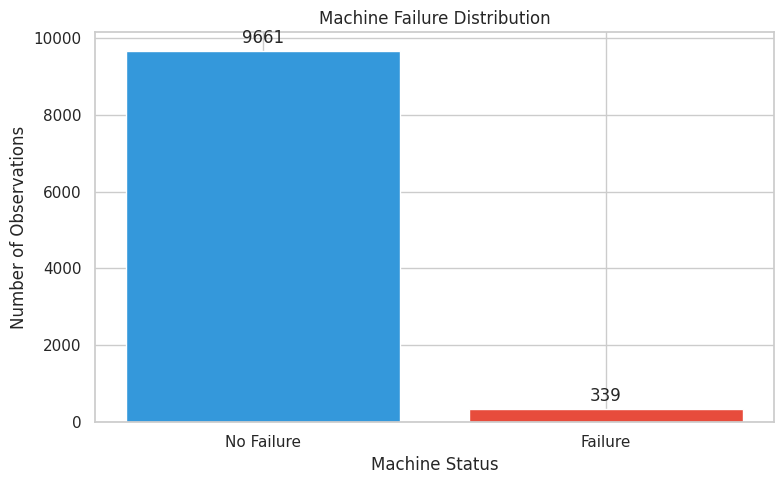

In [8]:
# Visualize target distribution
fig, ax = plt.subplots(figsize=(8, 5))

bars = ax.bar(
    target_summary.index,
    target_summary["Count"],
    color=["#3498db", "#e74c3c"]
)

ax.bar_label(bars, padding=3)
ax.set_title("Machine Failure Distribution")
ax.set_xlabel("Machine Status")
ax.set_ylabel("Number of Observations")

plt.tight_layout()
plt.show()

### 2.1 Data Quality Assessment

Assess the dataset quality by examining missing values, duplicate observations, data types, unique values, and descriptive statistics to ensure data reliability before further analysis.


In [9]:
# Generate a data quality report
quality_report = pd.DataFrame({
    "Data Type": df.dtypes,
    "Missing Values": df.isnull().sum(),
    "Missing (%)": df.isnull().mean() * 100,
    "Unique Values": df.nunique()
})

display(quality_report)

print("Duplicate rows:", df.duplicated().sum())
print("Total missing values:", df.isnull().sum().sum())

,Data Type,Missing Values,Missing (%),Unique Values
Type,object,0,0.0,3
Air temperature,float64,0,0.0,93
Process temperature,float64,0,0.0,82
Rotational speed,int64,0,0.0,941
Torque,float64,0,0.0,577
Tool wear,int64,0,0.0,246
Machine failure,int64,0,0.0,2
TWF,int64,0,0.0,2
HDF,int64,0,0.0,2
PWF,int64,0,0.0,2


Duplicate rows: 0
Total missing values: 0


In [10]:
# Examine dataset variable descriptions
display(dataset.variables)

,name,role,type,demographic,description,units,missing_values
0,UID,ID,Integer,None,None,None,no
1,Product ID,ID,Categorical,None,None,None,no
2,Type,Feature,Categorical,None,None,None,no
3,Air temperature,Feature,Continuous,None,None,K,no
4,Process temperature,Feature,Continuous,None,None,K,no
5,Rotational speed,Feature,Integer,None,None,rpm,no
6,Torque,Feature,Continuous,None,None,Nm,no
7,Tool wear,Feature,Integer,None,None,min,no
8,Machine failure,Target,Integer,None,None,None,no
9,TWF,Target,Integer,None,None,None,no


In [11]:
# Generate descriptive statistics
display(df.describe(include="all").T)

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Type,10000,3,L,6000,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Air temperature,10000.0,NaN,NaN,NaN,300.00493,2.000259,295.3,298.3,300.1,301.5,304.5
Process temperature,10000.0,NaN,NaN,NaN,310.00556,1.483734,305.7,308.8,310.1,311.1,313.8
Rotational speed,10000.0,NaN,NaN,NaN,1538.7761,179.284096,1168.0,1423.0,1503.0,1612.0,2886.0
Torque,10000.0,NaN,NaN,NaN,39.98691,9.968934,3.8,33.2,40.1,46.8,76.6
Tool wear,10000.0,NaN,NaN,NaN,107.951,63.654147,0.0,53.0,108.0,162.0,253.0
Machine failure,10000.0,NaN,NaN,NaN,0.0339,0.180981,0.0,0.0,0.0,0.0,1.0
TWF,10000.0,NaN,NaN,NaN,0.0046,0.067671,0.0,0.0,0.0,0.0,1.0
HDF,10000.0,NaN,NaN,NaN,0.0115,0.106625,0.0,0.0,0.0,0.0,1.0
PWF,10000.0,NaN,NaN,NaN,0.0095,0.097009,0.0,0.0,0.0,0.0,1.0


### Data Quality Findings

- No missing values were identified.
- No duplicate observations were detected.
- The dataset contains numerical and categorical variables.
- No missing-value imputation is required.
- Categorical encoding and further preprocessing will be performed before model development.


### 3.2 Train-Test Split

To ensure an unbiased model evaluation, the dataset is
split into training and testing subsets using stratified
sampling.

Further exploratory analysis, statistical testing, feature
selection, and model optimization will be performed using
the training dataset, while the test dataset will remain
reserved for final evaluation.

In [12]:
from sklearn.model_selection import train_test_split

# Create stratified training and testing subsets
train_df, test_df = train_test_split(
    df,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=df["Machine failure"]
)

train_df = train_df.copy()
test_df = test_df.copy()

print(f"Training observations: {len(train_df)}")
print(f"Testing observations: {len(test_df)}")

split_summary = pd.DataFrame({
    "Training (%)": train_df["Machine failure"]
        .value_counts(normalize=True).sort_index() * 100,
    "Testing (%)": test_df["Machine failure"]
        .value_counts(normalize=True).sort_index() * 100
})

split_summary.index = ["No Failure", "Failure"]

display(split_summary.round(2))

Training observations: 8000
Testing observations: 2000


,Training (%),Testing (%)
No Failure,96.61,96.6
Failure,3.39,3.4


In [13]:
print(train_df.columns.tolist())

['Type', 'Air temperature', 'Process temperature', 'Rotational speed', 'Torque', 'Tool wear', 'Machine failure', 'TWF', 'HDF', 'PWF', 'OSF', 'RNF']


### 3.3 Sensor Distribution Analysis

Analyze the distributions of numerical operational
variables to understand their statistical properties,
variability, skewness, and potential extreme values.

These insights will support subsequent statistical
analysis, preprocessing, and feature engineering.

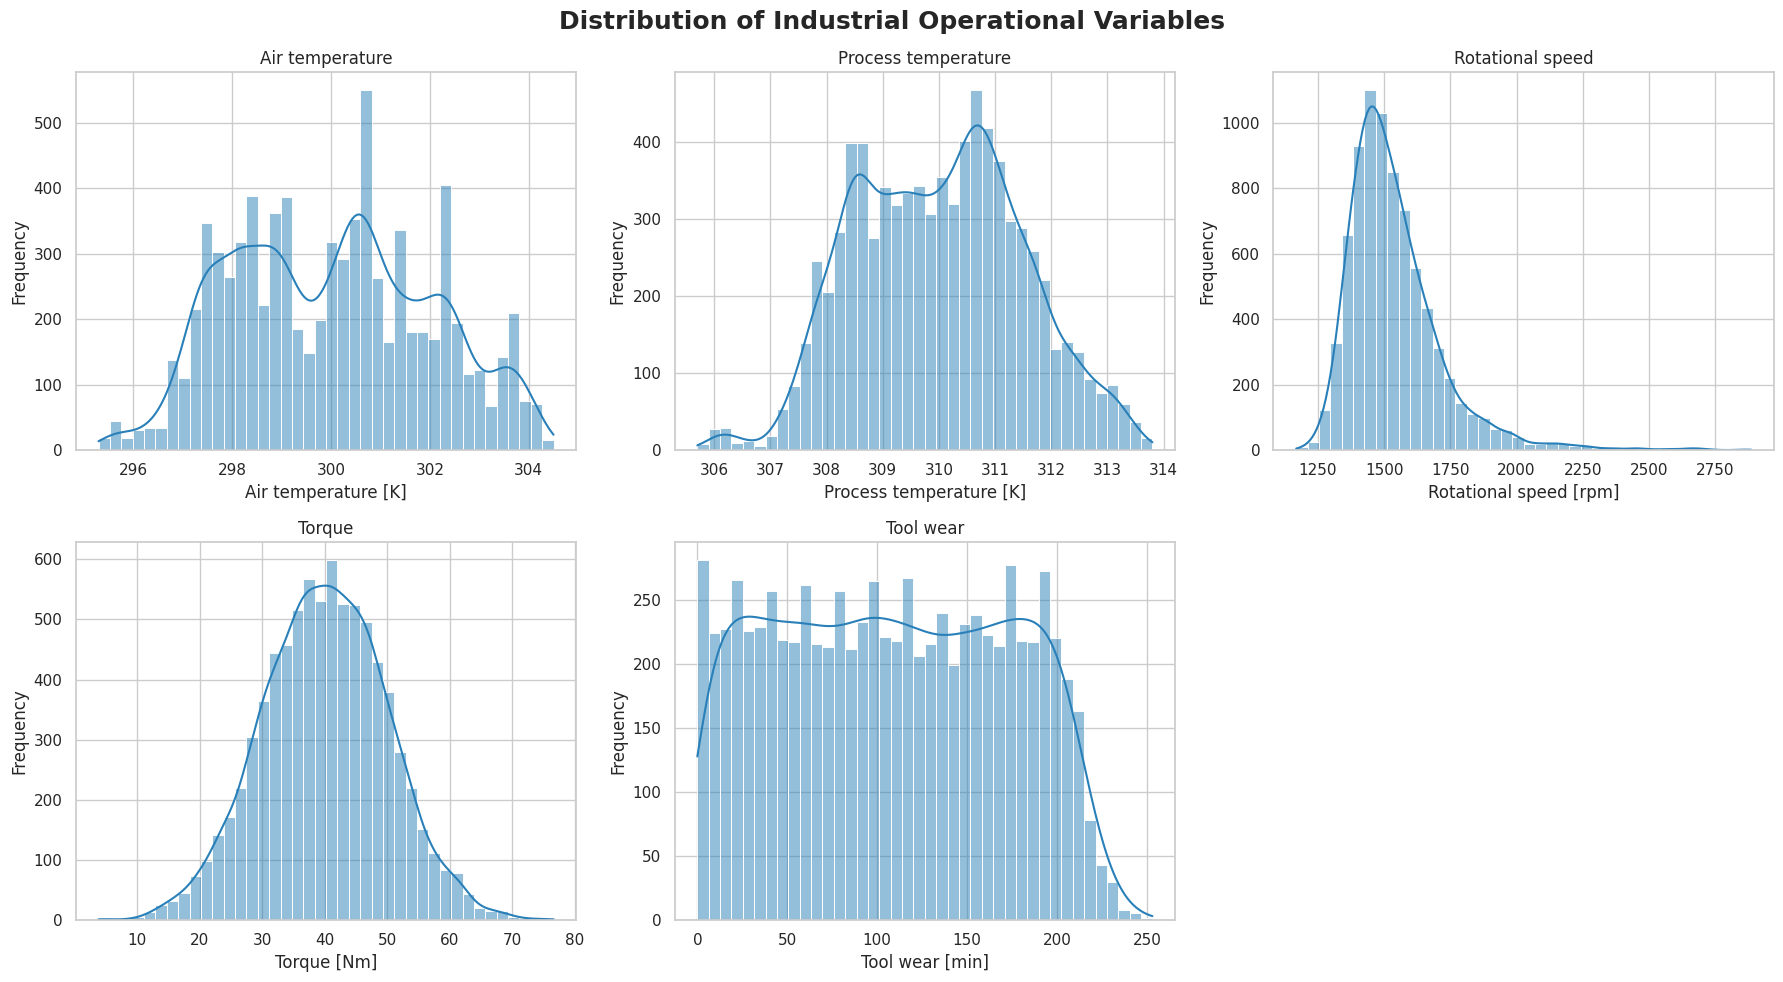

In [14]:
# Define numerical operational features
sensor_columns = [
    "Air temperature",
    "Process temperature",
    "Rotational speed",
    "Torque",
    "Tool wear"
]

# Define measurement units for visualization
sensor_units = {
    "Air temperature": "K",
    "Process temperature": "K",
    "Rotational speed": "rpm",
    "Torque": "Nm",
    "Tool wear": "min"
}

# Visualize numerical feature distributions
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

axes = axes.flatten()

for i, column in enumerate(sensor_columns):
    sns.histplot(
        data=train_df,
        x=column,
        bins=40,
        kde=True,
        color="#2980b9",
        ax=axes[i]
    )

    axes[i].set_title(column, fontsize=12)
    axes[i].set_xlabel(
        f"{column} [{sensor_units[column]}]"
    )
    axes[i].set_ylabel("Frequency")

# Remove unused subplot
fig.delaxes(axes[-1])

fig.suptitle(
    "Distribution of Industrial Operational Variables",
    fontsize=18,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

#### Descriptive Statistics

Calculate descriptive statistics for numerical operational
features to examine central tendency, variability,
distribution asymmetry, and tail behavior.

Skewness and kurtosis are included to provide a deeper
understanding of the underlying feature distributions.

In [15]:
# Calculate descriptive statistics
sensor_statistics = train_df[sensor_columns].describe().T

# Add advanced statistical measures
sensor_statistics["median"] = train_df[sensor_columns].median()
sensor_statistics["variance"] = train_df[sensor_columns].var()
sensor_statistics["skewness"] = train_df[sensor_columns].skew()
sensor_statistics["kurtosis"] = train_df[sensor_columns].kurt()

# Rename columns for better readability
sensor_statistics = sensor_statistics.rename(columns={
    "25%": "Q1",
    "50%": "Q2",
    "75%": "Q3"
})

display(sensor_statistics.round(3))

,count,mean,std,min,Q1,Q2,Q3,max,median,variance,skewness,kurtosis
Air temperature,8000.0,300.005,1.997,295.3,298.3,300.1,301.5,304.5,300.1,3.987,0.121,-0.844
Process temperature,8000.0,310.006,1.479,305.7,308.8,310.1,311.1,313.8,310.1,2.189,0.032,-0.516
Rotational speed,8000.0,1539.357,180.983,1168.0,1422.0,1503.0,1613.0,2886.0,1503.0,32754.826,2.011,7.425
Torque,8000.0,40.003,10.020,3.8,33.2,40.1,46.8,76.6,40.1,100.391,-0.007,-0.009
Tool wear,8000.0,107.685,63.612,0.0,53.0,107.0,163.0,253.0,107.0,4046.487,0.035,-1.172


#### Outlier Detection Using the IQR Method

Potential outliers are identified using the Interquartile
Range (IQR) method.

In industrial predictive maintenance, extreme operational
values may represent meaningful indicators of abnormal
machine behavior. Therefore, detected outliers are analyzed
rather than automatically removed.

In [16]:
# Calculate quartiles and interquartile range
Q1 = train_df[sensor_columns].quantile(0.25)
Q3 = train_df[sensor_columns].quantile(0.75)

IQR = Q3 - Q1

# Calculate outlier boundaries
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Identify potential outliers
outlier_mask = (
    (train_df[sensor_columns] < lower_bound) |
    (train_df[sensor_columns] > upper_bound)
)

# Generate outlier summary
outlier_summary = pd.DataFrame({
    "Q1": Q1,
    "Q3": Q3,
    "IQR": IQR,
    "Lower Bound": lower_bound,
    "Upper Bound": upper_bound,
    "Outlier Count": outlier_mask.sum(),
    "Outlier (%)": outlier_mask.mean() * 100
})

display(outlier_summary.round(3))


,Q1,Q3,IQR,Lower Bound,Upper Bound,Outlier Count,Outlier (%)
Air temperature,298.3,301.5,3.2,293.50,306.30,0,0.000
Process temperature,308.8,311.1,2.3,305.35,314.55,0,0.000
Rotational speed,1422.0,1613.0,191.0,1135.50,1899.50,331,4.138
Torque,33.2,46.8,13.6,12.80,67.20,56,0.700
Tool wear,53.0,163.0,110.0,-112.00,328.00,0,0.000


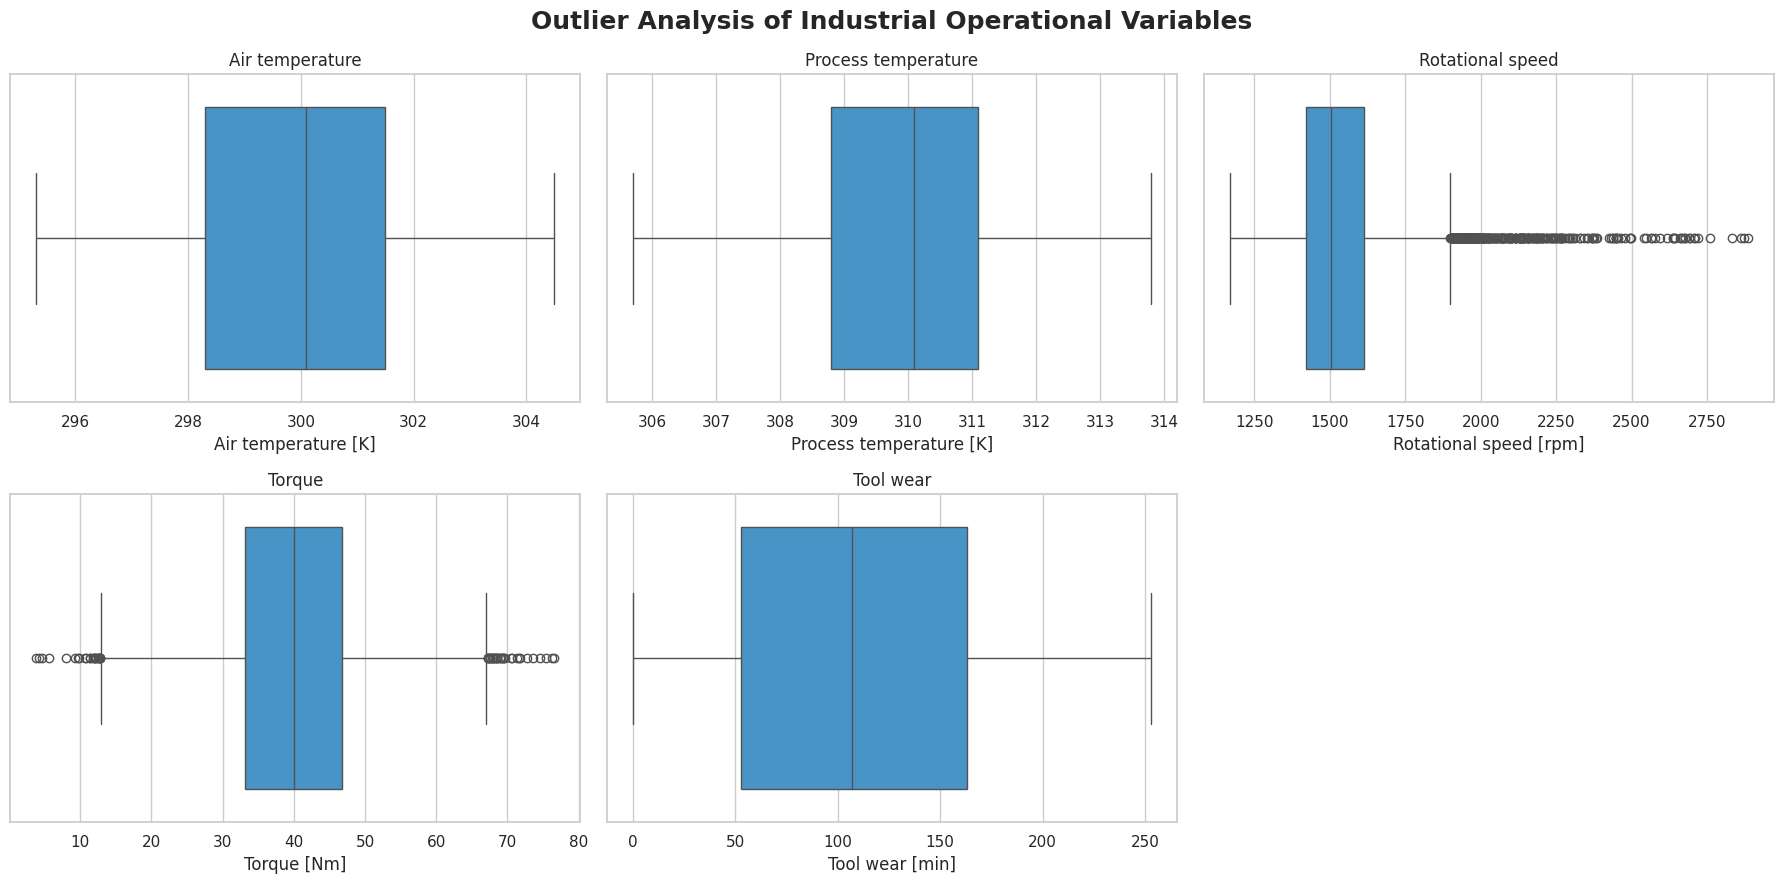

In [17]:
# Visualize potential outliers using boxplots
fig, axes = plt.subplots(2, 3, figsize=(18, 9))

axes = axes.flatten()

for i, column in enumerate(sensor_columns):
    sns.boxplot(
        data=train_df,
        x=column,
        color="#3498db",
        ax=axes[i]
    )

    axes[i].set_title(column)
    axes[i].set_xlabel(
        f"{column} [{sensor_units[column]}]"
    )

# Remove unused subplot
fig.delaxes(axes[-1])

fig.suptitle(
    "Outlier Analysis of Industrial Operational Variables",
    fontsize=18,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

### 3.4 Failure Analysis by Product Type

Investigate the relationship between product quality
categories and machine failure occurrence.

Failure rates are calculated for each product type to
identify potential differences in operational reliability,
while accounting for the unequal number of observations
across product categories.

In [18]:
# Analyze machine failures by product type
product_analysis = train_df.groupby("Type").agg(
    Total_Observations=("Machine failure", "count"),
    Total_Failures=("Machine failure", "sum"),
    Failure_Rate=("Machine failure", "mean")
)

# Convert failure rate to percentage
product_analysis["Failure_Rate"] *= 100

# Calculate non-failure observations
product_analysis["Total_Non_Failures"] = (
    product_analysis["Total_Observations"] -
    product_analysis["Total_Failures"]
)

# Reorder columns and product categories
product_analysis = product_analysis[
    [
        "Total_Observations",
        "Total_Non_Failures",
        "Total_Failures",
        "Failure_Rate"
    ]
].reindex(["L", "M", "H"])

display(product_analysis.round(2))

,Total_Observations,Total_Non_Failures,Total_Failures,Failure_Rate
Type,,,,
L,4830,4633,197,4.08
M,2381,2323,58,2.44
H,789,773,16,2.03


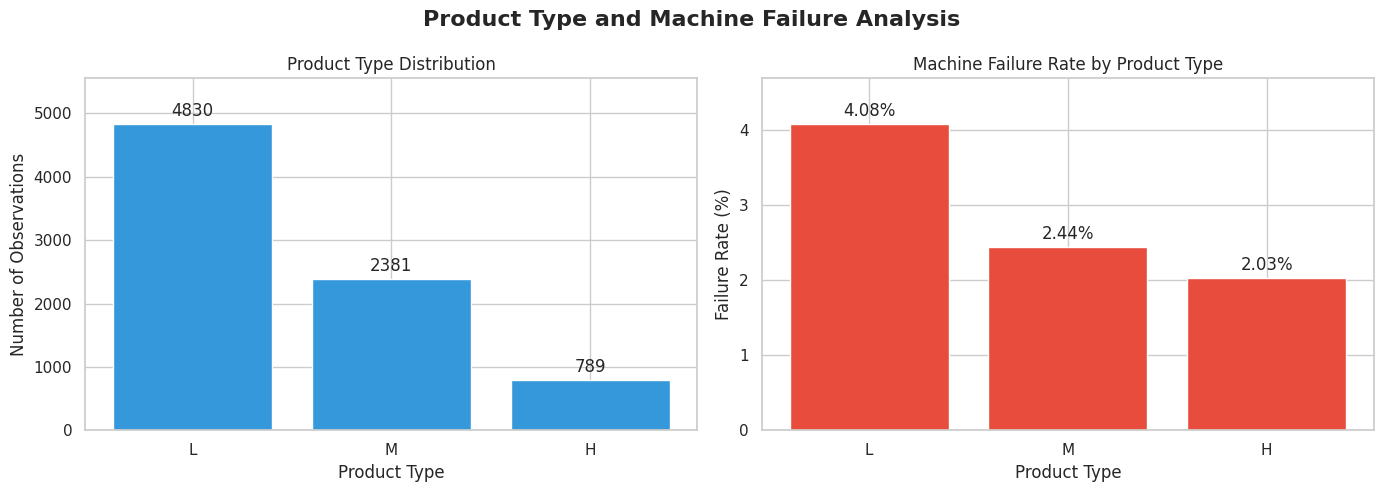

In [19]:
# Visualize product distribution and failure rates
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Product type distribution
bars1 = axes[0].bar(
    product_analysis.index,
    product_analysis["Total_Observations"],
    color="#3498db"
)

axes[0].bar_label(bars1, padding=3)
axes[0].set_title("Product Type Distribution")
axes[0].set_xlabel("Product Type")
axes[0].set_ylabel("Number of Observations")
axes[0].margins(y=0.15)

# Failure rate by product type
bars2 = axes[1].bar(
    product_analysis.index,
    product_analysis["Failure_Rate"],
    color="#e74c3c"
)

axes[1].bar_label(bars2, fmt="%.2f%%", padding=3)
axes[1].set_title("Machine Failure Rate by Product Type")
axes[1].set_xlabel("Product Type")
axes[1].set_ylabel("Failure Rate (%)")
axes[1].margins(y=0.15)

fig.suptitle(
    "Product Type and Machine Failure Analysis",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

### 3.5 Sensor Analysis by Failure Status

Investigate differences in operational variables between
observations with and without machine failures.

Comparative statistical summaries and visualizations are
used to identify potential failure indicators, abnormal
operating conditions, and differences in feature distributions.

The findings will support subsequent hypothesis testing
and physics-informed feature engineering.

In [20]:
# Compare operational statistics by failure status
failure_statistics = train_df.groupby(
    "Machine failure"
)[sensor_columns].agg(["mean", "median", "std"]).T

# Rename failure status columns
failure_statistics.columns = [
    "No Failure",
    "Failure"
]

display(failure_statistics.round(3))

No Failure   Failure
Air temperature     mean       299.973   300.923
                    median     300.000   301.600
                    std          1.987     2.053
Process temperature mean       309.995   310.329
                    median     310.000   310.500
                    std          1.482     1.364
Rotational speed    mean      1540.711  1500.731
                    median    1507.000  1366.000
                    std        168.945   389.741
Torque              mean        39.647    50.171
                    median      39.800    53.200
                    std          9.516    16.573
Tool wear           mean       106.503   141.387
                    median     106.000   166.000
                    std         62.860    74.854

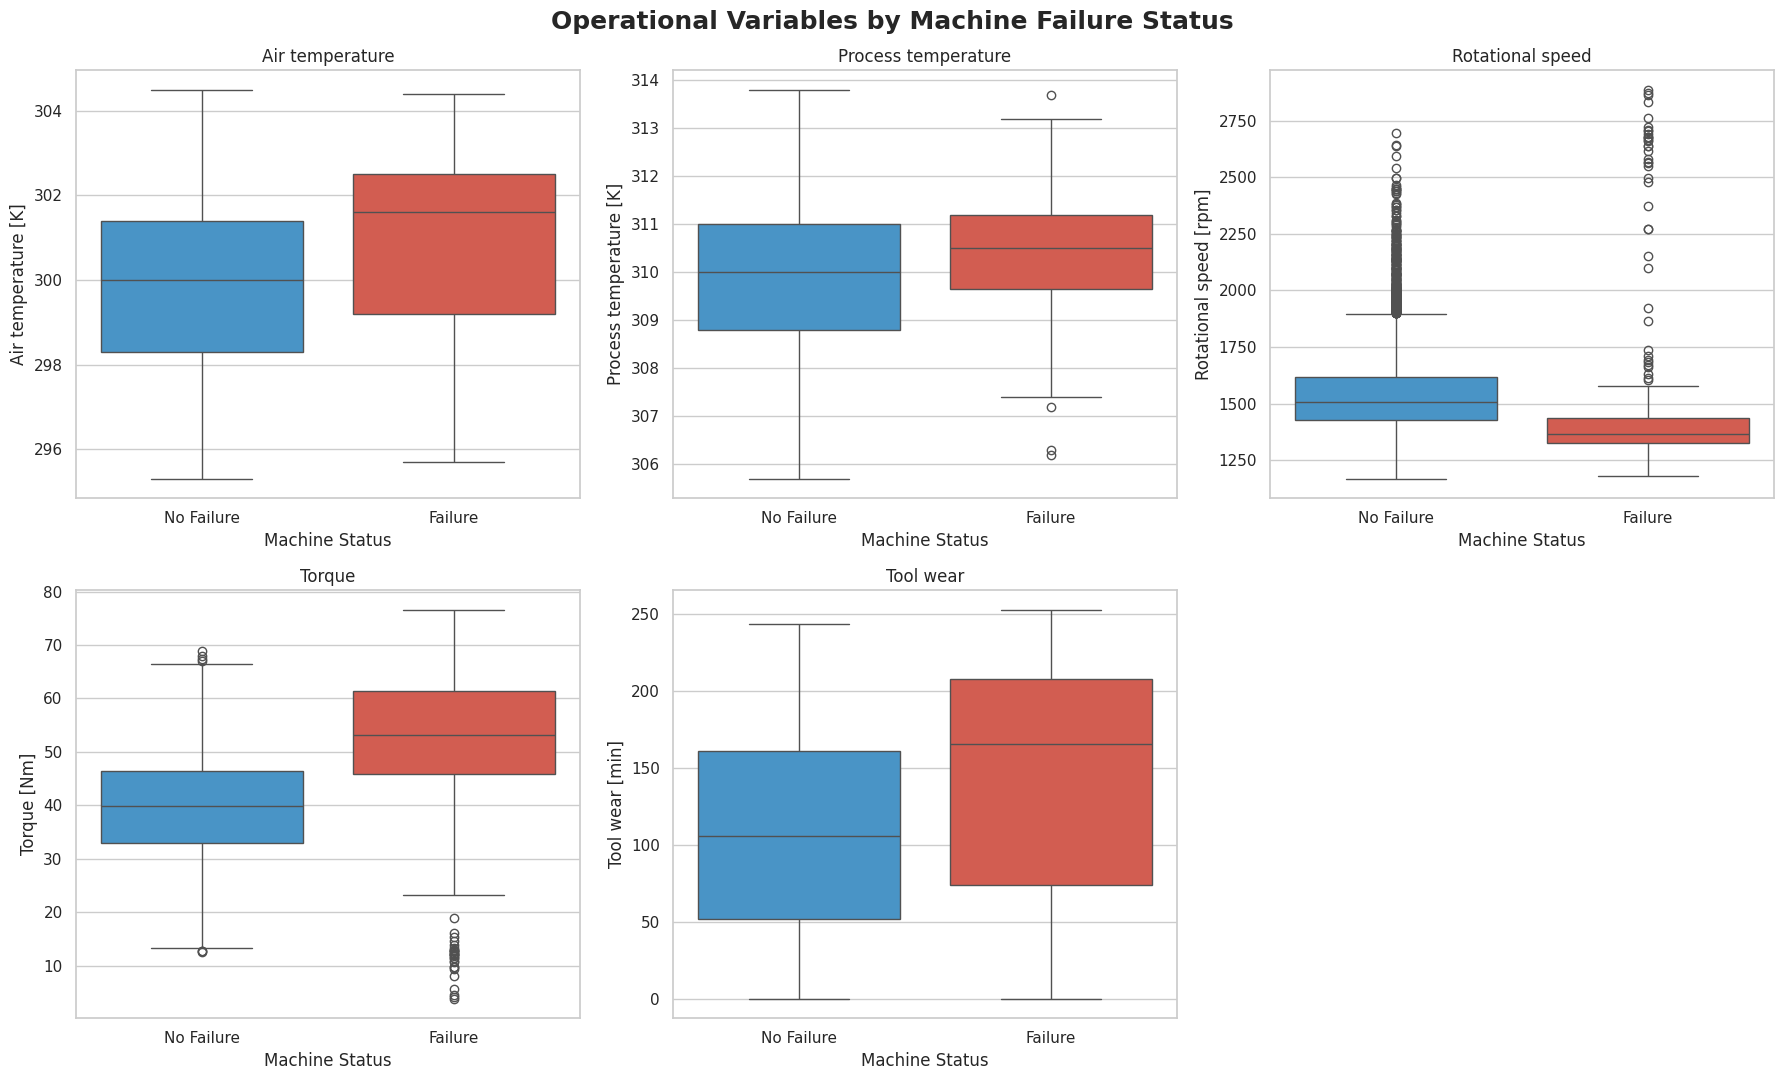

In [21]:
# Create a readable failure status column
analysis_df = train_df.assign(
    Failure_Status=train_df["Machine failure"].map({
        0: "No Failure",
        1: "Failure"
    })
)

# Compare sensor distributions by failure status
fig, axes = plt.subplots(2, 3, figsize=(18, 11))

axes = axes.flatten()

for i, column in enumerate(sensor_columns):
    sns.boxplot(
        data=analysis_df,
        x="Failure_Status",
        y=column,
        hue="Failure_Status",
        order=["No Failure", "Failure"],
        palette={
            "No Failure": "#3498db",
            "Failure": "#e74c3c"
        },
        legend=False,
        ax=axes[i]
    )

    axes[i].set_title(column, fontsize=12)
    axes[i].set_xlabel("Machine Status")
    axes[i].set_ylabel(
        f"{column} [{sensor_units[column]}]"
    )

# Remove unused subplot
fig.delaxes(axes[-1])

fig.suptitle(
    "Operational Variables by Machine Failure Status",
    fontsize=18,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

#### Distribution Comparison by Failure Status

Kernel Density Estimation (KDE) is used to compare
the distributions of operational features between
failure and non-failure observations.

Independent normalization allows meaningful distribution
comparisons despite the substantial class imbalance.

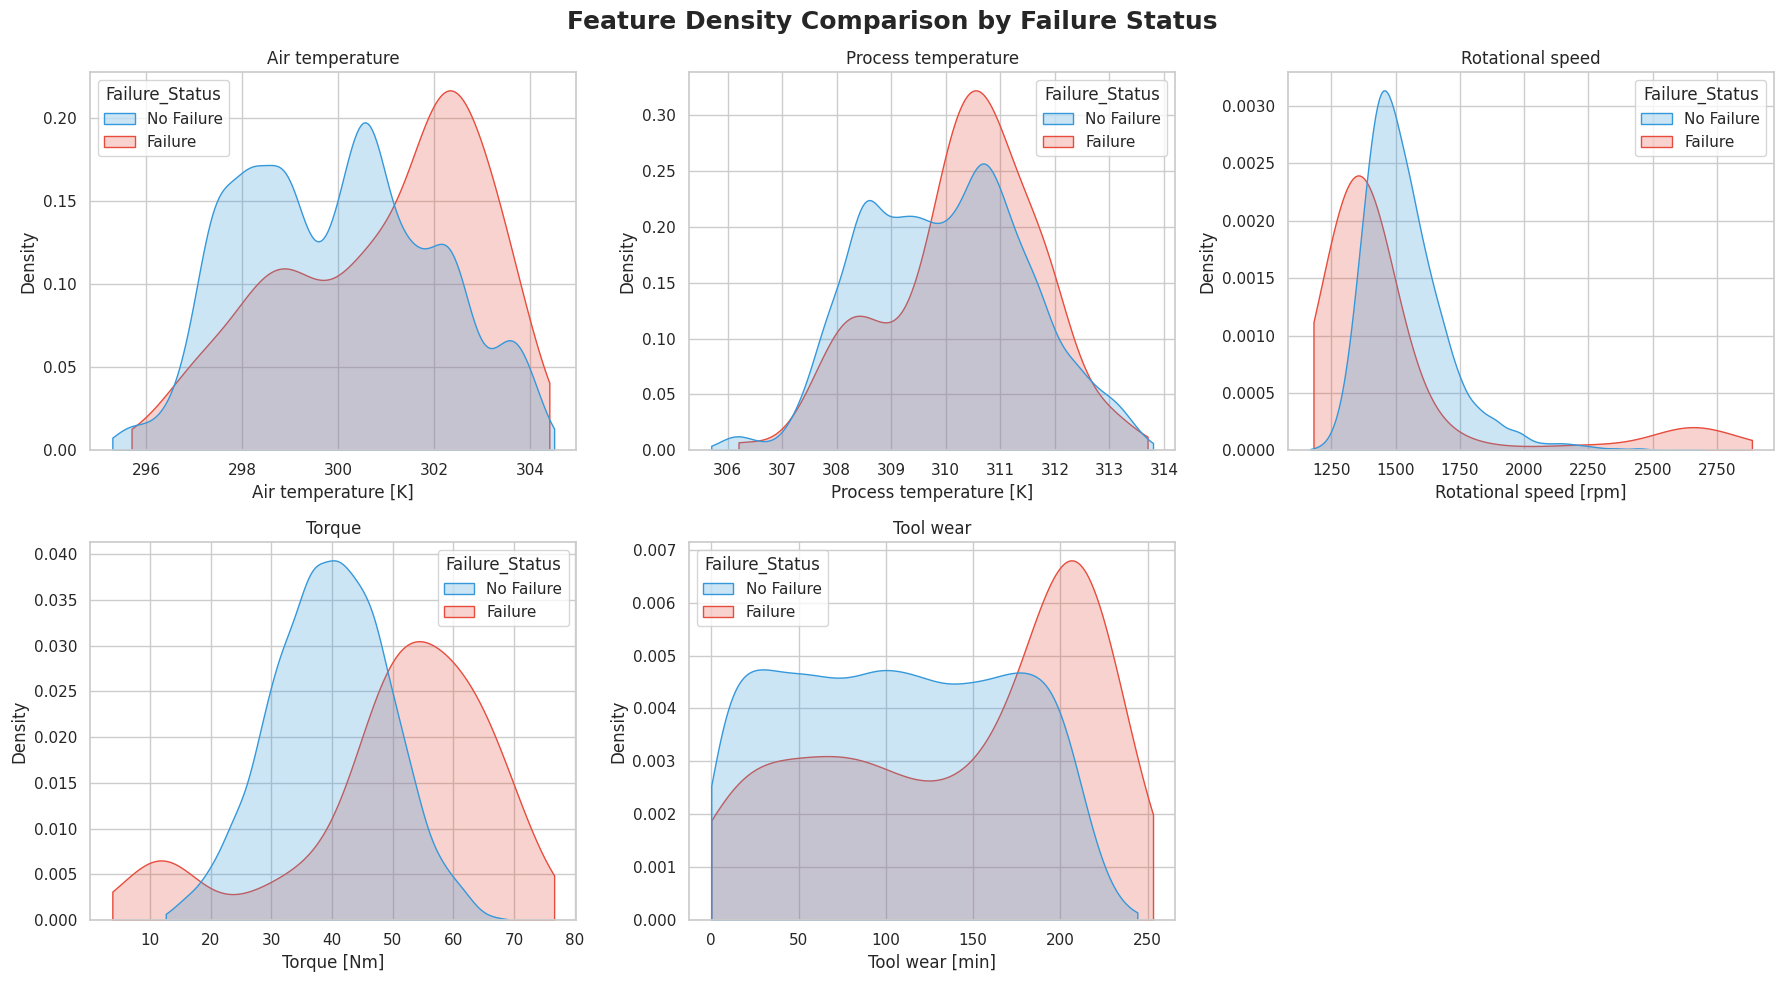

In [22]:
# Compare feature density distributions
fig, axes = plt.subplots(2, 3, figsize=(18, 10))

axes = axes.flatten()

for i, column in enumerate(sensor_columns):
    sns.kdeplot(
        data=analysis_df,
        x=column,
        hue="Failure_Status",
        common_norm=False,
        fill=True,
        alpha=0.25,
        cut=0,
        palette={
            "No Failure": "#3498db",
            "Failure": "#e74c3c"
        },
        ax=axes[i]
    )

    axes[i].set_title(column, fontsize=12)
    axes[i].set_xlabel(
        f"{column} [{sensor_units[column]}]"
    )
    axes[i].set_ylabel("Density")

# Remove unused subplot
fig.delaxes(axes[-1])

fig.suptitle(
    "Feature Density Comparison by Failure Status",
    fontsize=18,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

### 3.6 Correlation Analysis

Pearson and Spearman correlation coefficients are used
to investigate relationships between numerical
operational features and machine failure occurrence.

Pearson correlation measures linear associations,
while Spearman correlation captures monotonic
relationships and is less sensitive to extreme values.

The analysis supports feature engineering and the
identification of potentially redundant features.

Failure-type indicators are excluded from this analysis
to prevent target leakage during feature selection.

In [23]:
# Define variables for correlation analysis
correlation_columns = sensor_columns + ["Machine failure"]

# Calculate Pearson correlation matrix
pearson_corr = train_df[correlation_columns].corr(
    method="pearson"
)

# Calculate Spearman correlation matrix
spearman_corr = train_df[correlation_columns].corr(
    method="spearman"
)

print("Pearson Correlation Matrix")
display(pearson_corr.round(3))

print("Spearman Correlation Matrix")
display(spearman_corr.round(3))

Pearson Correlation Matrix


,Air temperature,Process temperature,Rotational speed,Torque,Tool wear,Machine failure
Air temperature,1.000,0.876,0.025,-0.015,0.010,0.086
Process temperature,0.876,1.000,0.018,-0.012,0.012,0.041
Rotational speed,0.025,0.018,1.000,-0.874,0.002,-0.040
Torque,-0.015,-0.012,-0.874,1.000,-0.008,0.190
Tool wear,0.010,0.012,0.002,-0.008,1.000,0.099
Machine failure,0.086,0.041,-0.040,0.190,0.099,1.000


Spearman Correlation Matrix


,Air temperature,Process temperature,Rotational speed,Torque,Tool wear,Machine failure
Air temperature,1.000,0.864,0.013,-0.012,0.010,0.086
Process temperature,0.864,1.000,0.012,-0.011,0.013,0.045
Rotational speed,0.013,0.012,1.000,-0.917,0.010,-0.164
Torque,-0.012,-0.011,-0.917,1.000,-0.011,0.168
Tool wear,0.010,0.013,0.010,-0.011,1.000,0.095
Machine failure,0.086,0.045,-0.164,0.168,0.095,1.000


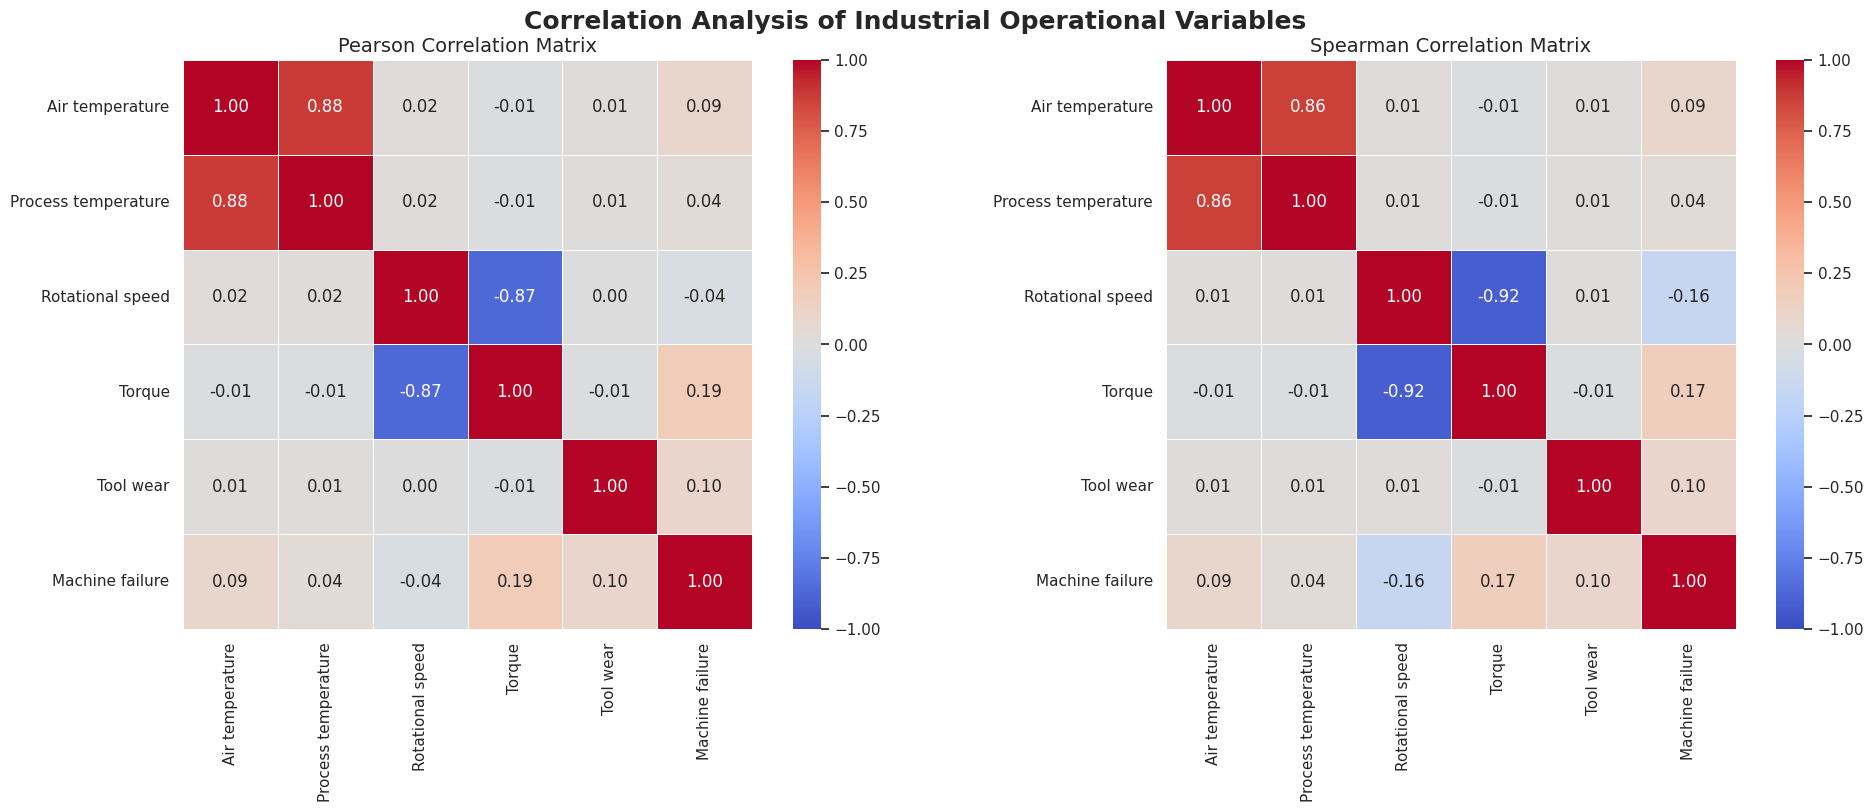

In [24]:
# Visualize Pearson and Spearman correlation matrices
fig, axes = plt.subplots(1, 2, figsize=(20, 8))

sns.heatmap(
    pearson_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5,
    ax=axes[0]
)

axes[0].set_title(
    "Pearson Correlation Matrix",
    fontsize=14
)

sns.heatmap(
    spearman_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5,
    ax=axes[1]
)

axes[1].set_title(
    "Spearman Correlation Matrix",
    fontsize=14
)

fig.suptitle(
    "Correlation Analysis of Industrial Operational Variables",
    fontsize=18,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

#### Feature Correlation with Machine Failure

Operational features are ranked according to the absolute
strength of their Pearson and Spearman correlations
with the machine failure target.

Both positive and negative associations are examined
to identify potential failure-related operating conditions.

Correlation does not imply causation, and weak individual
correlations do not necessarily indicate low predictive value.

In [25]:
# Extract correlations with the target variable
target_correlations = pd.DataFrame({
    "Pearson": pearson_corr["Machine failure"].drop(
        "Machine failure"
    ),
    "Spearman": spearman_corr["Machine failure"].drop(
        "Machine failure"
    )
})

# Calculate absolute correlation strength
target_correlations["Absolute Pearson"] = (
    target_correlations["Pearson"].abs()
)

target_correlations["Absolute Spearman"] = (
    target_correlations["Spearman"].abs()
)

# Rank features by absolute Pearson correlation
target_correlations = target_correlations.sort_values(
    "Absolute Pearson",
    ascending=False
)

display(target_correlations.round(4))

,Pearson,Spearman,Absolute Pearson,Absolute Spearman
Torque,0.1900,0.1678,0.1900,0.1678
Tool wear,0.0992,0.0952,0.0992,0.0952
Air temperature,0.0860,0.0864,0.0860,0.0864
Process temperature,0.0408,0.0446,0.0408,0.0446
Rotational speed,-0.0400,-0.1635,0.0400,0.1635


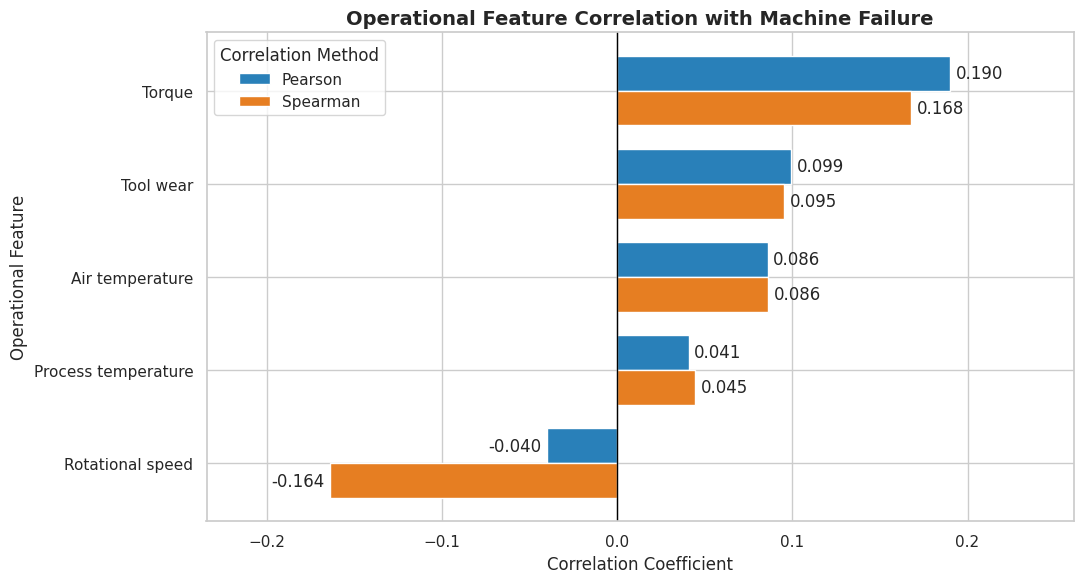

In [26]:
# Visualize correlations with machine failure
ax = target_correlations[
    ["Pearson", "Spearman"]
].plot(
    kind="barh",
    figsize=(11, 6),
    color=["#2980b9", "#e67e22"],
    width=0.75
)

ax.axvline(
    x=0,
    color="black",
    linewidth=1
)

ax.set_title(
    "Operational Feature Correlation with Machine Failure",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Correlation Coefficient")
ax.set_ylabel("Operational Feature")
ax.invert_yaxis()

ax.legend(title="Correlation Method")

for container in ax.containers:
    ax.bar_label(
        container,
        fmt="%.3f",
        padding=4
    )

ax.margins(x=0.20)

plt.tight_layout()
plt.show()

### 3.7 Failure Types Analysis

Analyze the occurrence and distribution of different
industrial machine failure mechanisms.

The dataset provides five binary failure-type indicators:
Tool Wear Failure (TWF), Heat Dissipation Failure (HDF),
Power Failure (PWF), Overstrain Failure (OSF), and
Random Failure (RNF).

Multiple failure mechanisms may occur within the same
observation.

These variables are used exclusively for exploratory
analysis and are excluded from predictive model inputs
to prevent target leakage.

In [27]:
# Define failure-type indicators
failure_types = ["TWF", "HDF", "PWF", "OSF", "RNF"]

failure_names = {
    "TWF": "Tool Wear Failure",
    "HDF": "Heat Dissipation Failure",
    "PWF": "Power Failure",
    "OSF": "Overstrain Failure",
    "RNF": "Random Failure"
}

# Calculate failure-type frequencies
failure_type_summary = pd.DataFrame({
    "Failure Type": [
        failure_names[col] for col in failure_types
    ],
    "Count": train_df[failure_types].sum().values,
    "Occurrence Rate (%)": (
        train_df[failure_types].mean().values * 100
    )
}, index=failure_types)

# Sort failure types by frequency
failure_type_summary = failure_type_summary.sort_values(
    "Count",
    ascending=False
)

display(failure_type_summary.round(3))

,Failure Type,Count,Occurrence Rate (%)
HDF,Heat Dissipation Failure,86,1.075
OSF,Overstrain Failure,82,1.025
PWF,Power Failure,82,1.025
TWF,Tool Wear Failure,36,0.450
RNF,Random Failure,15,0.188


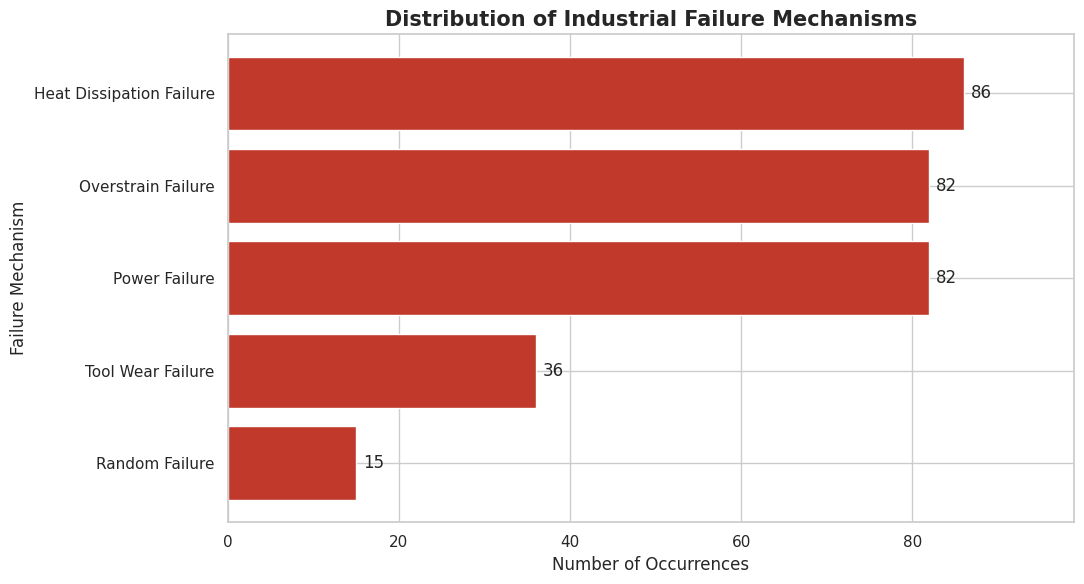

In [28]:
# Visualize failure-type frequencies
fig, ax = plt.subplots(figsize=(11, 6))

bars = ax.barh(
    failure_type_summary["Failure Type"],
    failure_type_summary["Count"],
    color="#c0392b"
)

ax.bar_label(bars, padding=5)

ax.set_title(
    "Distribution of Industrial Failure Mechanisms",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Number of Occurrences")
ax.set_ylabel("Failure Mechanism")
ax.invert_yaxis()
ax.margins(x=0.15)

plt.tight_layout()
plt.show()

#### Failure Co-occurrence Analysis

Investigate whether multiple failure mechanisms occur
simultaneously within individual observations.

A co-occurrence matrix is constructed to identify
combinations of failure mechanisms and provide additional
insights into complex industrial failure patterns.

,TWF,HDF,PWF,OSF,RNF
TWF,36,0,1,2,1
HDF,0,86,2,6,0
PWF,1,2,82,12,0
OSF,2,6,12,82,0
RNF,1,0,0,0,15


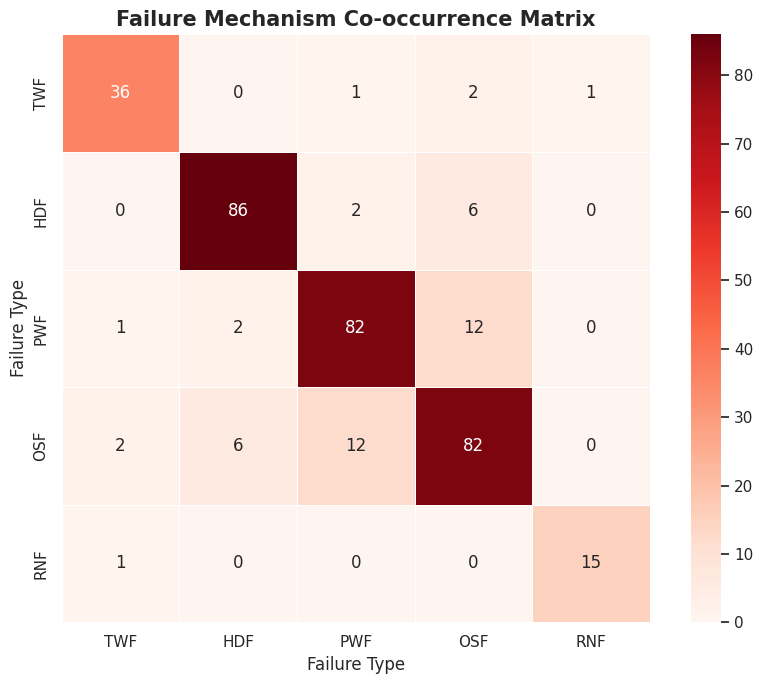

In [29]:
# Extract binary failure-type indicators
failure_matrix = train_df[failure_types].astype(int)

# Calculate pairwise failure co-occurrence
co_occurrence = failure_matrix.T.dot(failure_matrix)

display(co_occurrence)

# Visualize failure co-occurrence matrix
plt.figure(figsize=(9, 7))

sns.heatmap(
    co_occurrence,
    annot=True,
    fmt="d",
    cmap="Reds",
    linewidths=0.5,
    square=True
)

plt.title(
    "Failure Mechanism Co-occurrence Matrix",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Failure Type")
plt.ylabel("Failure Type")

plt.tight_layout()
plt.show()

#### Failure Label Consistency

Evaluate the consistency between the primary machine
failure target and the individual failure-type indicators.

Potential discrepancies are documented to improve
understanding of the dataset's labeling structure.

In [30]:
# Count active failure mechanisms per observation
active_failure_count = failure_matrix.sum(axis=1)

# Identify observations with multiple failure mechanisms
multiple_failures = (active_failure_count > 1).sum()

print("Observations with multiple failure mechanisms:",
      multiple_failures)

# Check whether any failure mechanism is active
any_failure_type = (active_failure_count > 0).astype(int)

# Compare failure indicators with the primary target
label_consistency = pd.crosstab(
    train_df["Machine failure"],
    any_failure_type,
    rownames=["Machine Failure Target"],
    colnames=["Any Failure Indicator"],
    margins=True
)

display(label_consistency)

# Identify label discrepancies
label_mismatches = (
    train_df["Machine failure"] != any_failure_type
)

print("Label discrepancies:", label_mismatches.sum())

print(
    "Label discrepancy rate:",
    f"{label_mismatches.mean() * 100:.3f}%"
)

Observations with multiple failure mechanisms: 22


Any Failure Indicator,0,1,All
Machine Failure Target,,,
0,7715,14,7729
1,7,264,271
All,7722,278,8000


Label discrepancies: 21
Label discrepancy rate: 0.263%


### 3.8 Exploratory Data Analysis Findings

Summarize the main findings obtained during exploratory
data analysis, including class imbalance, operational
feature distributions, product-specific failure rates,
feature correlations, and failure mechanisms.

These findings provide the foundation for statistical
hypothesis testing, feature engineering, and subsequent
machine learning model development.

In [31]:
# Extract key exploratory findings
failure_rate = train_df["Machine failure"].mean() * 100

highest_risk_type = product_analysis["Failure_Rate"].idxmax()
highest_type_rate = product_analysis["Failure_Rate"].max()

strongest_feature = target_correlations[
    "Absolute Pearson"
].idxmax()

strongest_correlation = target_correlations.loc[
    strongest_feature, "Pearson"
]

most_common_failure = failure_type_summary.iloc[0]["Failure Type"]

highest_outlier_feature = outlier_summary[
    "Outlier (%)"
].idxmax()

# Summarize EDA findings
eda_findings = pd.DataFrame({
    "Analysis": [
        "Training observations",
        "Overall failure rate",
        "Highest-risk product type",
        "Highest product failure rate",
        "Strongest Pearson-correlated feature",
        "Pearson correlation coefficient",
        "Most frequent failure mechanism",
        "Feature with highest outlier percentage",
        "Multiple failure mechanisms",
        "Label discrepancies"
    ],
    "Finding": [
        f"{len(train_df):,}",
        f"{failure_rate:.2f}%",
        highest_risk_type,
        f"{highest_type_rate:.2f}%",
        strongest_feature,
        f"{strongest_correlation:.4f}",
        most_common_failure,
        highest_outlier_feature,
        multiple_failures,
        label_mismatches.sum()
    ]
})

display(eda_findings)

,Analysis,Finding
0,Training observations,"8,000"
1,Overall failure rate,3.39%
2,Highest-risk product type,L
3,Highest product failure rate,4.08%
4,Strongest Pearson-correlated feature,Torque
5,Pearson correlation coefficient,0.1900
6,Most frequent failure mechanism,Heat Dissipation Failure
7,Feature with highest outlier percentage,Rotational speed
8,Multiple failure mechanisms,22
9,Label discrepancies,21


#### EDA Conclusions and Modeling Implications

- Class imbalance requires appropriate evaluation metrics
  and imbalance-aware modeling strategies.

- Differences between failure and non-failure observations
  require formal statistical investigation.

- Potential outliers are retained because they may represent
  meaningful abnormal operating conditions.

- Correlation analysis provides initial insights but cannot
  establish causality or fully capture nonlinear dependencies.

- Failure-type indicators are excluded from predictive
  features to prevent target leakage.

- Physics-informed feature engineering will be investigated
  to capture interactions between operational variables.

- The test dataset remains reserved for final model evaluation.

## 4. Statistical Analysis

Statistical hypothesis testing is conducted to evaluate
associations between industrial operating conditions
and machine failure occurrence.

The analysis combines distribution assessment,
non-parametric hypothesis testing, categorical association
testing, effect size estimation, and multiple testing
correction.

All statistical analyses are performed exclusively on
the training dataset.

### 4.1 Statistical Framework

Significance level: alpha = 0.05

Null hypothesis (H0):
There is no statistically detectable association or
distributional difference between the variables under
investigation.

Alternative hypothesis (H1):
An association or distributional difference exists.

Statistical significance is interpreted alongside effect
size and practical industrial relevance.

In [32]:
# Define statistical significance level
ALPHA = 0.05

# Separate observations by machine failure status
non_failure_df = train_df[
    train_df["Machine failure"] == 0
].copy()

failure_df = train_df[
    train_df["Machine failure"] == 1
].copy()

print("Statistical Analysis Configuration")
print("-" * 40)

print(f"Significance level: {ALPHA}")
print(f"Non-failure observations: {len(non_failure_df)}")
print(f"Failure observations: {len(failure_df)}")

Statistical Analysis Configuration
----------------------------------------
Significance level: 0.05
Non-failure observations: 7729
Failure observations: 271


### 4.2 Normality Assessment

The Shapiro-Wilk test is applied to operational variables
within both failure and non-failure groups.

H0: The observations follow a normal distribution.

H1: The observations do not follow a normal distribution.

A maximum sample size of 5,000 observations per group
is used for the test.

Normality results are interpreted alongside graphical
distribution assessments because statistical tests can
be highly sensitive to deviations in large samples.

In [33]:
# Perform Shapiro-Wilk normality tests
normality_results = []

failure_groups = {
    "No Failure": non_failure_df,
    "Failure": failure_df
}

for column in sensor_columns:

    for group_name, group_df in failure_groups.items():

        values = group_df[column].dropna()

        # Limit sample size for Shapiro-Wilk testing
        if len(values) > 5000:
            values = values.sample(
                n=5000,
                random_state=RANDOM_STATE
            )

        # Perform normality test
        statistic, p_value = stats.shapiro(values)

        normality_results.append({
            "Feature": column,
            "Group": group_name,
            "Sample Size": len(values),
            "Shapiro Statistic": statistic,
            "P-value": p_value,
            "Reject Normality": p_value < ALPHA
        })

# Convert results to DataFrame
normality_df = pd.DataFrame(normality_results)

display(
    normality_df.style.format({
        "Shapiro Statistic": "{:.4f}",
        "P-value": "{:.4e}"
    })
)

,Feature,Group,Sample Size,Shapiro Statistic,P-value,Reject Normality
0,Air temperature,No Failure,5000,0.9802,7.5696e-26,True
1,Air temperature,Failure,271,0.9401,4.8178e-09,True
2,Process temperature,No Failure,5000,0.9915,1.0034e-16,True
3,Process temperature,Failure,271,0.9796,6.2784e-04,True
4,Rotational speed,No Failure,5000,0.9018,6.7186e-49,True
5,Rotational speed,Failure,271,0.5561,1.0408e-25,True
6,Torque,No Failure,5000,0.9980,4.8572e-06,True
7,Torque,Failure,271,0.8827,1.3517e-13,True
8,Tool wear,No Failure,5000,0.9583,1.2140e-35,True
9,Tool wear,Failure,271,0.8931,6.6242e-13,True


### 4.3 Mann-Whitney U Test

The Mann-Whitney U test is applied to investigate
distributional differences in operational variables
between failure and non-failure observations.

For each numerical feature:

H0: The feature distributions are identical between
failure and non-failure groups.

H1: The feature distributions differ between the
two groups.

A two-sided test is performed with a significance
level of 0.05.

This non-parametric approach does not require
normally distributed observations.

In [34]:
# Perform Mann-Whitney U tests
mann_whitney_results = []

for column in sensor_columns:

    failure_values = failure_df[column].dropna()
    non_failure_values = non_failure_df[column].dropna()

    # Perform two-sided Mann-Whitney U test
    u_statistic, p_value = stats.mannwhitneyu(
        failure_values,
        non_failure_values,
        alternative="two-sided",
        method="asymptotic"
    )

    mann_whitney_results.append({
        "Feature": column,
        "Failure Median": failure_values.median(),
        "Non-Failure Median": non_failure_values.median(),
        "U Statistic": u_statistic,
        "P-value": p_value,
        "Significant": p_value < ALPHA
    })

# Create results DataFrame
mann_whitney_df = pd.DataFrame(
    mann_whitney_results
)

mann_whitney_df = mann_whitney_df.sort_values(
    "P-value"
).reset_index(drop=True)

display(
    mann_whitney_df.style.format({
        "Failure Median": "{:.3f}",
        "Non-Failure Median": "{:.3f}",
        "U Statistic": "{:.2f}",
        "P-value": "{:.4e}"
    })
)

,Feature,Failure Median,Non-Failure Median,U Statistic,P-value,Significant
0,Torque,53.200,39.800,1608234.00,6.2463e-51,True
1,Rotational speed,1366.000,1507.000,500696.50,1.9139e-48,True
2,Tool wear,166.000,106.000,1365422.50,1.6903e-17,True
3,Air temperature,301.600,300.000,1335999.50,1.1022e-14,True
4,Process temperature,310.500,310.000,1196305.00,6.6462e-05,True


### 4.4 Effect Size Analysis

Rank-biserial correlation is calculated to quantify
the magnitude and direction of differences between
failure and non-failure observations.

Unlike p-values, effect sizes provide information
about the strength of an observed association.

Positive values indicate a tendency toward higher
feature values in failure observations, while negative
values indicate a tendency toward lower values.

Effect magnitude thresholds are used as descriptive
heuristics rather than strict industrial standards.

In [35]:
# Define sample sizes
n_failure = len(failure_df)
n_non_failure = len(non_failure_df)

# Calculate rank-biserial correlation
mann_whitney_df["Effect Size"] = (
    2 * mann_whitney_df["U Statistic"] /
    (n_failure * n_non_failure)
) - 1

# Calculate absolute effect size
mann_whitney_df["Absolute Effect Size"] = (
    mann_whitney_df["Effect Size"].abs()
)

# Define effect magnitude categories
def classify_effect_size(value):

    value = abs(value)

    if value < 0.10:
        return "Negligible"

    elif value < 0.30:
        return "Small"

    elif value < 0.50:
        return "Medium"

    else:
        return "Large"

# Assign effect magnitude
mann_whitney_df["Effect Magnitude"] = (
    mann_whitney_df["Effect Size"]
    .apply(classify_effect_size)
)

display(
    mann_whitney_df.style.format({
        "Failure Median": "{:.3f}",
        "Non-Failure Median": "{:.3f}",
        "U Statistic": "{:.2f}",
        "P-value": "{:.4e}",
        "Effect Size": "{:.4f}",
        "Absolute Effect Size": "{:.4f}"
    })
)

,Feature,Failure Median,Non-Failure Median,U Statistic,P-value,Significant,Effect Size,Absolute Effect Size,Effect Magnitude
0,Torque,53.200,39.800,1608234.00,6.2463e-51,True,0.5356,0.5356,Large
1,Rotational speed,1366.000,1507.000,500696.50,1.9139e-48,True,-0.5219,0.5219,Large
2,Tool wear,166.000,106.000,1365422.50,1.6903e-17,True,0.3038,0.3038,Medium
3,Air temperature,301.600,300.000,1335999.50,1.1022e-14,True,0.2757,0.2757,Small
4,Process temperature,310.500,310.000,1196305.00,6.6462e-05,True,0.1423,0.1423,Small


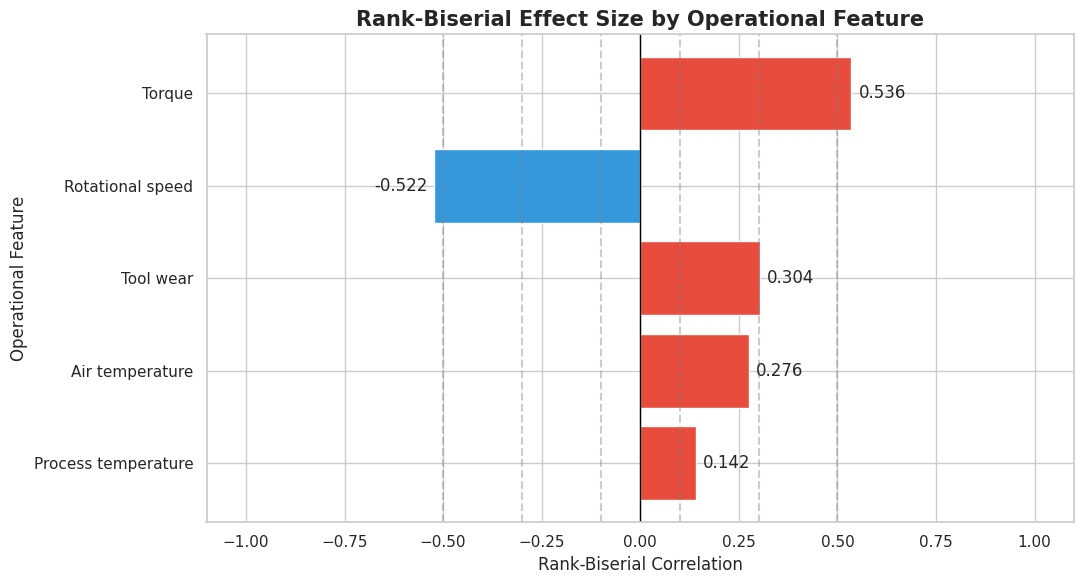

In [36]:
# Sort features by absolute effect size
effect_plot_df = mann_whitney_df.sort_values(
    "Absolute Effect Size",
    ascending=True
)

# Assign colors according to effect direction
colors = [
    "#e74c3c" if value > 0 else "#3498db"
    for value in effect_plot_df["Effect Size"]
]

# Visualize rank-biserial correlation
fig, ax = plt.subplots(figsize=(11, 6))

bars = ax.barh(
    effect_plot_df["Feature"],
    effect_plot_df["Effect Size"],
    color=colors
)

ax.bar_label(
    bars,
    fmt="%.3f",
    padding=5
)

ax.axvline(
    x=0,
    color="black",
    linewidth=1
)

# Add reference thresholds
for threshold in [0.10, 0.30, 0.50]:

    ax.axvline(
        threshold,
        color="gray",
        linestyle="--",
        alpha=0.4
    )

    ax.axvline(
        -threshold,
        color="gray",
        linestyle="--",
        alpha=0.4
    )

ax.set_xlim(-1.1, 1.1)

ax.set_title(
    "Rank-Biserial Effect Size by Operational Feature",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Rank-Biserial Correlation")
ax.set_ylabel("Operational Feature")

plt.tight_layout()
plt.show()

### 4.5 Chi-Square Test of Independence

The Chi-Square test of independence is used to evaluate
the association between product type and machine failure
occurrence.

H0: Product type and machine failure are independent.

H1: Product type and machine failure are associated.

The test is conducted using a significance level of 0.05.
Expected frequencies are examined to assess the validity
of the Chi-Square approximation.

In [37]:
# Create contingency table
contingency_table = pd.crosstab(
    train_df["Type"],
    train_df["Machine failure"]
).reindex(["L", "M", "H"])

contingency_table.columns = [
    "No Failure",
    "Failure"
]

print("Observed Frequencies")
display(contingency_table)

# Perform Chi-Square test
chi2, chi_p_value, dof, expected = (
    stats.chi2_contingency(contingency_table)
)

# Create expected frequency table
expected_df = pd.DataFrame(
    expected,
    index=contingency_table.index,
    columns=contingency_table.columns
)

print("Expected Frequencies")
display(expected_df.round(3))

# Display statistical results
print(f"Chi-Square Statistic: {chi2:.4f}")
print(f"P-value: {chi_p_value:.6f}")
print(f"Degrees of Freedom: {dof}")

print(
    "All expected frequencies >= 5:",
    (expected >= 5).all()
)

if chi_p_value < ALPHA:
    print("Reject the null hypothesis.")
else:
    print("Fail to reject the null hypothesis.")

Observed Frequencies


,No Failure,Failure
Type,,
L,4633,197
M,2323,58
H,773,16


Expected Frequencies


,No Failure,Failure
Type,,
L,4666.384,163.616
M,2300.344,80.656
H,762.273,26.727


Chi-Square Statistic: 18.0942
P-value: 0.000118
Degrees of Freedom: 2
All expected frequencies >= 5: True
Reject the null hypothesis.


### 4.6 Cramer's V Effect Size

Cramer's V is calculated to quantify the strength of
association between product type and machine failure.

The coefficient ranges from 0 to 1, where higher values
indicate stronger associations.

Statistical significance is evaluated together with
association strength to assess practical relevance.

In [38]:
# Calculate contingency table dimensions
n = contingency_table.to_numpy().sum()
rows, columns = contingency_table.shape

# Calculate Cramer's V
cramers_v = np.sqrt(
    chi2 / (n * min(rows - 1, columns - 1))
)

# Summarize categorical statistical analysis
categorical_results = pd.DataFrame({
    "Feature": ["Product Type"],
    "Statistical Test": ["Chi-Square"],
    "Chi-Square Statistic": [chi2],
    "Degrees of Freedom": [dof],
    "P-value": [chi_p_value],
    "Cramer's V": [cramers_v],
    "Significant": [chi_p_value < ALPHA]
})

display(
    categorical_results.style.format({
        "Chi-Square Statistic": "{:.4f}",
        "P-value": "{:.4e}",
        "Cramer's V": "{:.4f}"
    })
)

,Feature,Statistical Test,Chi-Square Statistic,Degrees of Freedom,P-value,Cramer's V,Significant
0,Product Type,Chi-Square,18.0942,2,1.1773e-04,0.0476,True


### 4.7 Multiple Testing Correction

Multiple hypothesis tests increase the probability
of obtaining false-positive findings.

The Benjamini-Hochberg procedure is applied to the
five numerical feature association tests and the
categorical association test to control the False
Discovery Rate (FDR) at 0.05.

Adjusted p-values are used for the final interpretation
of statistical significance.

The exploratory normality tests are treated separately
from the feature association hypothesis tests.

In [39]:
from statsmodels.stats.multitest import multipletests

# Combine association test p-values
all_p_values = np.concatenate([
    mann_whitney_df["P-value"].to_numpy(),
    [chi_p_value]
])

# Apply Benjamini-Hochberg correction
reject, adjusted_p_values, _, _ = multipletests(
    all_p_values,
    alpha=ALPHA,
    method="fdr_bh"
)

# Update numerical feature results
mann_whitney_df["Adjusted P-value"] = (
    adjusted_p_values[:-1]
)

mann_whitney_df["Significant After Correction"] = (
    reject[:-1]
)

# Update categorical feature results
categorical_results["Adjusted P-value"] = (
    adjusted_p_values[-1]
)

categorical_results["Significant After Correction"] = (
    reject[-1]
)

# Display corrected numerical results
print("Corrected Numerical Feature Results")

display(
    mann_whitney_df[[
        "Feature",
        "P-value",
        "Adjusted P-value",
        "Effect Size",
        "Effect Magnitude",
        "Significant After Correction"
    ]].style.format({
        "P-value": "{:.4e}",
        "Adjusted P-value": "{:.4e}",
        "Effect Size": "{:.4f}"
    })
)

print("Corrected Categorical Feature Results")

display(
    categorical_results.style.format({
        "P-value": "{:.4e}",
        "Adjusted P-value": "{:.4e}",
        "Chi-Square Statistic": "{:.4f}",
        "Cramer's V": "{:.4f}"
    })
)

Corrected Numerical Feature Results


,Feature,P-value,Adjusted P-value,Effect Size,Effect Magnitude,Significant After Correction
0,Torque,6.2463e-51,3.7478e-50,0.5356,Large,True
1,Rotational speed,1.9139e-48,5.7417e-48,-0.5219,Large,True
2,Tool wear,1.6903e-17,3.3805e-17,0.3038,Medium,True
3,Air temperature,1.1022e-14,1.6533e-14,0.2757,Small,True
4,Process temperature,6.6462e-05,7.9754e-05,0.1423,Small,True


Corrected Categorical Feature Results


,Feature,Statistical Test,Chi-Square Statistic,Degrees of Freedom,P-value,Cramer's V,Significant,Adjusted P-value,Significant After Correction
0,Product Type,Chi-Square,18.0942,2,1.1773e-04,0.0476,True,1.1773e-04,True


### 4.8 Statistical Findings

Summarize the results of numerical and categorical
hypothesis testing after multiple testing correction.

Statistical significance and effect sizes are considered
jointly to identify potentially informative operational
variables.

The findings guide feature engineering without
automatically excluding statistically insignificant
features, as nonlinear relationships and feature
interactions may still provide predictive value.

In [40]:
# Identify statistically significant numerical features
significant_features = mann_whitney_df.loc[
    mann_whitney_df["Significant After Correction"]
].copy()

# Identify the feature with the strongest effect
strongest_effect = mann_whitney_df.loc[
    mann_whitney_df["Absolute Effect Size"].idxmax()
]

print("STATISTICAL ANALYSIS SUMMARY")
print("=" * 50)

print(
    f"Significant numerical features: "
    f"{len(significant_features)}/{len(sensor_columns)}"
)

display(significant_features[[
    "Feature",
    "Adjusted P-value",
    "Effect Size",
    "Effect Magnitude"
]])

print("\nFeature with the strongest effect:")
print(strongest_effect["Feature"])

print(
    f"Effect size: "
    f"{strongest_effect['Effect Size']:.4f}"
)

print("\nProduct type association:")

print(
    f"Adjusted p-value: "
    f"{categorical_results['Adjusted P-value'].iloc[0]:.6f}"
)

print(f"Cramer's V: {cramers_v:.4f}")

print(
    "Statistically significant:",
    categorical_results[
        "Significant After Correction"
    ].iloc[0]
)

STATISTICAL ANALYSIS SUMMARY
Significant numerical features: 5/5


,Feature,Adjusted P-value,Effect Size,Effect Magnitude
0,Torque,3.747792e-50,0.535630,Large
1,Rotational speed,5.741727e-48,-0.521907,Large
2,Tool wear,3.380539e-17,0.303780,Medium
3,Air temperature,1.653253e-14,0.275686,Small
4,Process temperature,7.975423e-05,0.142298,Small



Feature with the strongest effect:
Torque
Effect size: 0.5356

Product type association:
Adjusted p-value: 0.000118
Cramer's V: 0.0476
Statistically significant: True


#### Statistical Analysis Conclusions

- Adjusted p-values are used to interpret statistical
  significance while accounting for multiple testing.

- Effect sizes provide additional information about
  the magnitude of observed differences.

- Statistical associations do not establish causality.

- Individual statistical significance is not the sole
  criterion for predictive feature selection.

- Domain knowledge and physical relationships will
  guide the construction of additional features.

## 5. Feature Engineering

Physics-informed feature engineering is applied to
construct additional operational variables based on
mechanical and thermal relationships.

The objective is to capture meaningful interactions
between the original features and improve the ability
of machine learning models to identify complex
failure patterns.

### 5.1 Physics-Informed Feature Construction

Engineered features include:

- Angular Velocity (rad/s)
- Mechanical Power (W)
- Temperature Difference (K)
- Temperature Ratio
- Tool Wear Load Index
- Torque-to-Speed Ratio

Mechanical power and angular velocity are derived
from physical equations, while the remaining interaction
features are treated as domain-inspired indicators.

Feature construction uses only operational variables
available at prediction time.

In [41]:
# Define physics-informed feature engineering function
def create_engineered_features(data):

    engineered = data.copy()

    # Angular velocity (rad/s)
    engineered["Angular Velocity"] = (
        2 * np.pi *
        engineered["Rotational speed"] / 60
    )

    # Mechanical power (W)
    engineered["Mechanical Power"] = (
        engineered["Torque"] *
        engineered["Angular Velocity"]
    )

    # Temperature difference (K)
    engineered["Temperature Difference"] = (
        engineered["Process temperature"] -
        engineered["Air temperature"]
    )

    # Temperature ratio
    engineered["Temperature Ratio"] = (
        engineered["Process temperature"] /
        engineered["Air temperature"].replace(0, np.nan)
    )

    # Tool wear and mechanical load interaction
    engineered["Tool Wear Load"] = (
        engineered["Tool wear"] *
        engineered["Torque"]
    )

    # Torque-to-speed interaction
    engineered["Torque Speed Ratio"] = (
        engineered["Torque"] /
        engineered["Rotational speed"].replace(0, np.nan)
    )

    return engineered

In [42]:
# Define original predictive features
original_features = ["Type"] + sensor_columns

# Define newly engineered features
engineered_features = [
    "Angular Velocity",
    "Mechanical Power",
    "Temperature Difference",
    "Temperature Ratio",
    "Tool Wear Load",
    "Torque Speed Ratio"
]

# Apply feature engineering to training features
train_engineered = create_engineered_features(
    train_df[original_features]
)

# Apply identical feature construction to testing features
test_engineered = create_engineered_features(
    test_df[original_features]
)

# Define complete feature set
all_features = original_features + engineered_features

print("Original features:", len(original_features))

print("Engineered features:", len(engineered_features))

print("Total predictive features:", len(all_features))

print("\nTraining dataset shape:", train_engineered.shape)
print("Testing dataset shape:", test_engineered.shape)

display(train_engineered.head())

Original features: 6
Engineered features: 6
Total predictive features: 12

Training dataset shape: (8000, 12)
Testing dataset shape: (2000, 12)


,Type,Air temperature,Process temperature,Rotational speed,Torque,Tool wear,Angular Velocity,Mechanical Power,Temperature Difference,Temperature Ratio,Tool Wear Load,Torque Speed Ratio
4058,M,302.0,310.9,1456,47.2,54,152.471963,7196.676675,8.9,1.029470,2548.8,0.032418
1221,M,297.0,308.3,1399,46.4,132,146.502937,6797.736296,11.3,1.038047,6124.8,0.033167
6895,M,301.0,311.6,1357,45.6,137,142.104708,6479.974671,10.6,1.035216,6247.2,0.033604
9863,L,298.9,309.8,1411,56.3,84,147.759574,8318.864043,10.9,1.036467,4729.2,0.039901
8711,L,297.1,308.5,1733,28.7,50,181.479336,5208.456932,11.4,1.038371,1435.0,0.016561


In [43]:
# Validate engineered features on training data
feature_validation = pd.DataFrame({
    "Data Type": train_engineered.dtypes,
    "Missing Values": train_engineered.isnull().sum(),
    "Unique Values": train_engineered.nunique()
})

display(feature_validation)

# Check for infinite numerical values
numeric_features = train_engineered.select_dtypes(
    include=np.number
)

infinite_values = np.isinf(numeric_features).sum().sum()

print("Infinite values:", infinite_values)

print("\nEngineered Feature Statistics")

display(
    train_engineered[engineered_features]
    .describe()
    .T
    .round(4)
)

,Data Type,Missing Values,Unique Values
Type,object,0,3
Air temperature,float64,0,93
Process temperature,float64,0,82
Rotational speed,int64,0,904
Torque,float64,0,566
Tool wear,int64,0,245
Angular Velocity,float64,0,904
Mechanical Power,float64,0,7469
Temperature Difference,float64,0,82
Temperature Ratio,float64,0,1414


Infinite values: 0

Engineered Feature Statistics


,count,mean,std,min,25%,50%,75%,max
Angular Velocity,8000.0,161.2011,18.9525,122.3127,148.9115,157.3938,168.9130,302.2212
Mechanical Power,8000.0,6282.6179,1072.4185,1148.4406,5559.6058,6272.2945,7013.8674,10469.9230
Temperature Difference,8000.0,10.0006,0.9999,7.6000,9.3000,9.8000,11.0000,12.1000
Temperature Ratio,8000.0,1.0334,0.0035,1.0251,1.0307,1.0329,1.0368,1.0407
Tool Wear Load,8000.0,4302.6842,2820.1773,0.0000,1953.3250,3998.7000,6265.0500,16497.0000
Torque Speed Ratio,8000.0,0.0269,0.0089,0.0013,0.0206,0.0267,0.0329,0.0638


### 5.2 Engineered Feature Analysis

The newly constructed features are analyzed to evaluate
their distributions and relationships with machine failure.

The analysis investigates whether physics-informed
variables capture meaningful differences between normal
and failure operating conditions.

All exploratory analyses are restricted to the training
dataset.

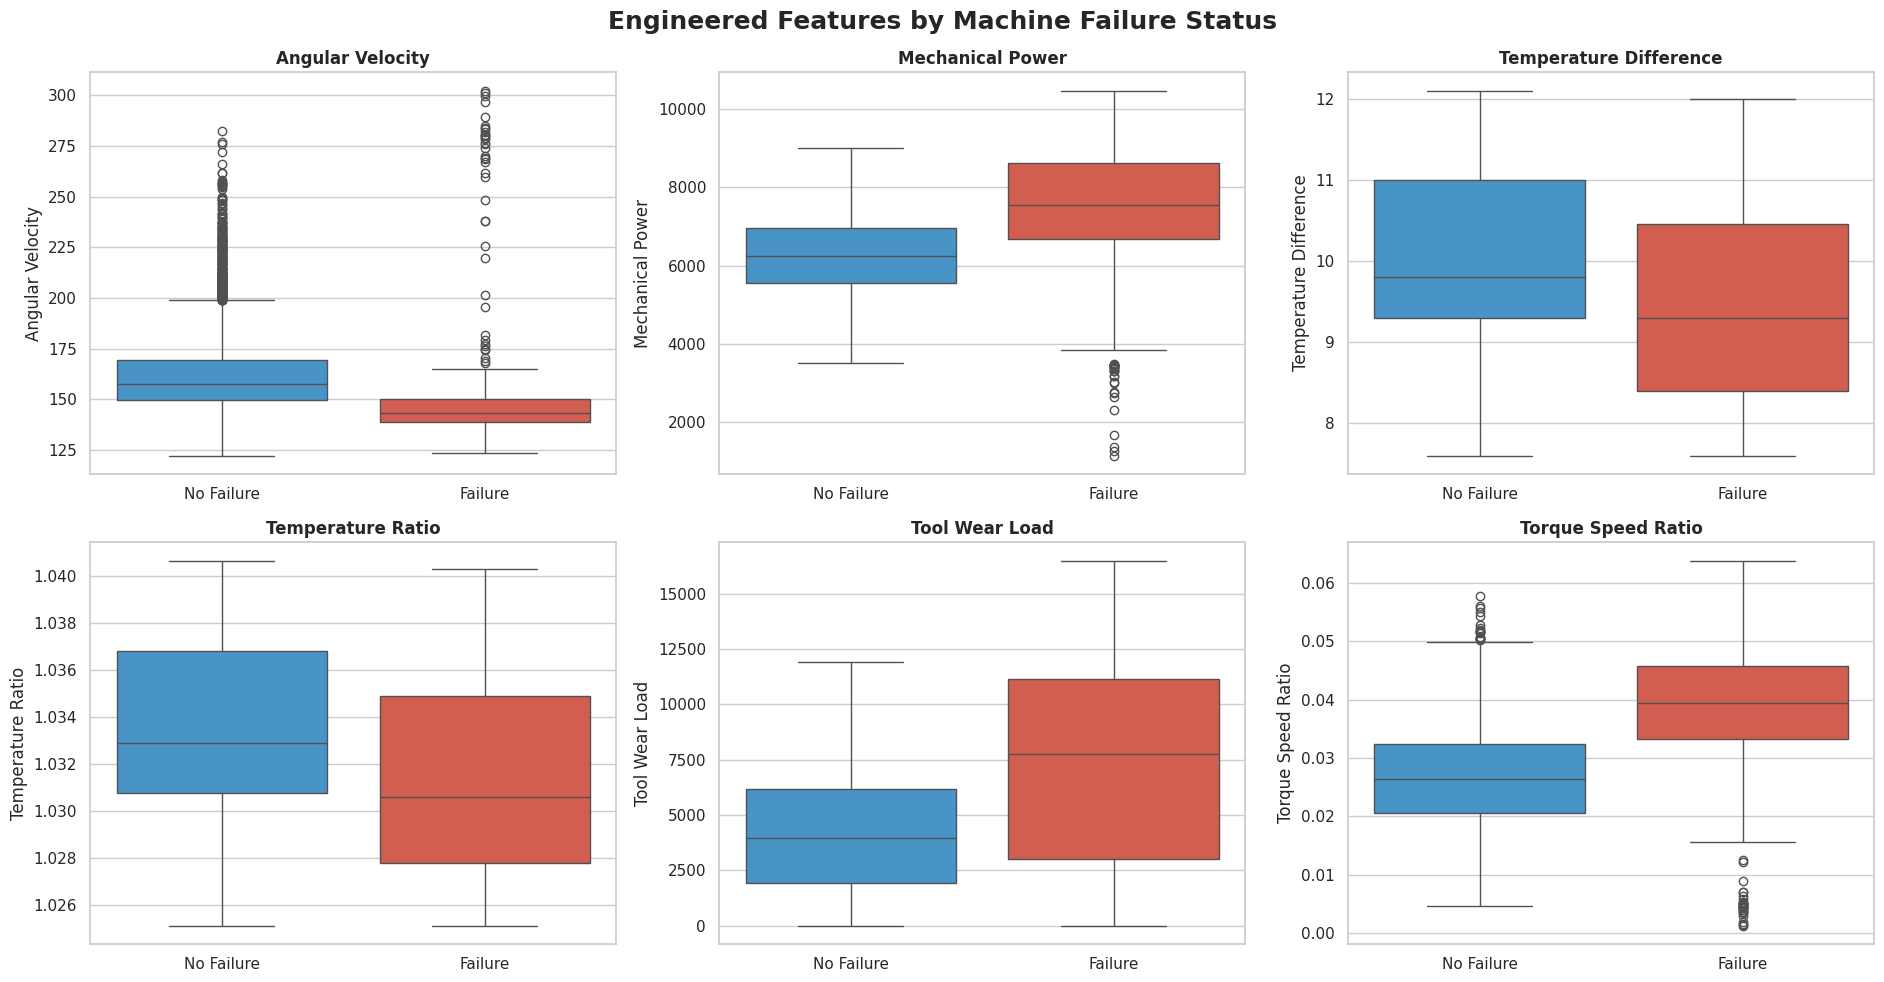

In [44]:
# Create a temporary dataset for feature analysis
engineered_analysis = train_engineered.copy()

engineered_analysis["Failure Status"] = (
    train_df["Machine failure"].map({
        0: "No Failure",
        1: "Failure"
    })
)

# Visualize engineered feature distributions
fig, axes = plt.subplots(2, 3, figsize=(19, 10))

axes = axes.flatten()

for ax, feature in zip(axes, engineered_features):

    sns.boxplot(
        data=engineered_analysis,
        x="Failure Status",
        y=feature,
        hue="Failure Status",
        palette={
            "No Failure": "#3498db",
            "Failure": "#e74c3c"
        },
        order=["No Failure", "Failure"],
        legend=False,
        ax=ax
    )

    ax.set_title(feature, fontweight="bold")
    ax.set_xlabel("")

fig.suptitle(
    "Engineered Features by Machine Failure Status",
    fontsize=18,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

,Pearson,Spearman,Absolute Pearson
Torque Speed Ratio,0.2047,0.1723,0.2047
Tool Wear Load,0.1858,0.1204,0.1858
Mechanical Power,0.1760,0.1532,0.1760
Temperature Difference,-0.1113,-0.1015,0.1113
Temperature Ratio,-0.1112,-0.1017,0.1112
Angular Velocity,-0.0400,-0.1635,0.0400


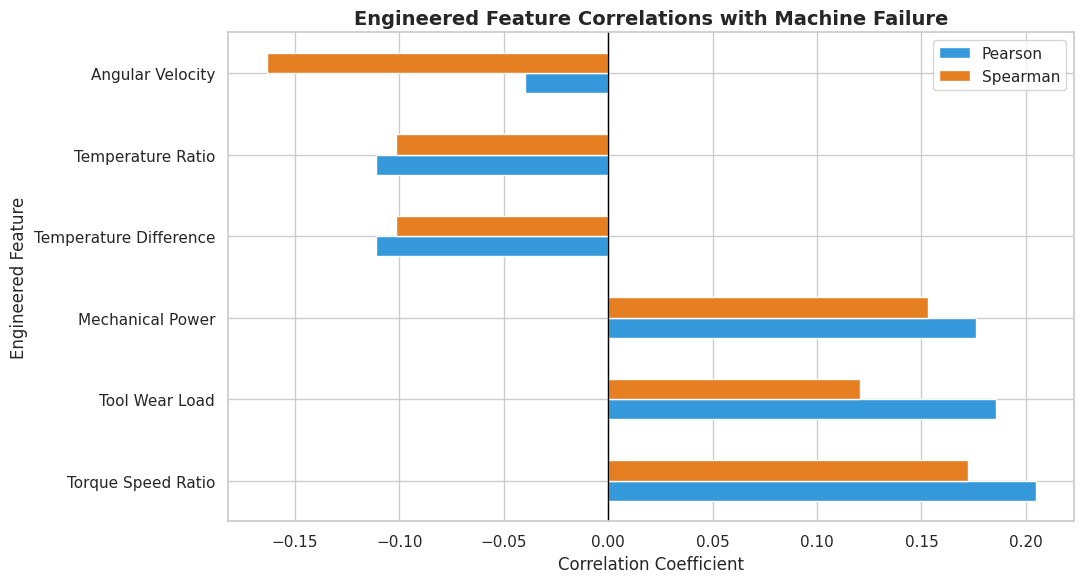

In [45]:
# Analyze engineered feature correlations with target
engineered_corr_data = train_engineered[
    engineered_features
].copy()

engineered_corr_data["Machine failure"] = (
    train_df["Machine failure"]
)

engineered_target_corr = pd.DataFrame({
    "Pearson": engineered_corr_data.corr(
        method="pearson"
    )["Machine failure"].drop("Machine failure"),

    "Spearman": engineered_corr_data.corr(
        method="spearman"
    )["Machine failure"].drop("Machine failure")
})

engineered_target_corr["Absolute Pearson"] = (
    engineered_target_corr["Pearson"].abs()
)

engineered_target_corr = engineered_target_corr.sort_values(
    "Absolute Pearson",
    ascending=False
)

display(engineered_target_corr.round(4))

# Visualize correlations
engineered_target_corr[
    ["Pearson", "Spearman"]
].plot(
    kind="barh",
    figsize=(11, 6),
    color=["#3498db", "#e67e22"]
)

plt.axvline(0, color="black", linewidth=1)

plt.title(
    "Engineered Feature Correlations with Machine Failure",
    fontsize=14,
    fontweight="bold"
)

plt.xlabel("Correlation Coefficient")
plt.ylabel("Engineered Feature")

plt.tight_layout()
plt.show()

### 5.3 Feature Redundancy Analysis

Feature redundancy is investigated using Pearson
correlation analysis across original and engineered
numerical variables.

Feature pairs with absolute correlation coefficients
of 0.95 or higher are identified for further inspection.

Deterministically redundant variables are excluded from
the final modeling feature set where appropriate.

Other highly correlated variables are evaluated based
on domain relevance and cross-validation performance.

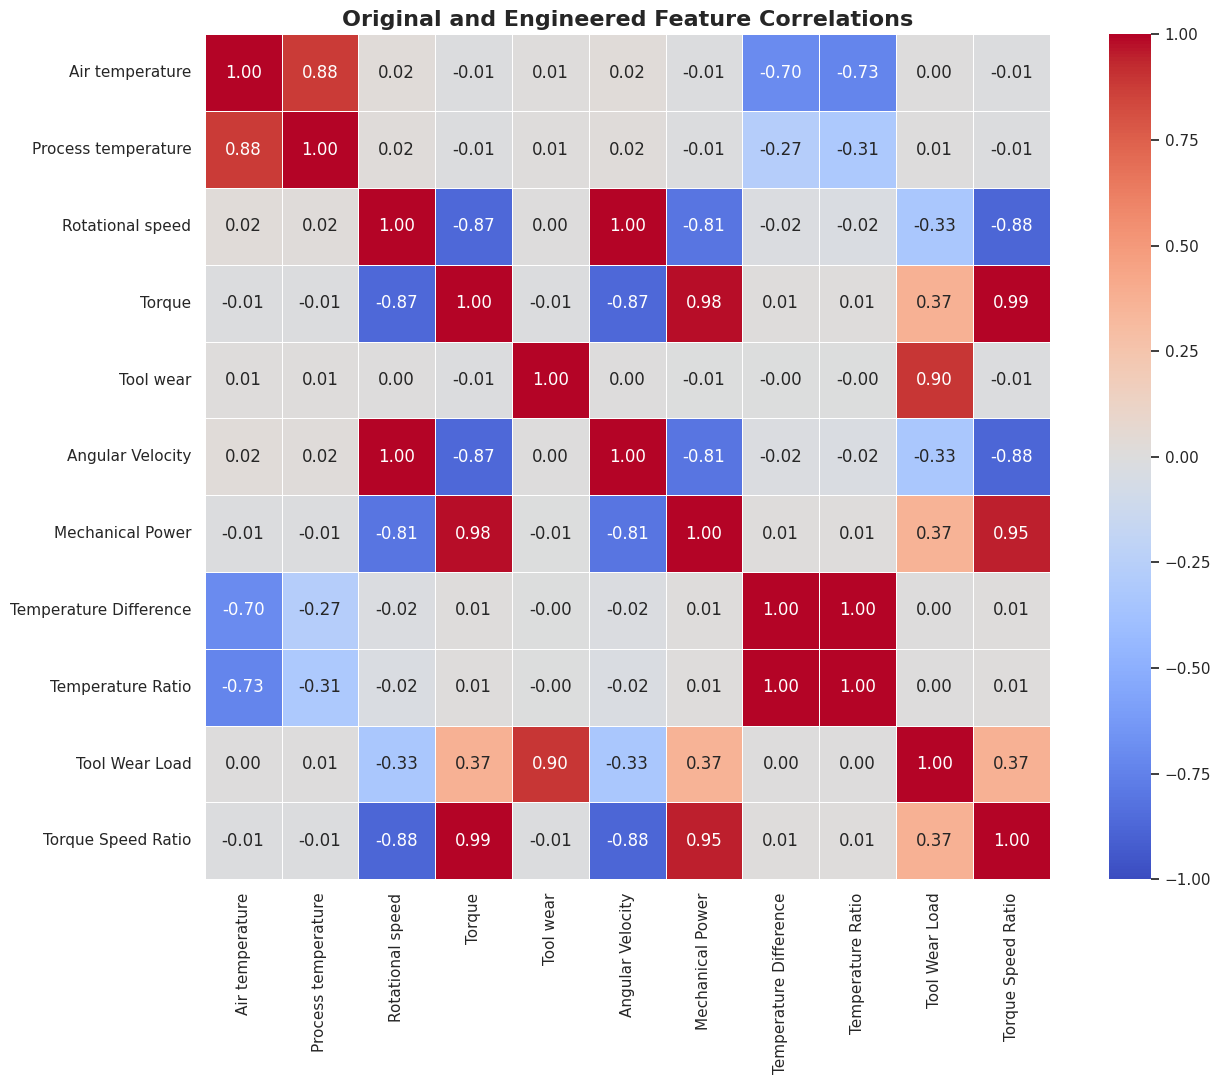

In [46]:
# Select all numerical features
all_numeric_features = (
    sensor_columns + engineered_features
)

feature_corr = train_engineered[
    all_numeric_features
].corr()

# Visualize the correlation matrix
plt.figure(figsize=(14, 11))

sns.heatmap(
    feature_corr,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    square=True,
    linewidths=0.5
)

plt.title(
    "Original and Engineered Feature Correlations",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [47]:
# Identify highly correlated feature pairs
CORRELATION_THRESHOLD = 0.95

redundant_pairs = []

for i in range(len(feature_corr.columns)):

    for j in range(i + 1, len(feature_corr.columns)):

        correlation = feature_corr.iloc[i, j]

        if abs(correlation) >= CORRELATION_THRESHOLD:

            redundant_pairs.append({
                "Feature 1": feature_corr.columns[i],
                "Feature 2": feature_corr.columns[j],
                "Correlation": correlation,
                "Absolute Correlation": abs(correlation)
            })

redundancy_df = pd.DataFrame(
    redundant_pairs,
    columns=[
        "Feature 1",
        "Feature 2",
        "Correlation",
        "Absolute Correlation"
    ]
)

display(
    redundancy_df.sort_values(
        "Absolute Correlation",
        ascending=False
    ).round(4)
)

,Feature 1,Feature 2,Correlation,Absolute Correlation
0,Rotational speed,Angular Velocity,1.0000,1.0000
3,Temperature Difference,Temperature Ratio,0.9990,0.9990
2,Torque,Torque Speed Ratio,0.9930,0.9930
1,Torque,Mechanical Power,0.9788,0.9788


In [48]:
# Remove deterministically redundant feature
excluded_features = ["Angular Velocity"]

selected_engineered_features = [
    feature
    for feature in engineered_features
    if feature not in excluded_features
]

final_features = (
    original_features + selected_engineered_features
)

print("Excluded features:", excluded_features)

print("\nFinal modeling features:")

for i, feature in enumerate(final_features, start=1):
    print(f"{i}. {feature}")

print("\nTotal features:", len(final_features))

Excluded features: ['Angular Velocity']

Final modeling features:
1. Type
2. Air temperature
3. Process temperature
4. Rotational speed
5. Torque
6. Tool wear
7. Mechanical Power
8. Temperature Difference
9. Temperature Ratio
10. Tool Wear Load
11. Torque Speed Ratio

Total features: 11


### 5.4 Data Preprocessing Pipeline

A reusable preprocessing architecture is implemented
using Scikit-learn pipelines and ColumnTransformer.

Numerical preprocessing:
- Median imputation for missing values.
- Standardization using StandardScaler.

Categorical preprocessing:
- Most frequent value imputation.
- One-hot encoding with unknown category handling.

The preprocessing steps are integrated into model
pipelines to ensure that transformations are fitted
exclusively on training folds during cross-validation.

This approach prevents data leakage and supports
reproducible model development.

In [49]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    StandardScaler,
    OneHotEncoder
)
from sklearn.impute import SimpleImputer

# Create a reusable preprocessing function
def build_preprocessor(feature_names, scale=True):

    categorical_columns = [
        feature for feature in feature_names
        if feature == "Type"
    ]

    numerical_columns = [
        feature for feature in feature_names
        if feature != "Type"
    ]

    # Numerical preprocessing
    numerical_steps = [
        ("imputer", SimpleImputer(strategy="median"))
    ]

    if scale:
        numerical_steps.append(
            ("scaler", StandardScaler())
        )

    numerical_pipeline = Pipeline(
        steps=numerical_steps
    )

    # Categorical preprocessing
    categorical_pipeline = Pipeline(steps=[
        (
            "imputer",
            SimpleImputer(strategy="most_frequent")
        ),
        (
            "encoder",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            )
        )
    ])

    # Combine preprocessing transformations
    preprocessor = ColumnTransformer(
        transformers=[
            (
                "numerical",
                numerical_pipeline,
                numerical_columns
            ),
            (
                "categorical",
                categorical_pipeline,
                categorical_columns
            )
        ],
        remainder="drop"
    )

    return preprocessor

preprocessor = build_preprocessor(final_features)

print("Preprocessing pipeline successfully created.")

display(preprocessor)

Preprocessing pipeline successfully created.


ColumnTransformer(transformers=[('numerical',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['Air temperature', 'Process temperature',
                                  'Rotational speed', 'Torque', 'Tool wear',
                                  'Mechanical Power', 'Temperature Difference',
                                  'Temperature Ratio', 'Tool Wear Load',
                                  'Torque Speed Ratio']),
                                ('categorical',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encoder',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False))]),
                                 ['Type'])])

### 5.5 Final Feature Preparation

Two feature configurations are prepared for comparative
machine learning experiments.

Configuration A:
Original operational features.

Configuration B:
Original features combined with selected physics-informed
engineered features.

Both configurations use identical training and testing
observations to support a fair comparison.

Cross-validation performance will be used to evaluate
the predictive contribution of feature engineering.

The held-out test dataset remains reserved for final
model evaluation.

In [50]:
# Configuration A: Original features
X_train_original = train_engineered[
    original_features
].copy()

X_test_original = test_engineered[
    original_features
].copy()

# Configuration B: Original + engineered features
X_train = train_engineered[
    final_features
].copy()

X_test = test_engineered[
    final_features
].copy()

# Target variables
y_train = train_df["Machine failure"].astype(int)
y_test = test_df["Machine failure"].astype(int)

# Verify feature and target alignment
assert X_train.index.equals(y_train.index)
assert X_test.index.equals(y_test.index)

assert X_train_original.index.equals(y_train.index)
assert X_test_original.index.equals(y_test.index)

assert set(X_train.index).isdisjoint(X_test.index)

# Verify absence of target leakage
forbidden_features = [
    "Machine failure",
    "TWF", "HDF", "PWF", "OSF", "RNF"
]

assert not any(
    feature in X_train.columns
    for feature in forbidden_features
)

# Summarize dataset configurations
feature_set_summary = pd.DataFrame({
    "Feature Configuration": [
        "Original",
        "Physics-Informed"
    ],
    "Training Samples": [
        X_train_original.shape[0],
        X_train.shape[0]
    ],
    "Testing Samples": [
        X_test_original.shape[0],
        X_test.shape[0]
    ],
    "Number of Features": [
        X_train_original.shape[1],
        X_train.shape[1]
    ]
})

display(feature_set_summary)

print("Feature preparation successfully completed.")

,Feature Configuration,Training Samples,Testing Samples,Number of Features
0,Original,8000,2000,6
1,Physics-Informed,8000,2000,11


Feature preparation successfully completed.


## 6. Machine Learning

Multiple supervised machine learning algorithms are
developed and compared for binary machine failure
classification.

The experimental framework includes:

- Dummy Classifier as a baseline.
- Logistic Regression.
- Random Forest.
- XGBoost.
- LightGBM.

### 6.1 Machine Learning Framework

Models are evaluated using stratified cross-validation,
imbalance-aware training strategies, and multiple
classification metrics.

Original and physics-informed feature configurations
are compared under identical experimental conditions.

The held-out test dataset is reserved exclusively for
final evaluation after model selection and optimization.

In [51]:
# Machine learning algorithms
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier

# Model validation
from sklearn.model_selection import (
    StratifiedKFold,
    cross_validate,
    cross_val_predict
)

# Evaluation metrics
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    average_precision_score,
    confusion_matrix,
    classification_report,
    precision_recall_curve,
    roc_curve,
    make_scorer
)

from sklearn.base import clone
from sklearn.utils.class_weight import compute_class_weight

import time

print("Machine learning libraries successfully imported.")

Machine learning libraries successfully imported.


### 6.2 Cross-Validation Strategy

Stratified 5-Fold Cross-Validation is used to evaluate
model generalization on unseen validation observations.

Stratification preserves the approximate proportion
of failure and non-failure observations in each fold.

Identical cross-validation splits are used across all
models and feature configurations.

Preprocessing transformations are fitted independently
within each training fold to prevent data leakage.

In [52]:
# Configure cross-validation
N_SPLITS = 5

cv_strategy = StratifiedKFold(
    n_splits=N_SPLITS,
    shuffle=True,
    random_state=RANDOM_STATE
)

# Inspect cross-validation splits
fold_summary = []

for fold, (train_idx, val_idx) in enumerate(
    cv_strategy.split(X_train, y_train),
    start=1
):

    fold_y_train = y_train.iloc[train_idx]
    fold_y_val = y_train.iloc[val_idx]

    fold_summary.append({
        "Fold": fold,
        "Training Samples": len(train_idx),
        "Validation Samples": len(val_idx),
        "Training Failures": fold_y_train.sum(),
        "Validation Failures": fold_y_val.sum(),
        "Training Failure Rate (%)": (
            fold_y_train.mean() * 100
        ),
        "Validation Failure Rate (%)": (
            fold_y_val.mean() * 100
        )
    })

cv_summary = pd.DataFrame(fold_summary)

display(cv_summary.round(3))

,Fold,Training Samples,Validation Samples,Training Failures,Validation Failures,Training Failure Rate (%),Validation Failure Rate (%)
0,1,6400,1600,217,54,3.391,3.375
1,2,6400,1600,217,54,3.391,3.375
2,3,6400,1600,217,54,3.391,3.375
3,4,6400,1600,217,54,3.391,3.375
4,5,6400,1600,216,55,3.375,3.438


### 6.3 Class Imbalance Strategy

The dataset exhibits substantial class imbalance,
with machine failures representing a small proportion
of all observations.

Class weighting is used to increase the contribution
of minority-class observations during model training.

Class weights are calculated from training observations.
Models with automatic balanced class weighting compute
their weights independently during each fit.

Accuracy is reported for completeness but is not used
as the primary model selection criterion.

Average Precision is selected as the primary metric,
supported by Recall, Precision, F1-score, Balanced
Accuracy, and ROC-AUC.

In [53]:
# Inspect training class distribution
class_distribution = y_train.value_counts().sort_index()

n_negative = class_distribution.loc[0]
n_positive = class_distribution.loc[1]

# Calculate class imbalance ratio
imbalance_ratio = n_negative / n_positive

# Calculate balanced class weights for inspection
classes = np.array([0, 1])

weights = compute_class_weight(
    class_weight="balanced",
    classes=classes,
    y=y_train
)

class_weights = dict(zip(classes, weights))

imbalance_summary = pd.DataFrame({
    "Class": ["No Failure", "Failure"],
    "Count": [n_negative, n_positive],
    "Percentage (%)": [
        n_negative / len(y_train) * 100,
        n_positive / len(y_train) * 100
    ],
    "Balanced Class Weight": [
        class_weights[0],
        class_weights[1]
    ]
})

display(imbalance_summary.round(4))

print(f"Imbalance Ratio: {imbalance_ratio:.2f}:1")

,Class,Count,Percentage (%),Balanced Class Weight
0,No Failure,7729,96.6125,0.5175
1,Failure,271,3.3875,14.7601


Imbalance Ratio: 28.52:1


In [54]:
# Define evaluation metrics
scoring = {
    "accuracy": "accuracy",

    "balanced_accuracy": "balanced_accuracy",

    "precision": make_scorer(
        precision_score,
        zero_division=0
    ),

    "recall": make_scorer(
        recall_score,
        zero_division=0
    ),

    "f1": make_scorer(
        f1_score,
        zero_division=0
    ),

    "roc_auc": "roc_auc",

    "average_precision": "average_precision"
}

# Primary model selection metric
PRIMARY_METRIC = "average_precision"

print("Evaluation metrics:")

for metric in scoring:
    print(f"- {metric}")

print(f"\nPrimary Metric: {PRIMARY_METRIC}")

Evaluation metrics:
- accuracy
- balanced_accuracy
- precision
- recall
- f1
- roc_auc
- average_precision

Primary Metric: average_precision


### 6.4 Model Configuration

Five classification algorithms are configured using
initial hyperparameter settings.

Class imbalance is addressed through class weighting
and balanced sample weighting where applicable.

Logistic Regression uses standardized numerical
features, while tree-based algorithms operate on
unscaled numerical features.

Each classifier is integrated with a preprocessing
pipeline to ensure consistent and leakage-aware
training and validation.

Hyperparameter optimization is performed in a
subsequent experimental stage.

In [55]:
# Define initial machine learning models
models = {

    "Dummy Classifier": DummyClassifier(
        strategy="prior"
    ),

    "Logistic Regression": LogisticRegression(
        C=1.0,
        max_iter=2000,
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=200,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        n_jobs=1
    ),

    "XGBoost": XGBClassifier(
        n_estimators=200,
        learning_rate=0.05,
        max_depth=5,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=RANDOM_STATE,
        n_jobs=1
    ),

    "LightGBM": LGBMClassifier(
        n_estimators=200,
        learning_rate=0.05,
        num_leaves=31,
        class_weight="balanced",
        random_state=RANDOM_STATE,
        verbosity=-1,
        n_jobs=1
    )
}

print("Configured machine learning models:")

for model_name in models:
    print(f"- {model_name}")

Configured machine learning models:
- Dummy Classifier
- Logistic Regression
- Random Forest
- XGBoost
- LightGBM


In [56]:
# Create a complete ML pipeline
def create_model_pipeline(
    model,
    feature_names
):

    use_scaling = isinstance(
        model,
        LogisticRegression
    )

    preprocessing = build_preprocessor(
        feature_names=feature_names,
        scale=use_scaling
    )

    pipeline = Pipeline(steps=[
        ("preprocessor", preprocessing),
        ("classifier", clone(model))
    ])

    return pipeline

In [57]:
# Create a reusable model pipeline
def build_model_pipeline(model_name, model, features):

    # Scaling is required for Logistic Regression
    use_scaling = (
        model_name == "Logistic Regression"
    )

    # Build preprocessing component
    model_preprocessor = build_preprocessor(
        feature_names=features,
        scale=use_scaling
    )

    # Combine preprocessing and classifier
    model_pipeline = Pipeline(steps=[

        ("preprocessor", model_preprocessor),

        ("classifier", clone(model))

    ])

    return model_pipeline

### 6.5 Model Training and Comparison

All configured models are evaluated using stratified
5-fold cross-validation on the physics-informed
feature configuration.

For XGBoost, balanced sample weights are calculated
independently within each training fold.

Mean validation scores and standard deviations are
reported to assess predictive performance and
consistency across folds.

Average Precision is used as the primary ranking
metric because of the substantial class imbalance.

Training performance is also recorded to investigate
potential overfitting.

The held-out test dataset is not used during model
comparison.

In [58]:
from sklearn.utils.class_weight import compute_sample_weight

# Define reusable cross-validation evaluation function
def evaluate_model(model_name, model, X, y, features):

    fold_results = []

    for fold, (train_idx, val_idx) in enumerate(
        cv_strategy.split(X, y),
        start=1
    ):

        # Prepare fold-specific datasets
        X_fold_train = X.iloc[train_idx]
        X_fold_val = X.iloc[val_idx]

        y_fold_train = y.iloc[train_idx]
        y_fold_val = y.iloc[val_idx]

        # Create independent pipeline for each fold
        pipeline = build_model_pipeline(
            model_name,
            model,
            features
        )

        start_time = time.perf_counter()

        # Apply fold-specific weighting for XGBoost
        if model_name == "XGBoost":

            sample_weights = compute_sample_weight(
                class_weight="balanced",
                y=y_fold_train
            )

            pipeline.fit(
                X_fold_train,
                y_fold_train,
                classifier__sample_weight=sample_weights
            )

        else:

            pipeline.fit(
                X_fold_train,
                y_fold_train
            )

        fit_time = time.perf_counter() - start_time

        # Generate validation predictions
        y_pred = pipeline.predict(X_fold_val)

        y_prob = pipeline.predict_proba(
            X_fold_val
        )[:, 1]

        # Generate training probabilities
        y_train_prob = pipeline.predict_proba(
            X_fold_train
        )[:, 1]

        # Store evaluation metrics
        fold_results.append({

            "Model": model_name,

            "Fold": fold,

            "Accuracy": accuracy_score(
                y_fold_val, y_pred
            ),

            "Balanced Accuracy": balanced_accuracy_score(
                y_fold_val, y_pred
            ),

            "Precision": precision_score(
                y_fold_val, y_pred,
                zero_division=0
            ),

            "Recall": recall_score(
                y_fold_val, y_pred,
                zero_division=0
            ),

            "F1-score": f1_score(
                y_fold_val, y_pred,
                zero_division=0
            ),

            "ROC-AUC": roc_auc_score(
                y_fold_val, y_prob
            ),

            "Average Precision": average_precision_score(
                y_fold_val, y_prob
            ),

            "Train Average Precision": average_precision_score(
                y_fold_train, y_train_prob
            ),

            "Fit Time (s)": fit_time

        })

    return pd.DataFrame(fold_results)

In [60]:
# Define experimental feature configurations
feature_configurations = {

    "Original": {
        "X": X_train_original,
        "features": original_features
    },

    "Physics-Informed": {
        "X": X_train,
        "features": final_features
    }
}

print("Experimental configurations:")

for name, config in feature_configurations.items():

    print(
        f"{name}: "
        f"{len(config['features'])} features"
    )

Experimental configurations:
Original: 6 features
Physics-Informed: 11 features


In [61]:
# Run cross-validation experiments
experiment_results = []

for feature_set, config in feature_configurations.items():

    print("=" * 60)
    print(f"FEATURE SET: {feature_set}")
    print("=" * 60)

    for model_name, model in models.items():

        print(f"Training: {model_name}")

        model_results = evaluate_model(
            model_name=model_name,
            model=model,
            X=config["X"],
            y=y_train,
            features=config["features"]
        )

        model_results["Feature_Set"] = feature_set

        experiment_results.append(model_results)

        mean_ap = model_results[
            "Average Precision"
        ].mean()

        print(f"Mean Average Precision: {mean_ap:.4f}")
        print("-" * 40)

# Combine all fold-level results
cv_fold_results = pd.concat(
    experiment_results,
    ignore_index=True
)

print("All experiments completed.")

display(cv_fold_results.head())

FEATURE SET: Original
Training: Dummy Classifier
Mean Average Precision: 0.0339
----------------------------------------
Training: Logistic Regression
Mean Average Precision: 0.4409
----------------------------------------
Training: Random Forest
Mean Average Precision: 0.7511
----------------------------------------
Training: XGBoost
Mean Average Precision: 0.7748
----------------------------------------
Training: LightGBM


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ut

Mean Average Precision: 0.7802
----------------------------------------
FEATURE SET: Physics-Informed
Training: Dummy Classifier
Mean Average Precision: 0.0339
----------------------------------------
Training: Logistic Regression
Mean Average Precision: 0.4449
----------------------------------------
Training: Random Forest
Mean Average Precision: 0.8853
----------------------------------------
Training: XGBoost
Mean Average Precision: 0.8883
----------------------------------------
Training: LightGBM


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/ut

Mean Average Precision: 0.8846
----------------------------------------
All experiments completed.


,Model,Fold,Accuracy,Balanced Accuracy,Precision,Recall,F1-score,ROC-AUC,Average Precision,Train Average Precision,Fit Time (s),Feature_Set
0,Dummy Classifier,1,0.966250,0.5,0.0,0.0,0.0,0.5,0.033750,0.033906,0.133538,Original
1,Dummy Classifier,2,0.966250,0.5,0.0,0.0,0.0,0.5,0.033750,0.033906,0.097885,Original
2,Dummy Classifier,3,0.966250,0.5,0.0,0.0,0.0,0.5,0.033750,0.033906,0.105065,Original
3,Dummy Classifier,4,0.966250,0.5,0.0,0.0,0.0,0.5,0.033750,0.033906,0.124018,Original
4,Dummy Classifier,5,0.965625,0.5,0.0,0.0,0.0,0.5,0.034375,0.033750,0.026500,Original


#### 6.5.2 Cross-Validation Results Summary

Fold-level evaluation results are aggregated to compare
the predictive performance of all machine learning
models across both feature configurations.

Mean performance measures and standard deviations
are calculated to assess predictive quality and
performance variability.

Training and validation Average Precision scores
are compared to investigate potential overfitting.

In [62]:
# Define metrics for aggregation
evaluation_metrics = [
    "Accuracy",
    "Balanced Accuracy",
    "Precision",
    "Recall",
    "F1-score",
    "ROC-AUC",
    "Average Precision",
    "Train Average Precision",
    "Fit Time (s)"
]

# Aggregate cross-validation results
cv_summary_results = (
    cv_fold_results
    .groupby(["Model", "Feature_Set"])[evaluation_metrics]
    .agg(["mean", "std"])
)

# Flatten multi-level column names
cv_summary_results.columns = [
    f"{metric}_{statistic}"
    for metric, statistic in cv_summary_results.columns
]

cv_summary_results = (
    cv_summary_results
    .reset_index()
    .sort_values(
        "Average Precision_mean",
        ascending=False
    )
    .reset_index(drop=True)
)

display(cv_summary_results.round(4))

,Model,Feature_Set,Accuracy_mean,Accuracy_std,Balanced Accuracy_mean,Balanced Accuracy_std,Precision_mean,Precision_std,Recall_mean,Recall_std,F1-score_mean,F1-score_std,ROC-AUC_mean,ROC-AUC_std,Average Precision_mean,Average Precision_std,Train Average Precision_mean,Train Average Precision_std,Fit Time (s)_mean,Fit Time (s)_std
0,XGBoost,Physics-Informed,0.9885,0.0016,0.9121,0.0157,0.8352,0.0565,0.8301,0.0339,0.8308,0.0156,0.9799,0.0125,0.8883,0.0185,0.9995,0.0003,0.8772,0.2602
1,Random Forest,Physics-Informed,0.9909,0.0020,0.8706,0.0255,0.9852,0.0222,0.7417,0.0508,0.8456,0.0370,0.9722,0.0142,0.8853,0.0294,1.0000,0.0000,3.0141,0.3918
2,LightGBM,Physics-Informed,0.9891,0.0018,0.9053,0.0219,0.8573,0.0305,0.8154,0.0438,0.8352,0.0297,0.9763,0.0155,0.8846,0.0319,1.0000,0.0000,0.6535,0.2145
3,LightGBM,Original,0.9802,0.0040,0.8794,0.0200,0.6889,0.0647,0.7712,0.0386,0.7266,0.0467,0.9719,0.0118,0.7802,0.0498,1.0000,0.0000,0.7674,0.6097
4,XGBoost,Original,0.9699,0.0042,0.8901,0.0137,0.5401,0.0461,0.8044,0.0279,0.6452,0.0330,0.9750,0.0090,0.7748,0.0357,0.9938,0.0016,0.4441,0.1078
5,Random Forest,Original,0.9770,0.0017,0.6820,0.0211,0.8909,0.0281,0.3655,0.0420,0.5176,0.0460,0.9644,0.0157,0.7511,0.0334,1.0000,0.0000,3.3019,1.1265
6,Logistic Regression,Physics-Informed,0.8464,0.0101,0.8440,0.0218,0.1615,0.0075,0.8415,0.0509,0.2708,0.0110,0.9232,0.0150,0.4449,0.0455,0.4426,0.0094,0.1916,0.0362
7,Logistic Regression,Original,0.8225,0.0082,0.8138,0.0328,0.1374,0.0057,0.8044,0.0747,0.2346,0.0112,0.8965,0.0174,0.4409,0.0334,0.4381,0.0094,0.1529,0.0243
8,Dummy Classifier,Physics-Informed,0.9661,0.0003,0.5000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.5000,0.0000,0.0339,0.0003,0.0339,0.0001,0.0301,0.0017
9,Dummy Classifier,Original,0.9661,0.0003,0.5000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.5000,0.0000,0.0339,0.0003,0.0339,0.0001,0.0974,0.0421


In [63]:
# Create concise performance ranking
model_ranking = cv_summary_results[[
    "Model",
    "Feature_Set",
    "Average Precision_mean",
    "Average Precision_std",
    "ROC-AUC_mean",
    "Recall_mean",
    "Precision_mean",
    "F1-score_mean",
    "Balanced Accuracy_mean",
    "Fit Time (s)_mean"
]].copy()

model_ranking.insert(
    0,
    "Rank",
    range(1, len(model_ranking) + 1)
)

display(model_ranking.round(4))

,Rank,Model,Feature_Set,Average Precision_mean,Average Precision_std,ROC-AUC_mean,Recall_mean,Precision_mean,F1-score_mean,Balanced Accuracy_mean,Fit Time (s)_mean
0,1,XGBoost,Physics-Informed,0.8883,0.0185,0.9799,0.8301,0.8352,0.8308,0.9121,0.8772
1,2,Random Forest,Physics-Informed,0.8853,0.0294,0.9722,0.7417,0.9852,0.8456,0.8706,3.0141
2,3,LightGBM,Physics-Informed,0.8846,0.0319,0.9763,0.8154,0.8573,0.8352,0.9053,0.6535
3,4,LightGBM,Original,0.7802,0.0498,0.9719,0.7712,0.6889,0.7266,0.8794,0.7674
4,5,XGBoost,Original,0.7748,0.0357,0.9750,0.8044,0.5401,0.6452,0.8901,0.4441
5,6,Random Forest,Original,0.7511,0.0334,0.9644,0.3655,0.8909,0.5176,0.6820,3.3019
6,7,Logistic Regression,Physics-Informed,0.4449,0.0455,0.9232,0.8415,0.1615,0.2708,0.8440,0.1916
7,8,Logistic Regression,Original,0.4409,0.0334,0.8965,0.8044,0.1374,0.2346,0.8138,0.1529
8,9,Dummy Classifier,Physics-Informed,0.0339,0.0003,0.5000,0.0000,0.0000,0.0000,0.5000,0.0301
9,10,Dummy Classifier,Original,0.0339,0.0003,0.5000,0.0000,0.0000,0.0000,0.5000,0.0974


#### 6.5.4 Overfitting Analysis

Potential overfitting is investigated by comparing
training and validation Average Precision scores.

A large positive generalization gap may indicate
that the model learns training-specific patterns
that do not generalize effectively to unseen data.

The generalization gap is used as a diagnostic
indicator alongside validation performance.

In [64]:
# Calculate generalization gap
overfitting_results = cv_summary_results[[
    "Model",
    "Feature_Set",
    "Train Average Precision_mean",
    "Average Precision_mean"
]].copy()

overfitting_results["Generalization Gap"] = (
    overfitting_results["Train Average Precision_mean"]
    -
    overfitting_results["Average Precision_mean"]
)

overfitting_results = overfitting_results.sort_values(
    "Generalization Gap",
    ascending=False
)

display(overfitting_results.round(4))

,Model,Feature_Set,Train Average Precision_mean,Average Precision_mean,Generalization Gap
5,Random Forest,Original,1.0000,0.7511,0.2489
3,LightGBM,Original,1.0000,0.7802,0.2198
4,XGBoost,Original,0.9938,0.7748,0.2190
2,LightGBM,Physics-Informed,1.0000,0.8846,0.1154
1,Random Forest,Physics-Informed,1.0000,0.8853,0.1147
0,XGBoost,Physics-Informed,0.9995,0.8883,0.1112
9,Dummy Classifier,Original,0.0339,0.0339,0.0000
8,Dummy Classifier,Physics-Informed,0.0339,0.0339,0.0000
6,Logistic Regression,Physics-Informed,0.4426,0.4449,-0.0023
7,Logistic Regression,Original,0.4381,0.4409,-0.0028


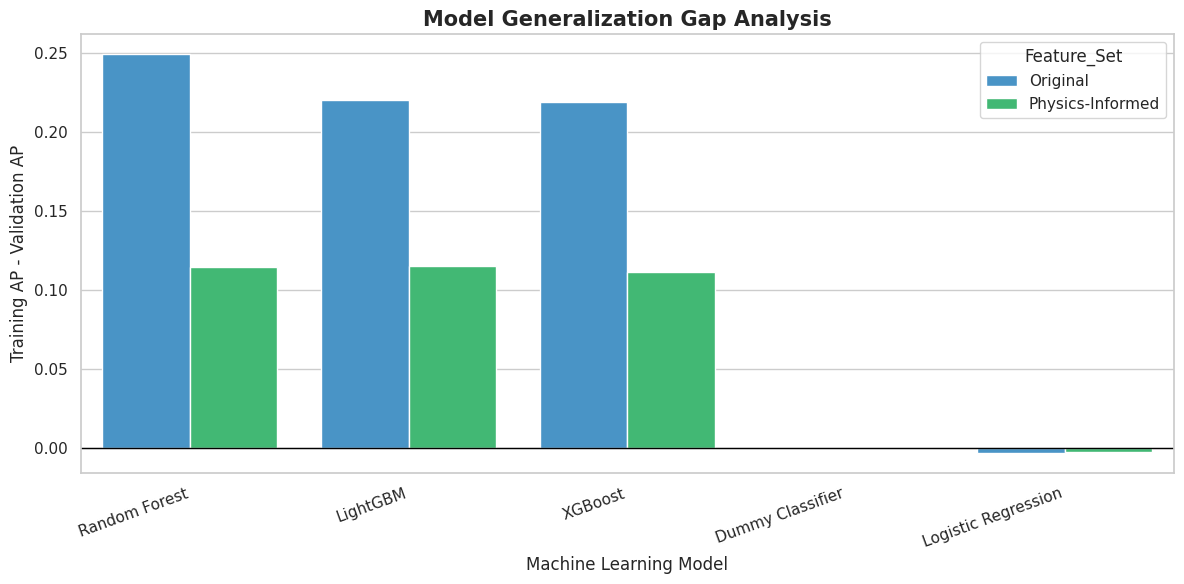

In [65]:
# Visualize generalization gaps
plt.figure(figsize=(12, 6))

sns.barplot(
    data=overfitting_results,
    x="Model",
    y="Generalization Gap",
    hue="Feature_Set",
    palette=["#3498db", "#2ecc71"]
)

plt.axhline(
    0,
    color="black",
    linewidth=1
)

plt.title(
    "Model Generalization Gap Analysis",
    fontsize=15,
    fontweight="bold"
)

plt.ylabel("Training AP - Validation AP")
plt.xlabel("Machine Learning Model")

plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

### 6.6 Ablation Study

An ablation study is performed to investigate the
predictive contribution of physics-informed feature
engineering.

Two experimental configurations are compared:

- Experiment A: Original operational features.
- Experiment B: Original and engineered features.

Both configurations use identical cross-validation
splits, model settings, and evaluation metrics.

Performance improvements are quantified using absolute
and relative changes in Average Precision, alongside
Recall, F1-score, and ROC-AUC.

In [66]:
# Separate experimental configurations
original_cv_results = cv_summary_results[
    cv_summary_results["Feature_Set"] == "Original"
].copy()

engineered_cv_results = cv_summary_results[
    cv_summary_results["Feature_Set"] == "Physics-Informed"
].copy()

# Merge experimental results
ablation_results = original_cv_results.merge(
    engineered_cv_results,
    on="Model",
    suffixes=("_original", "_engineered")
)

# Define comparison metrics
comparison_metrics = [
    "Average Precision",
    "ROC-AUC",
    "Recall",
    "Precision",
    "F1-score",
    "Balanced Accuracy"
]

# Calculate absolute performance improvements
for metric in comparison_metrics:

    ablation_results[f"{metric}_Improvement"] = (
        ablation_results[f"{metric}_mean_engineered"]
        -
        ablation_results[f"{metric}_mean_original"]
    )

# Calculate relative Average Precision improvement
ablation_results["Relative AP Improvement (%)"] = (
    ablation_results["Average Precision_Improvement"]
    /
    ablation_results["Average Precision_mean_original"]
) * 100

# Sort results
ablation_results = ablation_results.sort_values(
    "Average Precision_Improvement",
    ascending=False
).reset_index(drop=True)

display(
    ablation_results[[
        "Model",
        "Average Precision_mean_original",
        "Average Precision_mean_engineered",
        "Average Precision_Improvement",
        "Relative AP Improvement (%)",
        "Recall_Improvement",
        "F1-score_Improvement",
        "ROC-AUC_Improvement"
    ]].round(4)
)

,Model,Average Precision_mean_original,Average Precision_mean_engineered,Average Precision_Improvement,Relative AP Improvement (%),Recall_Improvement,F1-score_Improvement,ROC-AUC_Improvement
0,Random Forest,0.7511,0.8853,0.1342,17.8620,0.3762,0.3281,0.0078
1,XGBoost,0.7748,0.8883,0.1135,14.6521,0.0257,0.1856,0.0050
2,LightGBM,0.7802,0.8846,0.1045,13.3907,0.0442,0.1086,0.0045
3,Logistic Regression,0.4409,0.4449,0.0040,0.9033,0.0370,0.0363,0.0267
4,Dummy Classifier,0.0339,0.0339,0.0000,0.0000,0.0000,0.0000,0.0000


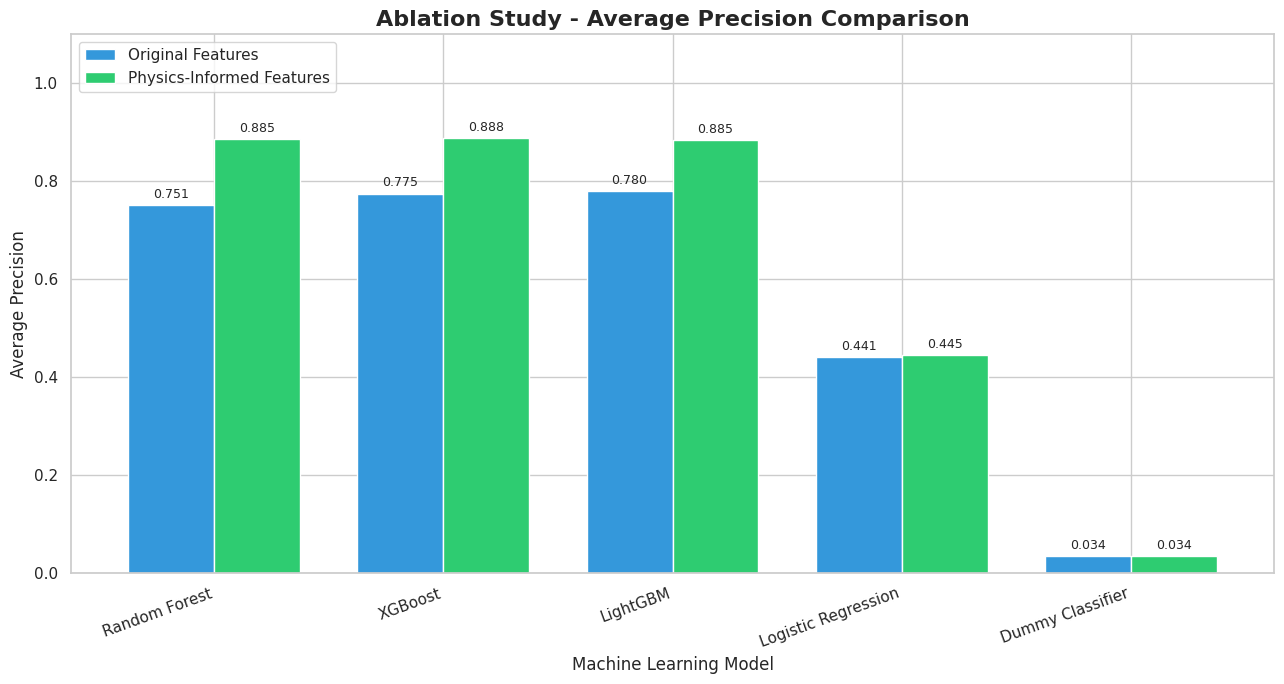

In [67]:
# Prepare comparison data
ablation_plot = ablation_results.set_index("Model")[[
    "Average Precision_mean_original",
    "Average Precision_mean_engineered"
]]

ablation_plot.columns = [
    "Original Features",
    "Physics-Informed Features"
]

# Visualize model comparison
ax = ablation_plot.plot(
    kind="bar",
    figsize=(13, 7),
    color=["#3498db", "#2ecc71"],
    width=0.75
)

for container in ax.containers:

    ax.bar_label(
        container,
        fmt="%.3f",
        padding=3,
        fontsize=9
    )

plt.title(
    "Ablation Study - Average Precision Comparison",
    fontsize=16,
    fontweight="bold"
)

plt.ylabel("Average Precision")
plt.xlabel("Machine Learning Model")

plt.xticks(rotation=20, ha="right")
plt.ylim(0, 1.1)

plt.legend(loc="upper left")
plt.tight_layout()
plt.show()

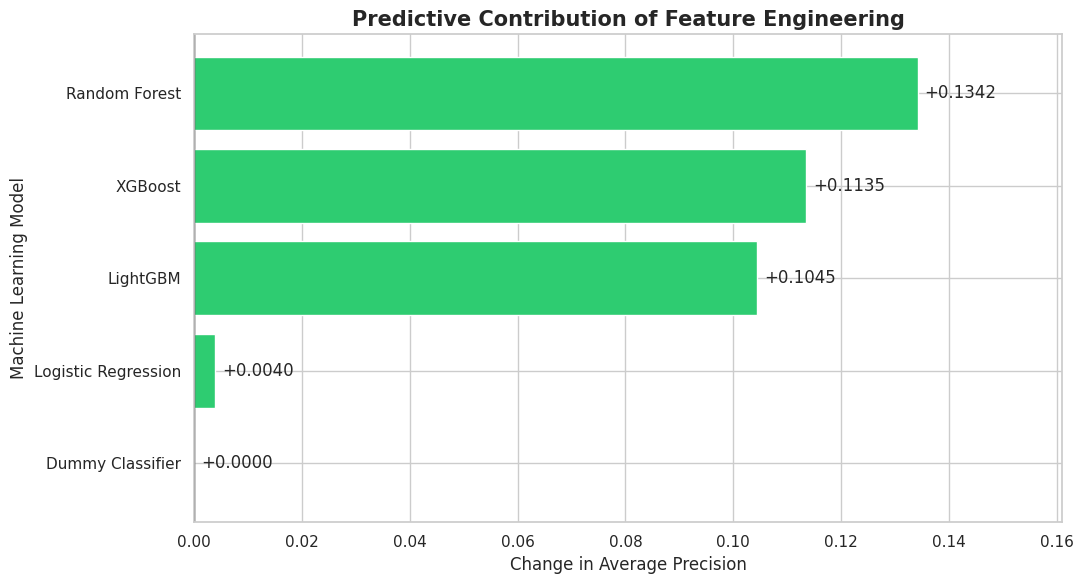

In [68]:
# Prepare improvement visualization
improvement_plot = ablation_results.sort_values(
    "Average Precision_Improvement"
)

colors = [
    "#2ecc71" if value > 0
    else "#e74c3c" if value < 0
    else "#95a5a6"

    for value in improvement_plot[
        "Average Precision_Improvement"
    ]
]

fig, ax = plt.subplots(figsize=(11, 6))

bars = ax.barh(
    improvement_plot["Model"],
    improvement_plot["Average Precision_Improvement"],
    color=colors
)

ax.bar_label(
    bars,
    fmt="%+.4f",
    padding=5
)

ax.axvline(
    0,
    color="black",
    linewidth=1
)

ax.margins(x=0.2)

ax.set_title(
    "Predictive Contribution of Feature Engineering",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Change in Average Precision")
ax.set_ylabel("Machine Learning Model")

plt.tight_layout()
plt.show()

In [69]:
# Exclude the dummy baseline from improvement analysis
ablation_candidates = ablation_results[
    ablation_results["Model"] != "Dummy Classifier"
].copy()

# Identify the model with the largest AP improvement
largest_improvement = ablation_candidates.loc[
    ablation_candidates[
        "Average Precision_Improvement"
    ].idxmax()
]

# Count improved models
improved_models = (
    ablation_candidates[
        "Average Precision_Improvement"
    ] > 0
).sum()

# Calculate mean improvement
mean_improvement = ablation_candidates[
    "Average Precision_Improvement"
].mean()

print("=" * 60)
print("ABLATION STUDY FINDINGS")
print("=" * 60)

print(
    f"Models improved: "
    f"{improved_models}/{len(ablation_candidates)}"
)

print(
    f"Model with largest AP change: "
    f"{largest_improvement['Model']}"
)

print(
    f"Largest AP change: "
    f"{largest_improvement['Average Precision_Improvement']:+.4f}"
)

print(
    f"Mean AP change: "
    f"{mean_improvement:+.4f}"
)

print("=" * 60)

ABLATION STUDY FINDINGS
Models improved: 4/4
Model with largest AP change: Random Forest
Largest AP change: +0.1342
Mean AP change: +0.0890


### 6.7 Model Selection

Model selection is based on mean validation Average
Precision obtained through stratified cross-validation.

The selection process considers both original and
physics-informed feature configurations.

Performance variability, Recall, F1-score, ROC-AUC,
and generalization gaps provide additional diagnostic
information.

The Dummy Classifier is excluded from final model
selection because it serves exclusively as a baseline.

The selected configuration proceeds to hyperparameter
optimization and decision threshold analysis.

The held-out test dataset is reserved for final
independent evaluation.

In [70]:
# Rank all model configurations
all_model_results = cv_summary_results.sort_values(
    [
        "Average Precision_mean",
        "Average Precision_std"
    ],
    ascending=[False, True]
).reset_index(drop=True)

all_model_results.insert(
    0,
    "Rank",
    range(1, len(all_model_results) + 1)
)

# Display final development-stage ranking
display(
    all_model_results[[
        "Rank",
        "Model",
        "Feature_Set",
        "Average Precision_mean",
        "Average Precision_std",
        "ROC-AUC_mean",
        "Recall_mean",
        "Precision_mean",
        "F1-score_mean"
    ]].round(4)
)

,Rank,Model,Feature_Set,Average Precision_mean,Average Precision_std,ROC-AUC_mean,Recall_mean,Precision_mean,F1-score_mean
0,1,XGBoost,Physics-Informed,0.8883,0.0185,0.9799,0.8301,0.8352,0.8308
1,2,Random Forest,Physics-Informed,0.8853,0.0294,0.9722,0.7417,0.9852,0.8456
2,3,LightGBM,Physics-Informed,0.8846,0.0319,0.9763,0.8154,0.8573,0.8352
3,4,LightGBM,Original,0.7802,0.0498,0.9719,0.7712,0.6889,0.7266
4,5,XGBoost,Original,0.7748,0.0357,0.9750,0.8044,0.5401,0.6452
5,6,Random Forest,Original,0.7511,0.0334,0.9644,0.3655,0.8909,0.5176
6,7,Logistic Regression,Physics-Informed,0.4449,0.0455,0.9232,0.8415,0.1615,0.2708
7,8,Logistic Regression,Original,0.4409,0.0334,0.8965,0.8044,0.1374,0.2346
8,9,Dummy Classifier,Physics-Informed,0.0339,0.0003,0.5000,0.0000,0.0000,0.0000
9,10,Dummy Classifier,Original,0.0339,0.0003,0.5000,0.0000,0.0000,0.0000


In [71]:
# Select the best non-baseline configuration
best_configuration = all_model_results.loc[
    all_model_results["Model"] != "Dummy Classifier"
].iloc[0]

best_model_name = best_configuration["Model"]

best_feature_set = best_configuration["Feature_Set"]

# Prepare selected feature configuration
if best_feature_set == "Original":

    X_train_selected = X_train_original.copy()
    X_test_selected = X_test_original.copy()

    selected_features = original_features.copy()

else:

    X_train_selected = X_train.copy()
    X_test_selected = X_test.copy()

    selected_features = final_features.copy()

# Clone selected model
selected_model = clone(models[best_model_name])

# Create selected pipeline
selected_pipeline = build_model_pipeline(
    best_model_name,
    selected_model,
    selected_features
)

# Calculate generalization gap
selected_generalization_gap = (
    best_configuration["Train Average Precision_mean"]
    -
    best_configuration["Average Precision_mean"]
)

print("=" * 60)
print("SELECTED MODEL CONFIGURATION")
print("=" * 60)

print(f"Model: {best_model_name}")

print(f"Feature Set: {best_feature_set}")

print(f"Number of Features: {len(selected_features)}")

print(
    f"Mean Average Precision: "
    f"{best_configuration['Average Precision_mean']:.4f}"
)

print(
    f"Average Precision Std: "
    f"{best_configuration['Average Precision_std']:.4f}"
)

print(
    f"Mean ROC-AUC: "
    f"{best_configuration['ROC-AUC_mean']:.4f}"
)

print(
    f"Mean Recall: "
    f"{best_configuration['Recall_mean']:.4f}"
)

print(
    f"Mean Precision: "
    f"{best_configuration['Precision_mean']:.4f}"
)

print(
    f"Mean F1-score: "
    f"{best_configuration['F1-score_mean']:.4f}"
)

print(
    f"Generalization Gap: "
    f"{selected_generalization_gap:.4f}"
)

print("=" * 60)

display(selected_pipeline)

SELECTED MODEL CONFIGURATION
Model: XGBoost
Feature Set: Physics-Informed
Number of Features: 11
Mean Average Precision: 0.8883
Average Precision Std: 0.0185
Mean ROC-AUC: 0.9799
Mean Recall: 0.8301
Mean Precision: 0.8352
Mean F1-score: 0.8308
Generalization Gap: 0.1112


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numerical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['Air temperature',
                                                   'Process temperature',
                                                   'Rotational speed', 'Torque',
                                                   'Tool wear',
                                                   'Mechanical Power',
                                                   'Temperature Difference',
                                                   'Temperature Ratio',
                                                   'Tool Wear Load',
                                                   'Torque Speed Ratio']),
                                                 ('categorical',
                                                  Pipeline(steps=[('imp...
                               feature_types=None, feature_weights=None,
                               gamma=None, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None, learning_rate=0.05,
                               max_bin=None, max_cat_threshold=None,
                               max_cat_to_onehot=None, max_delta_step=None,
                               max_depth=5, max_leaves=None,
                               min_child_weight=None, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=200, n_jobs=1,
                               num_parallel_tree=None, ...))])

### 6.8 Machine Learning Conclusions

Five classification algorithms were evaluated across
two feature configurations using stratified 5-fold
cross-validation.

Class imbalance was addressed through imbalance-aware
training strategies, including fold-specific sample
weighting for XGBoost.

The experimental framework included:

- Baseline model comparison.
- Cross-validation performance analysis.
- Generalization gap assessment.
- Physics-informed feature ablation.
- Average Precision-based model selection.

The selected model configuration will undergo
hyperparameter optimization and decision threshold
analysis before independent test evaluation.

Development-stage performance estimates should not
be interpreted as final test performance.

## 7. Model Optimization

### 7.1 Optimization Framework

Hyperparameter optimization is performed using Optuna
to improve the predictive performance of the selected
machine learning configuration.

A Tree-structured Parzen Estimator (TPE) sampler
is used to explore the hyperparameter search space.

The optimization framework includes:

- Model-specific hyperparameter search spaces.
- Stratified 5-fold cross-validation.
- Fold-specific class imbalance handling.
- Average Precision maximization.
- Reproducible optimization experiments.
- Decision threshold optimization.

The independent test dataset remains excluded from
hyperparameter tuning and threshold selection.

In [72]:
# Import optimization libraries
import optuna

from optuna.samplers import TPESampler

from optuna.visualization.matplotlib import (
    plot_optimization_history,
    plot_param_importances,
    plot_slice
)

# Configure optimization settings
N_TRIALS = 30

optuna.logging.set_verbosity(
    optuna.logging.WARNING
)

print("=" * 55)
print("OPTIMIZATION FRAMEWORK")
print("=" * 55)

print(f"Selected Model: {best_model_name}")
print(f"Feature Set: {best_feature_set}")
print(f"Number of Features: {len(selected_features)}")
print(f"Number of Trials: {N_TRIALS}")
print(f"Cross-Validation Folds: {N_SPLITS}")
print("Optimization Metric: Average Precision")
print("Optimization Direction: Maximize")

OPTIMIZATION FRAMEWORK
Selected Model: XGBoost
Feature Set: Physics-Informed
Number of Features: 11
Number of Trials: 30
Cross-Validation Folds: 5
Optimization Metric: Average Precision
Optimization Direction: Maximize


### 7.2 Hyperparameter Search Space

Model-specific hyperparameter search spaces are defined
to optimize predictive performance and control model
complexity.

The search process considers regularization, learning
rates, tree depth, sampling strategies, and other
algorithm-specific parameters.

The appropriate search space is selected dynamically
based on the model identified during the initial
cross-validation experiments.

Class imbalance handling is preserved throughout
the optimization process.

In [73]:
# Define model-specific hyperparameter search spaces
def suggest_hyperparameters(trial, model_name):

    if model_name == "Logistic Regression":

        return {
            "C": trial.suggest_float(
                "C", 1e-4, 100, log=True
            ),

            "penalty": trial.suggest_categorical(
                "penalty", ["l1", "l2"]
            ),

            "solver": "liblinear"
        }

    elif model_name == "Random Forest":

        return {
            "n_estimators": trial.suggest_int(
                "n_estimators", 100, 400, step=50
            ),

            "max_depth": trial.suggest_int(
                "max_depth", 3, 25
            ),

            "min_samples_split": trial.suggest_int(
                "min_samples_split", 2, 20
            ),

            "min_samples_leaf": trial.suggest_int(
                "min_samples_leaf", 1, 10
            ),

            "max_features": trial.suggest_categorical(
                "max_features", ["sqrt", "log2", None]
            )
        }

    elif model_name == "XGBoost":

        return {
            "n_estimators": trial.suggest_int(
                "n_estimators", 100, 500, step=50
            ),

            "max_depth": trial.suggest_int(
                "max_depth", 2, 8
            ),

            "learning_rate": trial.suggest_float(
                "learning_rate", 0.01, 0.2, log=True
            ),

            "subsample": trial.suggest_float(
                "subsample", 0.6, 1.0
            ),

            "colsample_bytree": trial.suggest_float(
                "colsample_bytree", 0.6, 1.0
            ),

            "min_child_weight": trial.suggest_int(
                "min_child_weight", 1, 10
            ),

            "gamma": trial.suggest_float(
                "gamma", 0.0, 5.0
            ),

            "reg_alpha": trial.suggest_float(
                "reg_alpha", 1e-6, 10, log=True
            ),

            "reg_lambda": trial.suggest_float(
                "reg_lambda", 1e-3, 10, log=True
            ),

            "scale_pos_weight": 1.0
        }

    elif model_name == "LightGBM":

        max_depth = trial.suggest_int(
            "max_depth", 3, 10
        )

        return {
            "n_estimators": trial.suggest_int(
                "n_estimators", 100, 500, step=50
            ),

            "learning_rate": trial.suggest_float(
                "learning_rate", 0.01, 0.2, log=True
            ),

            "max_depth": max_depth,

            "num_leaves": min(
                trial.suggest_int("num_leaves", 8, 63),
                2 ** max_depth
            ),

            "min_child_samples": trial.suggest_int(
                "min_child_samples", 5, 80
            ),

            "subsample": trial.suggest_float(
                "subsample", 0.6, 1.0
            ),

            "subsample_freq": 1,

            "colsample_bytree": trial.suggest_float(
                "colsample_bytree", 0.6, 1.0
            ),

            "reg_alpha": trial.suggest_float(
                "reg_alpha", 1e-6, 10, log=True
            ),

            "reg_lambda": trial.suggest_float(
                "reg_lambda", 1e-3, 10, log=True
            )
        }

    else:

        raise ValueError(
            f"Unsupported model: {model_name}"
        )

### 7.3 Objective Function

The optimization objective is defined as the mean
validation Average Precision obtained through
stratified 5-fold cross-validation.

Each optimization trial evaluates a different
hyperparameter configuration using the established
cross-validation framework.

Preprocessing and class imbalance handling remain
independent within each training fold.

Additional performance metrics are recorded to
support subsequent model comparison and analysis.

In [74]:
# Define optimization objective
def objective(trial):

    # Obtain suggested hyperparameters
    params = suggest_hyperparameters(
        trial,
        best_model_name
    )

    # Initialize independent model
    trial_model = clone(
        models[best_model_name]
    )

    trial_model.set_params(**params)

    # Evaluate current configuration
    trial_results = evaluate_model(
        model_name=best_model_name,
        model=trial_model,
        X=X_train_selected,
        y=y_train,
        features=selected_features
    )

    # Calculate primary optimization metric
    mean_ap = trial_results[
        "Average Precision"
    ].mean()

    # Record additional evaluation metrics
    trial.set_user_attr(
        "AP Std",
        float(trial_results["Average Precision"].std())
    )

    trial.set_user_attr(
        "Mean Recall",
        float(trial_results["Recall"].mean())
    )

    trial.set_user_attr(
        "Mean Precision",
        float(trial_results["Precision"].mean())
    )

    trial.set_user_attr(
        "Mean F1-score",
        float(trial_results["F1-score"].mean())
    )

    trial.set_user_attr(
        "Mean ROC-AUC",
        float(trial_results["ROC-AUC"].mean())
    )

    trial.set_user_attr(
        "Generalization Gap",
        float(
            trial_results["Train Average Precision"].mean()
            - mean_ap
        )
    )

    trial.set_user_attr(
        "Mean Fit Time",
        float(trial_results["Fit Time (s)"].mean())
    )

    trial.set_user_attr(
        "Model Parameters",
        params
    )

    return float(mean_ap)

### 7.4 Hyperparameter Optimization

An Optuna study is conducted using a seeded
Tree-structured Parzen Estimator sampler.

The optimization process evaluates 30 hyperparameter
configurations and identifies the configuration
with the highest mean validation Average Precision.

Optimization results are compared against the initial
model configuration to assess potential improvements.

The test dataset remains excluded from optimization.

In [75]:
# Initialize Optuna sampler
sampler = TPESampler(
    seed=RANDOM_STATE
)

# Create optimization study
study = optuna.create_study(
    direction="maximize",
    sampler=sampler,
    study_name="CellSense_Model_Optimization"
)

# Record optimization start time
optimization_start = time.perf_counter()

# Execute hyperparameter search
study.optimize(
    objective,
    n_trials=N_TRIALS,
    n_jobs=1,
    show_progress_bar=True
)

# Calculate total optimization time
optimization_time = (
    time.perf_counter() - optimization_start
)

print("=" * 60)
print("OPTIMIZATION RESULTS")
print("=" * 60)

print(f"Total Trials: {len(study.trials)}")

print(
    f"Optimization Time: "
    f"{optimization_time / 60:.2f} minutes"
)

print(f"Best Trial: {study.best_trial.number}")

print(
    f"Best Average Precision: "
    f"{study.best_value:.4f}"
)

print("=" * 60)

  0%|          | 0/30 [00:00<?, ?it/s]

OPTIMIZATION RESULTS
Total Trials: 30
Optimization Time: 1.72 minutes
Best Trial: 25
Best Average Precision: 0.8978


### 7.5 Optimization History

The optimization history illustrates the evolution
of validation Average Precision across Optuna trials.

The analysis provides insights into:

- Optimization convergence.
- Performance variability across trials.
- Discovery of improved hyperparameter configurations.
- Overall effectiveness of the search process.

The optimized configuration is compared against
the initial model performance.

In [76]:
# Extract optimization results
trials_df = study.trials_dataframe()

display(trials_df.head())

# Extract complete best parameter configuration
best_params = study.best_trial.user_attrs[
    "Model Parameters"
]

best_params_df = pd.DataFrame({
    "Hyperparameter": list(best_params.keys()),
    "Optimized Value": list(best_params.values())
})

print("BEST HYPERPARAMETER CONFIGURATION")

display(best_params_df)

,number,value,datetime_start,datetime_complete,duration,params_colsample_bytree,params_gamma,params_learning_rate,params_max_depth,params_min_child_weight,params_n_estimators,params_reg_alpha,params_reg_lambda,params_subsample,user_attrs_AP Std,user_attrs_Generalization Gap,user_attrs_Mean F1-score,user_attrs_Mean Fit Time,user_attrs_Mean Precision,user_attrs_Mean ROC-AUC,user_attrs_Mean Recall,user_attrs_Model Parameters,system_attrs_tpe:relative_params:0,state
0,0,0.889959,2026-11-24 11:35:37.323048,2026-11-24 11:35:41.531631,0 days 00:00:04.208583,0.662407,0.290418,0.089608,8,2,250,1.156733,0.253782,0.839463,0.019215,0.110041,0.814311,0.635928,0.804438,0.979063,0.826397,"{'n_estimators': 250, 'max_depth': 8, 'learnin...",NaN,COMPLETE
1,1,0.869435,2026-11-24 11:35:41.538739,2026-11-24 11:35:45.165130,0 days 00:00:03.626391,0.684936,0.917023,0.182760,2,2,400,0.000135,0.125610,0.932977,0.027766,0.128391,0.766752,0.576207,0.719637,0.976571,0.822828,"{'n_estimators': 400, 'max_depth': 2, 'learnin...",NaN,COMPLETE
2,2,0.882288,2026-11-24 11:35:45.171618,2026-11-24 11:35:48.124794,0 days 00:00:02.953176,0.716858,2.280350,0.062523,4,4,250,0.313496,0.006291,0.655798,0.015701,0.112148,0.753413,0.433116,0.689278,0.978759,0.833805,"{'n_estimators': 250, 'max_depth': 4, 'learnin...",NaN,COMPLETE
3,3,0.872689,2026-11-24 11:35:48.129061,2026-11-24 11:35:51.211754,0 days 00:00:03.082693,0.668210,4.744428,0.011493,6,1,300,5.746775,1.712338,0.843018,0.032196,0.082704,0.621529,0.498540,0.479294,0.982092,0.885589,"{'n_estimators': 300, 'max_depth': 6, 'learnin...",NaN,COMPLETE
4,4,0.840758,2026-11-24 11:35:51.214218,2026-11-24 11:35:52.396521,0 days 00:00:01.182303,0.648815,0.171943,0.077662,2,5,200,2.318691,0.010842,0.776061,0.024294,0.069243,0.571504,0.168420,0.417093,0.980879,0.907811,"{'n_estimators': 200, 'max_depth': 2, 'learnin...",NaN,COMPLETE


BEST HYPERPARAMETER CONFIGURATION


,Hyperparameter,Optimized Value
0,n_estimators,250.000000
1,max_depth,8.000000
2,learning_rate,0.029086
3,subsample,0.874552
4,colsample_bytree,0.924223
5,min_child_weight,2.000000
6,gamma,2.714530
7,reg_alpha,0.000245
8,reg_lambda,1.709598
9,scale_pos_weight,1.000000


/tmp/ipykernel_449/4236253224.py:2: ExperimentalWarning: optuna.visualization.matplotlib._optimization_history.plot_optimization_history is experimental (supported from v2.2.0). The interface can change in the future.
  ax = plot_optimization_history(study)


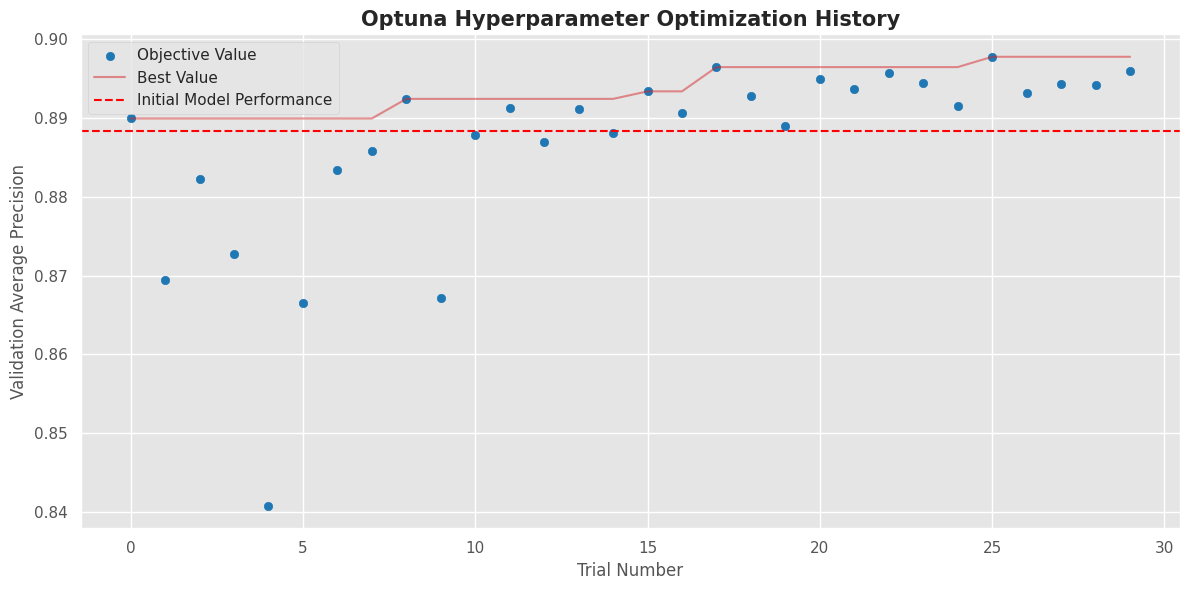

In [77]:
# Visualize optimization history
ax = plot_optimization_history(study)

ax.set_title(
    "Optuna Hyperparameter Optimization History",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Trial Number")
ax.set_ylabel("Validation Average Precision")

ax.axhline(
    best_configuration["Average Precision_mean"],
    color="red",
    linestyle="--",
    label="Initial Model Performance"
)

ax.legend()
ax.figure.set_size_inches(12, 6)

plt.tight_layout()
plt.show()

In [78]:
# Compare initial and optimized configurations
initial_ap = best_configuration[
    "Average Precision_mean"
]

optimized_ap = study.best_value

ap_difference = optimized_ap - initial_ap

relative_improvement = (
    ap_difference / initial_ap
) * 100

optimization_comparison = pd.DataFrame({

    "Metric": [
        "Average Precision",
        "Recall",
        "Precision",
        "F1-score",
        "ROC-AUC",
        "Generalization Gap"
    ],

    "Initial Model": [
        initial_ap,
        best_configuration["Recall_mean"],
        best_configuration["Precision_mean"],
        best_configuration["F1-score_mean"],
        best_configuration["ROC-AUC_mean"],
        selected_generalization_gap
    ],

    "Optimized Model": [
        optimized_ap,
        study.best_trial.user_attrs["Mean Recall"],
        study.best_trial.user_attrs["Mean Precision"],
        study.best_trial.user_attrs["Mean F1-score"],
        study.best_trial.user_attrs["Mean ROC-AUC"],
        study.best_trial.user_attrs["Generalization Gap"]
    ]
})

optimization_comparison["Change"] = (
    optimization_comparison["Optimized Model"]
    -
    optimization_comparison["Initial Model"]
)

display(optimization_comparison.round(4))

print(f"Absolute AP Change: {ap_difference:+.4f}")

print(
    f"Relative AP Change: "
    f"{relative_improvement:+.2f}%"
)

,Metric,Initial Model,Optimized Model,Change
0,Average Precision,0.8883,0.8978,0.0095
1,Recall,0.8301,0.8411,0.0110
2,Precision,0.8352,0.7027,-0.1325
3,F1-score,0.8308,0.7638,-0.0670
4,ROC-AUC,0.9799,0.9825,0.0025
5,Generalization Gap,0.1112,0.0988,-0.0124


Absolute AP Change: +0.0095
Relative AP Change: +1.07%


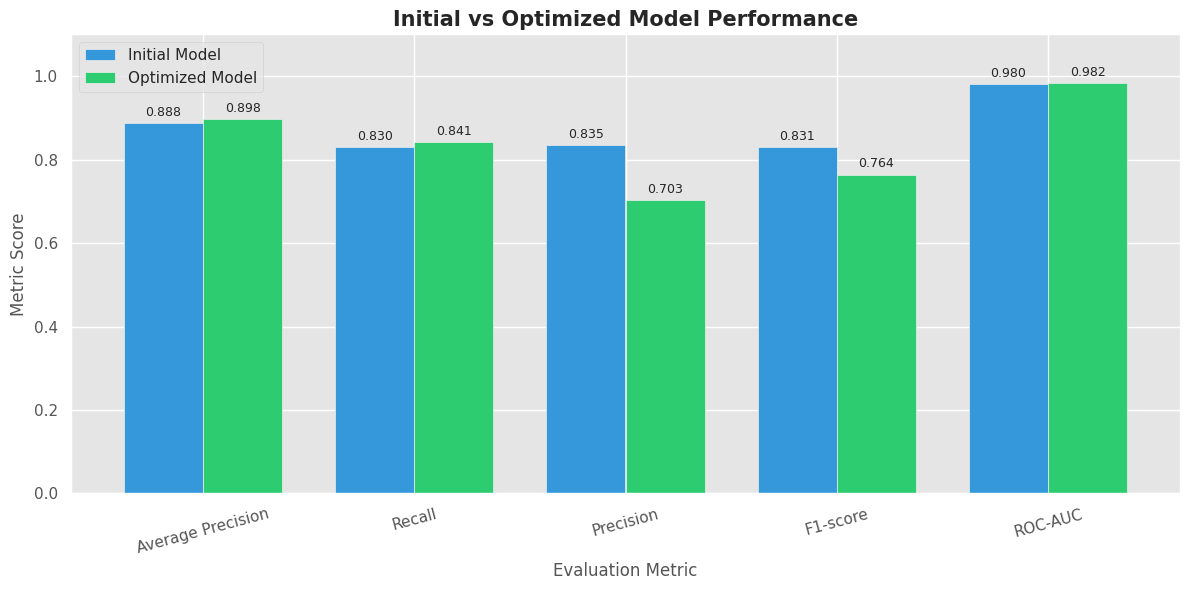

In [79]:
# Visualize performance comparison
comparison_plot = optimization_comparison[
    optimization_comparison["Metric"] !=
    "Generalization Gap"
].set_index("Metric")

ax = comparison_plot[[
    "Initial Model",
    "Optimized Model"
]].plot(
    kind="bar",
    figsize=(12, 6),
    color=["#3498db", "#2ecc71"],
    width=0.75
)

for container in ax.containers:

    ax.bar_label(
        container,
        fmt="%.3f",
        padding=3,
        fontsize=9
    )

plt.title(
    "Initial vs Optimized Model Performance",
    fontsize=15,
    fontweight="bold"
)

plt.ylabel("Metric Score")
plt.xlabel("Evaluation Metric")

plt.xticks(rotation=15)
plt.ylim(0, 1.1)

plt.tight_layout()
plt.show()

### 7.6 Hyperparameter Importance

Hyperparameter importance analysis investigates
the relative contribution of individual
hyperparameters to optimization performance.

The analysis helps identify influential parameters
within the explored search space.

Parameter importance estimates are specific to
the conducted optimization study and should not
be interpreted as causal relationships.

In [80]:
# Calculate hyperparameter importance
parameter_importance = (
    optuna.importance.get_param_importances(study)
)

parameter_importance_df = pd.DataFrame({

    "Hyperparameter": list(
        parameter_importance.keys()
    ),

    "Importance": list(
        parameter_importance.values()
    )

}).sort_values(
    "Importance",
    ascending=False
).reset_index(drop=True)

display(parameter_importance_df.round(4))

,Hyperparameter,Importance
0,reg_lambda,0.2189
1,min_child_weight,0.2040
2,n_estimators,0.1814
3,reg_alpha,0.1393
4,colsample_bytree,0.1187
5,subsample,0.0570
6,learning_rate,0.0459
7,gamma,0.0241
8,max_depth,0.0107


/tmp/ipykernel_449/1168926099.py:2: ExperimentalWarning: optuna.visualization.matplotlib._param_importances.plot_param_importances is experimental (supported from v2.2.0). The interface can change in the future.
  ax = plot_param_importances(study)


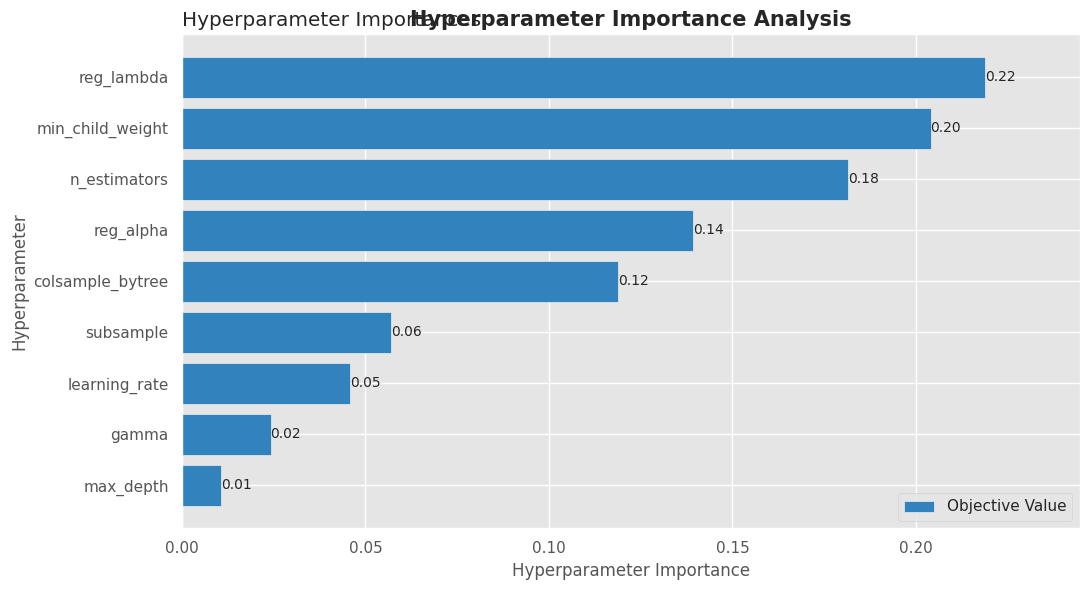

In [81]:
# Visualize hyperparameter importance
ax = plot_param_importances(study)

ax.set_title(
    "Hyperparameter Importance Analysis",
    fontsize=15,
    fontweight="bold"
)

ax.figure.set_size_inches(11, 6)

plt.tight_layout()
plt.show()

/tmp/ipykernel_449/2421852441.py:2: ExperimentalWarning: optuna.visualization.matplotlib._slice.plot_slice is experimental (supported from v2.2.0). The interface can change in the future.
  axes = plot_slice(study)
/tmp/ipykernel_449/2421852441.py:16: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


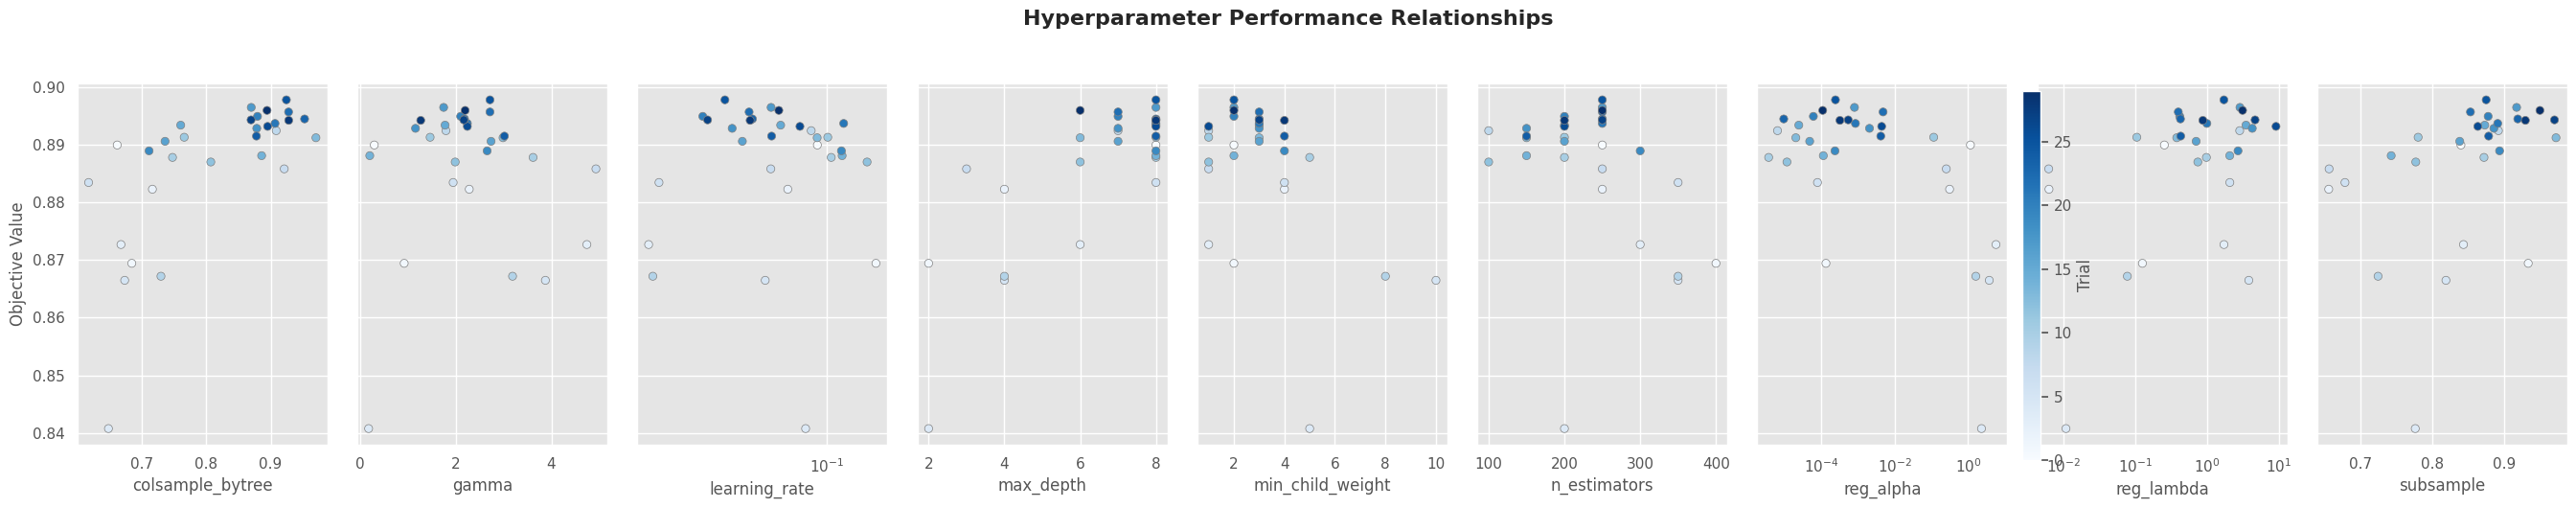

In [82]:
# Visualize parameter-performance relationships
axes = plot_slice(study)

plt.gcf().set_size_inches(
    max(12, len(study.best_params) * 3),
    5
)

plt.suptitle(
    "Hyperparameter Performance Relationships",
    fontsize=16,
    fontweight="bold",
    y=1.05
)

plt.tight_layout()
plt.show()

### 7.7 Decision Threshold Optimization

The decision threshold is optimized using
out-of-fold predictions from the training dataset.

The F2-score is selected as the threshold
optimization criterion because it prioritizes
Recall over Precision.

The optimization aims to improve failure detection
while maintaining a reasonable balance between
missed failures and false alarms.

The independent test dataset is not used during
threshold optimization.

In [83]:
# Select final hyperparameter configuration
final_model = clone(models[best_model_name])

if optimized_ap > initial_ap:

    final_model.set_params(**best_params)

    final_configuration_type = "Optimized"

    final_cv_ap = optimized_ap

else:

    final_configuration_type = "Initial"

    final_cv_ap = initial_ap

print("=" * 55)
print("FINAL HYPERPARAMETER CONFIGURATION")
print("=" * 55)

print(f"Model: {best_model_name}")

print(
    f"Configuration: "
    f"{final_configuration_type}"
)

print(f"Feature Set: {best_feature_set}")

print(f"CV Average Precision: {final_cv_ap:.4f}")

print("=" * 55)

FINAL HYPERPARAMETER CONFIGURATION
Model: XGBoost
Configuration: Optimized
Feature Set: Physics-Informed
CV Average Precision: 0.8978


In [84]:
from sklearn.metrics import fbeta_score

# Initialize out-of-fold prediction array
oof_probabilities = np.full(
    len(y_train),
    np.nan
)

# Generate out-of-fold predictions
for fold, (train_idx, val_idx) in enumerate(
    cv_strategy.split(X_train_selected, y_train),
    start=1
):

    X_fold_train = X_train_selected.iloc[train_idx]
    X_fold_val = X_train_selected.iloc[val_idx]

    y_fold_train = y_train.iloc[train_idx]

    fold_pipeline = build_model_pipeline(
        best_model_name,
        clone(final_model),
        selected_features
    )

    # Preserve fold-specific class weighting
    if best_model_name == "XGBoost":

        sample_weights = compute_sample_weight(
            class_weight="balanced",
            y=y_fold_train
        )

        fold_pipeline.fit(
            X_fold_train,
            y_fold_train,
            classifier__sample_weight=sample_weights
        )

    else:

        fold_pipeline.fit(
            X_fold_train,
            y_fold_train
        )

    # Store validation probabilities
    oof_probabilities[val_idx] = (
        fold_pipeline.predict_proba(
            X_fold_val
        )[:, 1]
    )

    print(f"Fold {fold} completed.")

assert np.isfinite(oof_probabilities).all()

print("\nOut-of-fold predictions generated.")

print(
    f"Number of predictions: "
    f"{len(oof_probabilities)}"
)

print(
    f"OOF Average Precision: "
    f"{average_precision_score(y_train, oof_probabilities):.4f}"
)

Fold 1 completed.
Fold 2 completed.
Fold 3 completed.
Fold 4 completed.
Fold 5 completed.

Out-of-fold predictions generated.
Number of predictions: 8000
OOF Average Precision: 0.8955


In [85]:
# Define candidate decision thresholds
thresholds = np.linspace(
    0.01,
    0.99,
    199
)

threshold_results = []

for threshold in thresholds:

    predictions = (
        oof_probabilities >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_train,
        predictions,
        labels=[0, 1]
    ).ravel()

    threshold_results.append({

        "Threshold": threshold,

        "Precision": precision_score(
            y_train,
            predictions,
            zero_division=0
        ),

        "Recall": recall_score(
            y_train,
            predictions,
            zero_division=0
        ),

        "F1-score": f1_score(
            y_train,
            predictions,
            zero_division=0
        ),

        "F2-score": fbeta_score(
            y_train,
            predictions,
            beta=2,
            zero_division=0
        ),

        "True Positives": tp,

        "False Positives": fp,

        "False Negatives": fn,

        "True Negatives": tn,

        "False Positive Rate": fp / (fp + tn)

    })

threshold_results_df = pd.DataFrame(
    threshold_results
)

# Select threshold maximizing F2-score
best_threshold_row = (
    threshold_results_df.sort_values(
        ["F2-score", "Precision", "Threshold"],
        ascending=[False, False, False]
    ).iloc[0]
)

optimal_threshold = float(
    best_threshold_row["Threshold"]
)

print(
    f"Optimal Decision Threshold: "
    f"{optimal_threshold:.4f}"
)

print(
    f"Maximum F2-score: "
    f"{best_threshold_row['F2-score']:.4f}"
)

display(best_threshold_row.to_frame("Value"))

Optimal Decision Threshold: 0.8366
Maximum F2-score: 0.8352


,Value
Threshold,0.836566
Precision,0.924686
Recall,0.815498
F1-score,0.866667
F2-score,0.835223
True Positives,221.000000
False Positives,18.000000
False Negatives,50.000000
True Negatives,7711.000000
False Positive Rate,0.002329


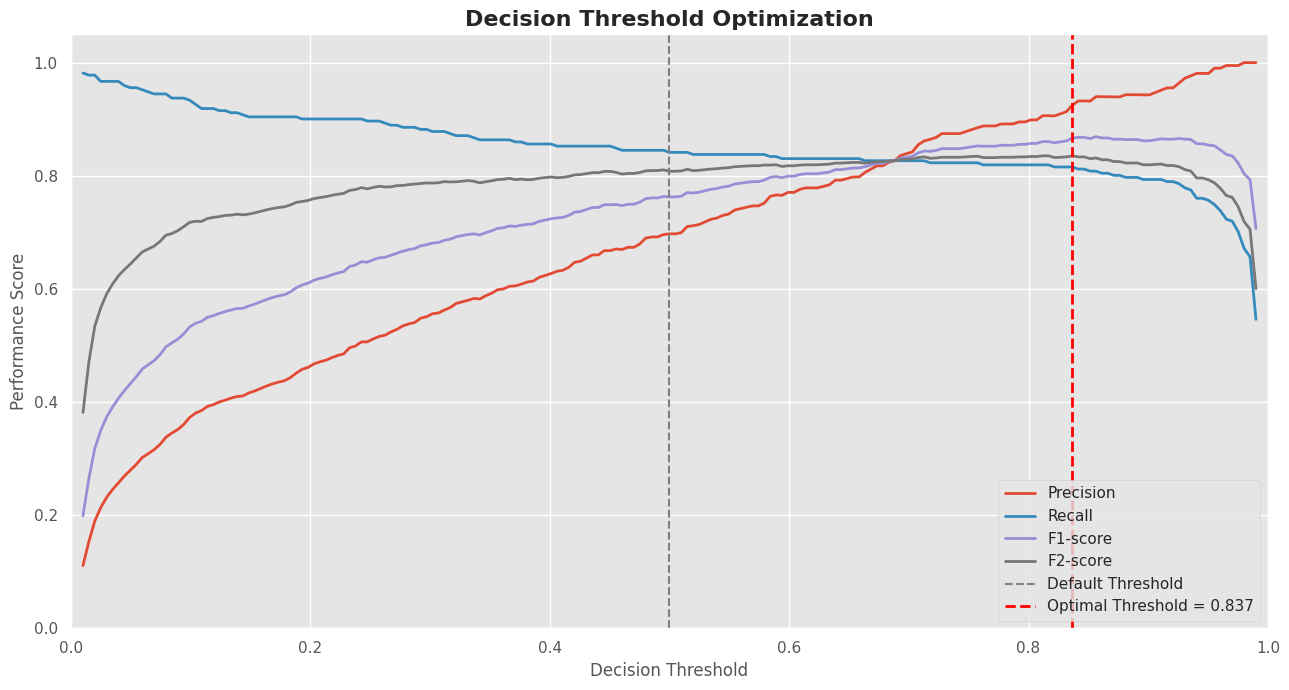

In [86]:
# Visualize threshold-dependent performance
plt.figure(figsize=(13, 7))

for metric in [
    "Precision",
    "Recall",
    "F1-score",
    "F2-score"
]:

    plt.plot(
        threshold_results_df["Threshold"],
        threshold_results_df[metric],
        linewidth=2,
        label=metric
    )

plt.axvline(
    0.5,
    color="gray",
    linestyle="--",
    label="Default Threshold"
)

plt.axvline(
    optimal_threshold,
    color="red",
    linestyle="--",
    linewidth=2,
    label=f"Optimal Threshold = {optimal_threshold:.3f}"
)

plt.title(
    "Decision Threshold Optimization",
    fontsize=16,
    fontweight="bold"
)

plt.xlabel("Decision Threshold")
plt.ylabel("Performance Score")

plt.xlim(0, 1)
plt.ylim(0, 1.05)

plt.legend()
plt.tight_layout()
plt.show()

In [87]:
# Compare default and optimized thresholds
threshold_comparison = threshold_results_df.loc[[
    (
        threshold_results_df["Threshold"] - 0.5
    ).abs().idxmin(),

    best_threshold_row.name

]].copy()

threshold_comparison.index = [
    "Default Threshold",
    "Optimized Threshold"
]

display(
    threshold_comparison[[
        "Threshold",
        "Precision",
        "Recall",
        "F1-score",
        "F2-score",
        "True Positives",
        "False Positives",
        "False Negatives",
        "True Negatives",
        "False Positive Rate"
    ]].round(4)
)

,Threshold,Precision,Recall,F1-score,F2-score,True Positives,False Positives,False Negatives,True Negatives,False Positive Rate
Default Threshold,0.5000,0.6972,0.8413,0.7625,0.8079,228,99,43,7630,0.0128
Optimized Threshold,0.8366,0.9247,0.8155,0.8667,0.8352,221,18,50,7711,0.0023


### 7.8 Optimized Model Configuration

The final model configuration combines the selected
machine learning algorithm, feature representation,
hyperparameter settings, preprocessing pipeline,
and optimized decision threshold.

All development-stage decisions are based exclusively
on training data and cross-validation results.

The selected configuration is prepared for final
training and independent held-out test evaluation.

Model probability outputs are treated as predictive
scores unless probability calibration is established.

In [88]:
# Build final model pipeline
final_pipeline = build_model_pipeline(
    best_model_name,
    clone(final_model),
    selected_features
)

# Summarize final development configuration
final_configuration_summary = pd.DataFrame({

    "Parameter": [
        "Selected Model",
        "Feature Set",
        "Number of Features",
        "Hyperparameter Configuration",
        "CV Average Precision",
        "Default Threshold",
        "Optimized Threshold",
        "Threshold Optimization Metric",
        "OOF F2-score"
    ],

    "Value": [
        best_model_name,
        best_feature_set,
        len(selected_features),
        final_configuration_type,
        round(final_cv_ap, 4),
        0.5,
        round(optimal_threshold, 4),
        "F2-score",
        round(best_threshold_row["F2-score"], 4)
    ]
})

display(final_configuration_summary)

display(final_pipeline)

,Parameter,Value
0,Selected Model,XGBoost
1,Feature Set,Physics-Informed
2,Number of Features,11
3,Hyperparameter Configuration,Optimized
4,CV Average Precision,0.8978
5,Default Threshold,0.5
6,Optimized Threshold,0.8366
7,Threshold Optimization Metric,F2-score
8,OOF F2-score,0.8352


Pipeline(steps=[('preprocessor',
                 ColumnTransformer(transformers=[('numerical',
                                                  Pipeline(steps=[('imputer',
                                                                   SimpleImputer(strategy='median'))]),
                                                  ['Air temperature',
                                                   'Process temperature',
                                                   'Rotational speed', 'Torque',
                                                   'Tool wear',
                                                   'Mechanical Power',
                                                   'Temperature Difference',
                                                   'Temperature Ratio',
                                                   'Tool Wear Load',
                                                   'Torque Speed Ratio']),
                                                 ('categorical',
                                                  Pipeline(steps=[('imp...
                               gamma=2.7145303952358844, grow_policy=None,
                               importance_type=None,
                               interaction_constraints=None,
                               learning_rate=0.02908584707482654, max_bin=None,
                               max_cat_threshold=None, max_cat_to_onehot=None,
                               max_delta_step=None, max_depth=8,
                               max_leaves=None, min_child_weight=2, missing=nan,
                               monotone_constraints=None, multi_strategy=None,
                               n_estimators=250, n_jobs=1,
                               num_parallel_tree=None, ...))])

### 7.9 Model Optimization Conclusions

The model optimization stage integrates automated
hyperparameter search, optimization history analysis,
hyperparameter importance assessment, and decision
threshold optimization.

The selected configuration is retained based on
cross-validation Average Precision.

The decision threshold is selected using out-of-fold
training predictions and the F2-score criterion.

Final predictive performance will be assessed on
the independent held-out test dataset.

No test data was used to select model hyperparameters
or optimize the decision threshold.

## 8. Model Evaluation

### 8.1 Final Model Training

The final machine learning pipeline is trained using
the complete training dataset and the selected
hyperparameter configuration.

The preprocessing pipeline is fitted exclusively
on training data.

The optimized decision threshold remains fixed
throughout final evaluation.

The independent test dataset is used exclusively
to assess predictive performance and generalization.

In [89]:
# Initialize final pipeline
final_pipeline = build_model_pipeline(
    best_model_name,
    clone(final_model),
    selected_features
)

# Record training start time
final_training_start = time.perf_counter()

# Train final model with appropriate class weighting
if best_model_name == "XGBoost":

    final_sample_weights = compute_sample_weight(
        class_weight="balanced",
        y=y_train
    )

    final_pipeline.fit(
        X_train_selected,
        y_train,
        classifier__sample_weight=final_sample_weights
    )

else:

    final_pipeline.fit(
        X_train_selected,
        y_train
    )

# Calculate final training time
final_training_time = (
    time.perf_counter() - final_training_start
)

print("=" * 60)
print("FINAL MODEL TRAINING COMPLETED")
print("=" * 60)

print(f"Model: {best_model_name}")
print(f"Feature Set: {best_feature_set}")
print(f"Training Observations: {len(y_train)}")
print(f"Number of Features: {len(selected_features)}")

print(
    f"Configuration: "
    f"{final_configuration_type}"
)

print(
    f"Training Time: "
    f"{final_training_time:.4f} seconds"
)

print(
    f"Optimized Threshold: "
    f"{optimal_threshold:.4f}"
)

print("=" * 60)

FINAL MODEL TRAINING COMPLETED
Model: XGBoost
Feature Set: Physics-Informed
Training Observations: 8000
Number of Features: 11
Configuration: Optimized
Training Time: 0.8191 seconds
Optimized Threshold: 0.8366


### 8.2 Independent Test Predictions

The trained model generates predictive scores
for the independent held-out test dataset.

Two classification strategies are evaluated:

- Default decision threshold of 0.5.
- Optimized decision threshold selected using
  out-of-fold training predictions.

The comparison investigates the impact of threshold
optimization on failure detection and false alarms.

No model parameters or thresholds are modified
using test results.

In [90]:
# Generate independent test predictions
prediction_start = time.perf_counter()

test_probabilities = final_pipeline.predict_proba(
    X_test_selected
)[:, 1]

prediction_time = (
    time.perf_counter() - prediction_start
)

# Default threshold predictions
y_pred_default = (
    test_probabilities >= 0.5
).astype(int)

# Optimized threshold predictions
y_pred_optimized = (
    test_probabilities >= optimal_threshold
).astype(int)

# Validate prediction outputs
assert len(test_probabilities) == len(y_test)
assert np.isfinite(test_probabilities).all()

# Create prediction summary
test_prediction_summary = pd.DataFrame({

    "Actual Failure": y_test.to_numpy(),

    "Failure Score": test_probabilities,

    "Default Prediction": y_pred_default,

    "Optimized Prediction": y_pred_optimized

}, index=y_test.index)

print(f"Test Observations: {len(y_test)}")

print(
    f"Total Prediction Time: "
    f"{prediction_time:.6f} seconds"
)

print(
    f"Average Prediction Time: "
    f"{prediction_time / len(y_test) * 1000:.6f} ms"
)

display(test_prediction_summary.head(10))

Test Observations: 2000
Total Prediction Time: 0.071223 seconds
Average Prediction Time: 0.035612 ms


,Actual Failure,Failure Score,Default Prediction,Optimized Prediction
2997,0,0.113562,0,0
4871,0,0.003457,0,0
3858,0,0.581027,1,0
951,0,0.003824,0,0
6463,0,0.026020,0,0
3264,0,0.007609,0,0
4508,0,0.042970,0,0
2100,0,0.005094,0,0
7885,0,0.002706,0,0
2421,0,0.013676,0,0


### 8.3 Classification Metrics

Final predictive performance is evaluated using
threshold-dependent and threshold-independent metrics.

Particular emphasis is placed on Average Precision,
Recall, Precision, and F2-score due to the highly
imbalanced nature of machine failure observations.

Specificity, false positive rates, and false negative
rates provide additional operational insights.

In [91]:
from sklearn.metrics import matthews_corrcoef

# Define comprehensive evaluation function
def calculate_test_metrics(
    y_true,
    y_pred,
    y_prob,
    threshold
):

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1]
    ).ravel()

    return {

        "Threshold": threshold,

        "Accuracy": accuracy_score(
            y_true, y_pred
        ),

        "Balanced Accuracy": balanced_accuracy_score(
            y_true, y_pred
        ),

        "Precision": precision_score(
            y_true, y_pred,
            zero_division=0
        ),

        "Recall": recall_score(
            y_true, y_pred,
            zero_division=0
        ),

        "Specificity": tn / (tn + fp),

        "F1-score": f1_score(
            y_true, y_pred,
            zero_division=0
        ),

        "F2-score": fbeta_score(
            y_true, y_pred,
            beta=2,
            zero_division=0
        ),

        "ROC-AUC": roc_auc_score(
            y_true, y_prob
        ),

        "Average Precision": average_precision_score(
            y_true, y_prob
        ),

        "Matthews Correlation Coefficient":
            matthews_corrcoef(y_true, y_pred),

        "False Positive Rate": fp / (fp + tn),

        "False Negative Rate": fn / (fn + tp),

        "True Positives": tp,

        "True Negatives": tn,

        "False Positives": fp,

        "False Negatives": fn
    }

In [92]:
# Evaluate default threshold
default_test_metrics = calculate_test_metrics(
    y_test,
    y_pred_default,
    test_probabilities,
    threshold=0.5
)

# Evaluate optimized threshold
optimized_test_metrics = calculate_test_metrics(
    y_test,
    y_pred_optimized,
    test_probabilities,
    threshold=optimal_threshold
)

# Combine evaluation results
test_metrics_df = pd.DataFrame([

    default_test_metrics,

    optimized_test_metrics

], index=[
    "Default Threshold",
    "Optimized Threshold"
])

display(test_metrics_df.T.round(4))

,Default Threshold,Optimized Threshold
Threshold,0.5000,0.8366
Accuracy,0.9830,0.9930
Balanced Accuracy,0.9344,0.9112
Precision,0.6977,0.9655
Recall,0.8824,0.8235
Specificity,0.9865,0.9990
F1-score,0.7792,0.8889
F2-score,0.8380,0.8485
ROC-AUC,0.9809,0.9809
Average Precision,0.9089,0.9089


In [93]:
# Generate final classification report
classification_report_df = pd.DataFrame(

    classification_report(
        y_test,
        y_pred_optimized,
        labels=[0, 1],
        target_names=[
            "No Failure",
            "Failure"
        ],
        output_dict=True,
        zero_division=0
    )

).T

print("FINAL CLASSIFICATION REPORT")

display(classification_report_df.round(4))

FINAL CLASSIFICATION REPORT


,precision,recall,f1-score,support
No Failure,0.9938,0.9990,0.9964,1932.000
Failure,0.9655,0.8235,0.8889,68.000
accuracy,0.9930,0.9930,0.9930,0.993
macro avg,0.9797,0.9112,0.9426,2000.000
weighted avg,0.9929,0.9930,0.9927,2000.000


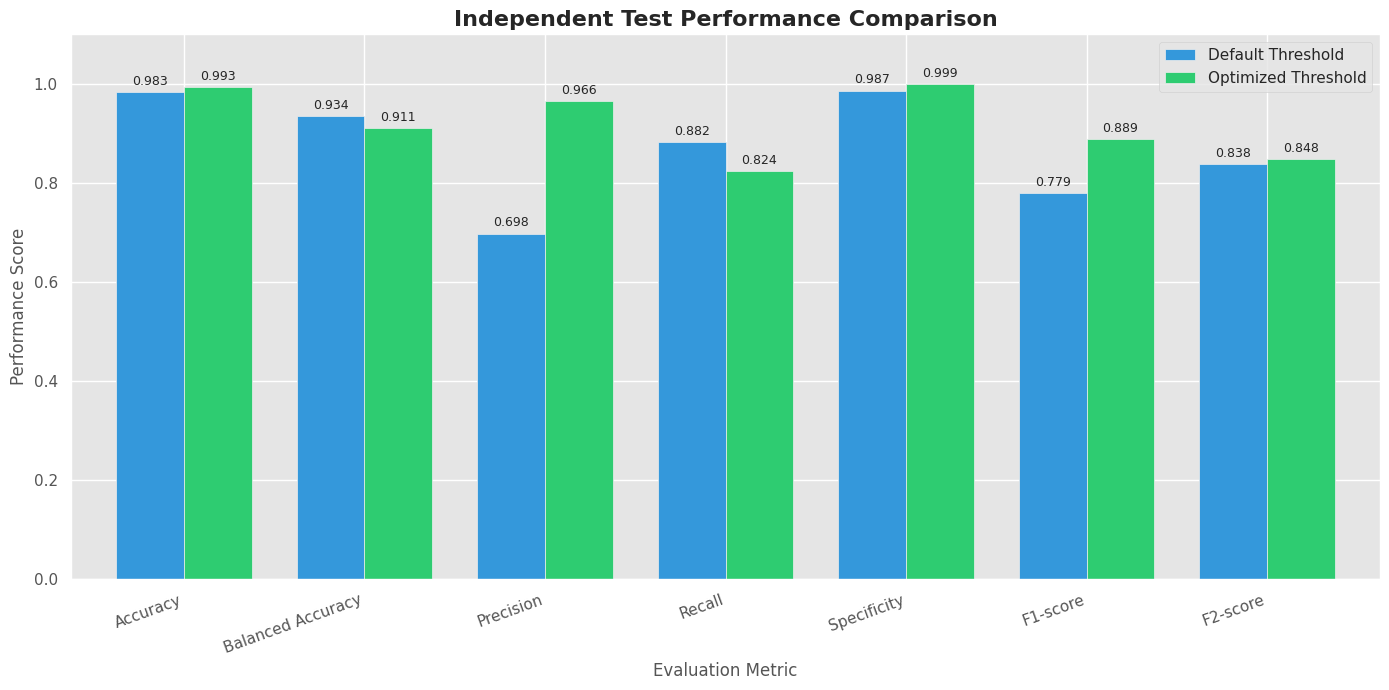

In [94]:
# Select threshold-dependent performance metrics
visualization_metrics = [
    "Accuracy",
    "Balanced Accuracy",
    "Precision",
    "Recall",
    "Specificity",
    "F1-score",
    "F2-score"
]

performance_plot = test_metrics_df[
    visualization_metrics
].T

# Visualize classification performance
ax = performance_plot.plot(
    kind="bar",
    figsize=(14, 7),
    color=["#3498db", "#2ecc71"],
    width=0.75
)

for container in ax.containers:

    ax.bar_label(
        container,
        fmt="%.3f",
        padding=3,
        fontsize=9
    )

plt.title(
    "Independent Test Performance Comparison",
    fontsize=16,
    fontweight="bold"
)

plt.ylabel("Performance Score")
plt.xlabel("Evaluation Metric")

plt.xticks(rotation=20, ha="right")
plt.ylim(0, 1.1)

plt.legend()
plt.tight_layout()
plt.show()

### 8.4 Confusion Matrix Analysis

Confusion matrices are used to investigate the
classification behavior of both decision strategies.

The analysis focuses on:

- Correctly detected machine failures.
- Correctly classified normal observations.
- Missed machine failures.
- False failure alarms.

False negatives are particularly important in
industrial maintenance applications due to their
potential operational consequences.

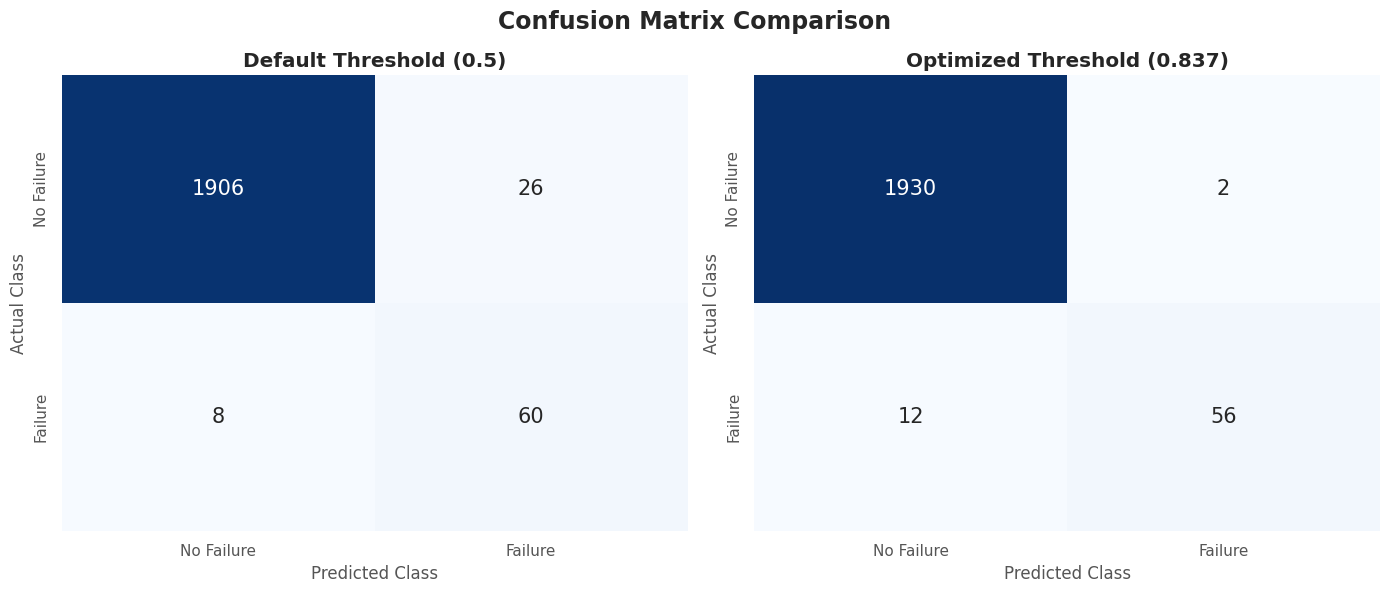

In [95]:
# Calculate confusion matrices
cm_default = confusion_matrix(
    y_test,
    y_pred_default,
    labels=[0, 1]
)

cm_optimized = confusion_matrix(
    y_test,
    y_pred_optimized,
    labels=[0, 1]
)

# Create comparison visualization
fig, axes = plt.subplots(
    1, 2,
    figsize=(14, 6)
)

matrices = [
    cm_default,
    cm_optimized
]

titles = [

    "Default Threshold (0.5)",

    f"Optimized Threshold ({optimal_threshold:.3f})"
]

for ax, matrix, title in zip(
    axes, matrices, titles
):

    sns.heatmap(
        matrix,
        annot=True,
        fmt="d",
        cmap="Blues",
        cbar=False,
        vmin=0,
        vmax=max(
            cm_default.max(),
            cm_optimized.max()
        ),
        xticklabels=[
            "No Failure",
            "Failure"
        ],
        yticklabels=[
            "No Failure",
            "Failure"
        ],
        annot_kws={"size": 15},
        ax=ax
    )

    ax.set_title(title, fontweight="bold")
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("Actual Class")

plt.suptitle(
    "Confusion Matrix Comparison",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [96]:
# Analyze operational classification changes
operational_comparison = pd.DataFrame({

    "Metric": [
        "Detected Failures",
        "Missed Failures",
        "False Alarms",
        "Correct Normal Predictions"
    ],

    "Default Threshold": [
        cm_default[1, 1],
        cm_default[1, 0],
        cm_default[0, 1],
        cm_default[0, 0]
    ],

    "Optimized Threshold": [
        cm_optimized[1, 1],
        cm_optimized[1, 0],
        cm_optimized[0, 1],
        cm_optimized[0, 0]
    ]
})

operational_comparison["Change"] = (
    operational_comparison["Optimized Threshold"]
    -
    operational_comparison["Default Threshold"]
)

display(operational_comparison)

print(
    "Change in missed failures:",
    cm_optimized[1, 0] - cm_default[1, 0]
)

print(
    "Change in false alarms:",
    cm_optimized[0, 1] - cm_default[0, 1]
)

,Metric,Default Threshold,Optimized Threshold,Change
0,Detected Failures,60,56,-4
1,Missed Failures,8,12,4
2,False Alarms,26,2,-24
3,Correct Normal Predictions,1906,1930,24


Change in missed failures: 4
Change in false alarms: -24


### 8.5 Receiver Operating Characteristic Analysis

The Receiver Operating Characteristic curve evaluates
the relationship between the True Positive Rate and
False Positive Rate across classification thresholds.

ROC-AUC summarizes the model's ability to distinguish
between normal operation and machine failure.

The default and optimized operating points are
highlighted to illustrate threshold-dependent
classification behavior.

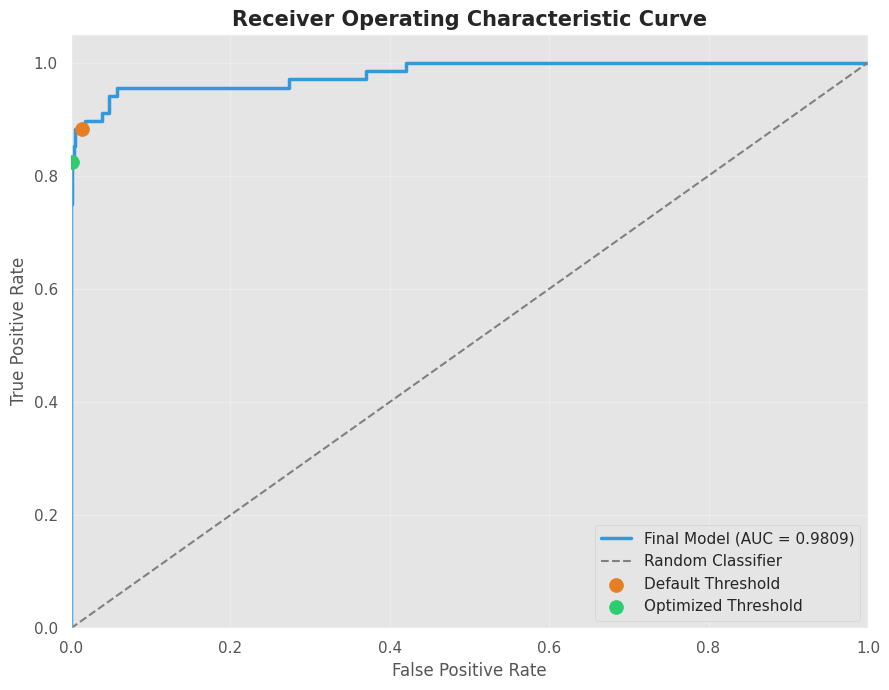

In [97]:
# Calculate ROC curve
fpr, tpr, roc_thresholds = roc_curve(
    y_test,
    test_probabilities
)

test_roc_auc = roc_auc_score(
    y_test,
    test_probabilities
)

plt.figure(figsize=(9, 7))

plt.plot(
    fpr,
    tpr,
    color="#3498db",
    linewidth=2.5,
    label=f"Final Model (AUC = {test_roc_auc:.4f})"
)

# Random classifier reference
plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    color="gray",
    label="Random Classifier"
)

# Default operating point
plt.scatter(
    default_test_metrics["False Positive Rate"],
    default_test_metrics["Recall"],
    color="#e67e22",
    s=100,
    label="Default Threshold",
    zorder=5
)

# Optimized operating point
plt.scatter(
    optimized_test_metrics["False Positive Rate"],
    optimized_test_metrics["Recall"],
    color="#2ecc71",
    s=100,
    label="Optimized Threshold",
    zorder=5
)

plt.title(
    "Receiver Operating Characteristic Curve",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")

plt.xlim(0, 1)
plt.ylim(0, 1.05)

plt.legend(loc="lower right")
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### 8.6 Precision-Recall Analysis

The Precision-Recall curve evaluates the trade-off
between failure detection sensitivity and the
reliability of positive predictions.

Average Precision summarizes performance across
different classification thresholds.

Given the class imbalance in the dataset,
Precision-Recall analysis provides important
insights into minority-class detection performance.

The positive-class prevalence is used as the
random-ranking reference baseline.

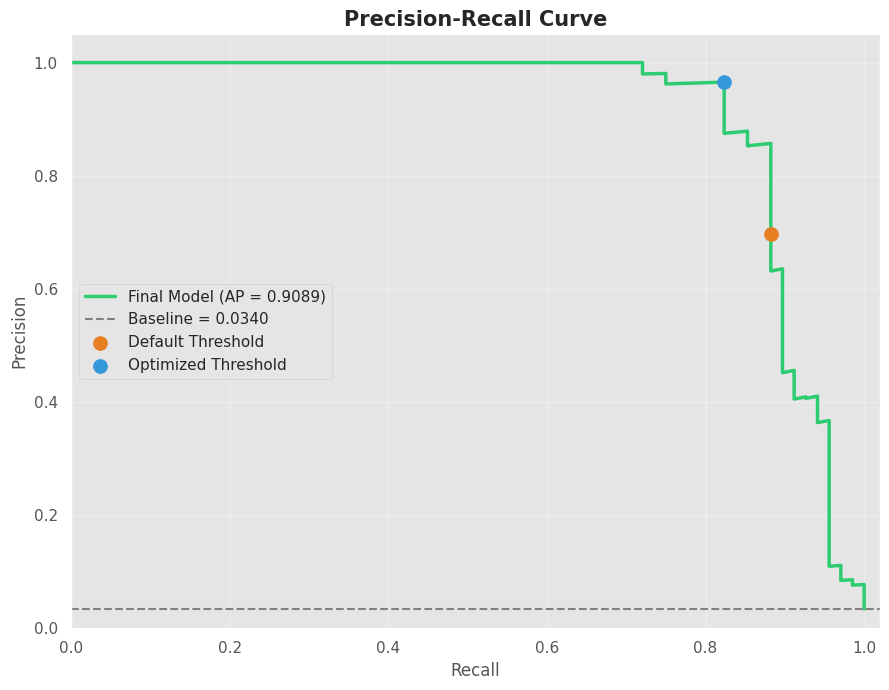

In [98]:
# Calculate Precision-Recall curve
pr_precision, pr_recall, pr_thresholds = (
    precision_recall_curve(
        y_test,
        test_probabilities
    )
)

test_average_precision = average_precision_score(
    y_test,
    test_probabilities
)

# Calculate positive-class prevalence
test_prevalence = y_test.mean()

plt.figure(figsize=(9, 7))

plt.plot(
    pr_recall,
    pr_precision,
    color="#2ecc71",
    linewidth=2.5,
    label=f"Final Model (AP = {test_average_precision:.4f})"
)

# Random-ranking reference baseline
plt.axhline(
    test_prevalence,
    linestyle="--",
    color="gray",
    label=f"Baseline = {test_prevalence:.4f}"
)

# Highlight default threshold
plt.scatter(
    default_test_metrics["Recall"],
    default_test_metrics["Precision"],
    color="#e67e22",
    s=100,
    label="Default Threshold",
    zorder=5
)

# Highlight optimized threshold
plt.scatter(
    optimized_test_metrics["Recall"],
    optimized_test_metrics["Precision"],
    color="#3498db",
    s=100,
    label="Optimized Threshold",
    zorder=5
)

plt.title(
    "Precision-Recall Curve",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Recall")
plt.ylabel("Precision")

plt.xlim(0, 1.02)
plt.ylim(0, 1.05)

plt.legend()
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

### 8.7 Bootstrap Confidence Intervals

Stratified bootstrap resampling is used to estimate
uncertainty in final test performance metrics.

A total of 1,000 bootstrap samples are generated
by independently resampling observations within
each target class.

Percentile-based 95% confidence intervals are
calculated for key evaluation metrics.

The resulting intervals quantify test-sample
variability conditional on the trained model and
fixed decision threshold.

They do not capture uncertainty from model training,
hyperparameter selection, or distribution shifts.

In [99]:
# Configure bootstrap analysis
N_BOOTSTRAPS = 1000
CONFIDENCE_LEVEL = 0.95

rng = np.random.default_rng(
    RANDOM_STATE
)

# Convert target into NumPy array
y_test_array = y_test.to_numpy()

# Identify class-specific indices
negative_indices = np.flatnonzero(
    y_test_array == 0
)

positive_indices = np.flatnonzero(
    y_test_array == 1
)

bootstrap_results = []

# Perform stratified bootstrap resampling
for iteration in range(N_BOOTSTRAPS):

    sampled_negative = rng.choice(
        negative_indices,
        size=len(negative_indices),
        replace=True
    )

    sampled_positive = rng.choice(
        positive_indices,
        size=len(positive_indices),
        replace=True
    )

    sampled_indices = np.concatenate([
        sampled_negative,
        sampled_positive
    ])

    y_bootstrap = y_test_array[
        sampled_indices
    ]

    prob_bootstrap = test_probabilities[
        sampled_indices
    ]

    pred_bootstrap = (
        prob_bootstrap >= optimal_threshold
    ).astype(int)

    bootstrap_results.append({

        "ROC-AUC": roc_auc_score(
            y_bootstrap,
            prob_bootstrap
        ),

        "Average Precision": average_precision_score(
            y_bootstrap,
            prob_bootstrap
        ),

        "Recall": recall_score(
            y_bootstrap,
            pred_bootstrap,
            zero_division=0
        ),

        "Precision": precision_score(
            y_bootstrap,
            pred_bootstrap,
            zero_division=0
        ),

        "F1-score": f1_score(
            y_bootstrap,
            pred_bootstrap,
            zero_division=0
        ),

        "F2-score": fbeta_score(
            y_bootstrap,
            pred_bootstrap,
            beta=2,
            zero_division=0
        )
    })

bootstrap_df = pd.DataFrame(
    bootstrap_results
)

print(
    f"Bootstrap Samples Completed: "
    f"{len(bootstrap_df)}"
)

display(bootstrap_df.head())

Bootstrap Samples Completed: 1000


,ROC-AUC,Average Precision,Recall,Precision,F1-score,F2-score
0,0.990455,0.940409,0.882353,0.983607,0.930233,0.900901
1,0.982942,0.900391,0.779412,0.981481,0.868852,0.812883
2,0.996978,0.959686,0.852941,0.966667,0.906250,0.873494
3,0.987874,0.907786,0.794118,0.981818,0.878049,0.825688
4,0.987852,0.950934,0.882353,1.000000,0.937500,0.903614


In [100]:
# Calculate percentile confidence intervals
alpha = 1 - CONFIDENCE_LEVEL

confidence_interval_results = []

for metric in bootstrap_df.columns:

    lower_bound = bootstrap_df[
        metric
    ].quantile(alpha / 2)

    upper_bound = bootstrap_df[
        metric
    ].quantile(1 - alpha / 2)

    confidence_interval_results.append({

        "Metric": metric,

        "Test Estimate":
            optimized_test_metrics[metric],

        "Bootstrap Mean":
            bootstrap_df[metric].mean(),

        "Bootstrap Std":
            bootstrap_df[metric].std(),

        "95% CI Lower":
            lower_bound,

        "95% CI Upper":
            upper_bound
    })

confidence_intervals_df = pd.DataFrame(
    confidence_interval_results
)

display(confidence_intervals_df.round(4))

,Metric,Test Estimate,Bootstrap Mean,Bootstrap Std,95% CI Lower,95% CI Upper
0,ROC-AUC,0.9809,0.9812,0.0088,0.9614,0.9963
1,Average Precision,0.9089,0.9103,0.0282,0.8511,0.9600
2,Recall,0.8235,0.8231,0.0453,0.7206,0.9118
3,Precision,0.9655,0.9657,0.0232,0.9138,1.0000
4,F1-score,0.8889,0.8880,0.0296,0.8226,0.9394
5,F2-score,0.8485,0.8477,0.0392,0.7609,0.9199


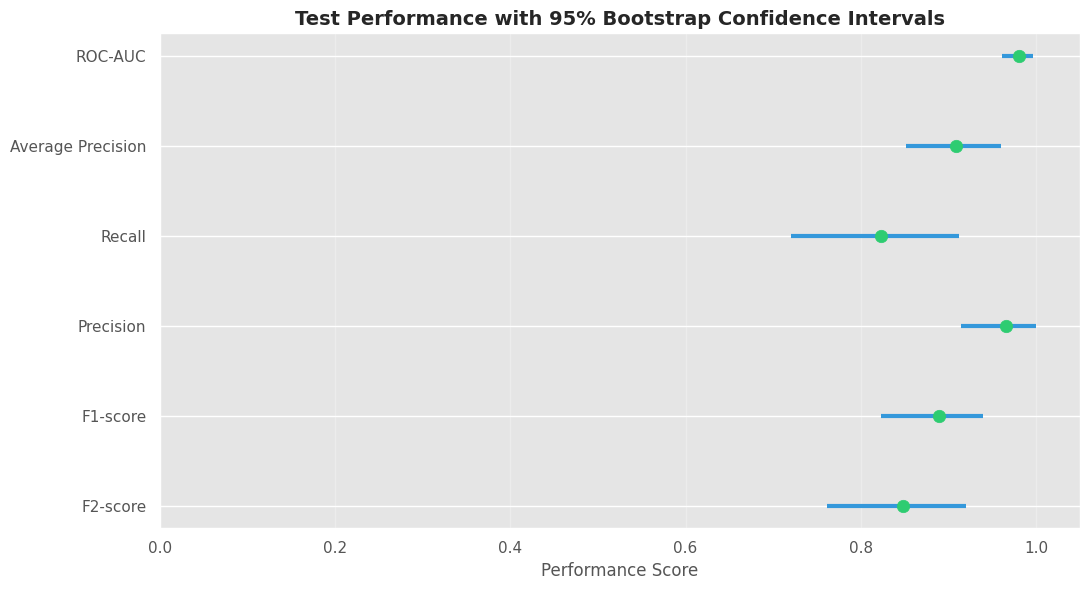

In [101]:
# Visualize bootstrap confidence intervals
ci_plot = confidence_intervals_df.copy()

fig, ax = plt.subplots(
    figsize=(11, 6)
)

for position, (_, result) in enumerate(
    ci_plot.iterrows()
):

    ax.hlines(
        y=position,
        xmin=result["95% CI Lower"],
        xmax=result["95% CI Upper"],
        color="#3498db",
        linewidth=3
    )

    ax.scatter(
        result["Test Estimate"],
        position,
        color="#2ecc71",
        s=80,
        zorder=5
    )

ax.set_yticks(
    range(len(ci_plot))
)

ax.set_yticklabels(
    ci_plot["Metric"]
)

ax.set_title(
    "Test Performance with 95% Bootstrap Confidence Intervals",
    fontsize=14,
    fontweight="bold"
)

ax.set_xlabel("Performance Score")
ax.set_xlim(0, 1.05)

ax.grid(
    axis="x",
    alpha=0.3
)

ax.invert_yaxis()

plt.tight_layout()
plt.show()

### 8.8 Error Analysis

Prediction errors are investigated to identify
operational characteristics associated with
misclassified observations.

Test observations are categorized into:

- True Positives.
- True Negatives.
- False Positives.
- False Negatives.

Error analysis considers sensor measurements,
engineered features, product types, and failure
mechanisms.

The analysis is descriptive and is not used to
modify the evaluated model or decision threshold.

In [102]:
# Create comprehensive test analysis dataset
error_analysis_df = test_df.copy()

error_analysis_df["Failure Score"] = (
    test_probabilities
)

error_analysis_df["Predicted Failure"] = (
    y_pred_optimized
)

# Define prediction outcomes
conditions = [

    (y_test_array == 0) &
    (y_pred_optimized == 0),

    (y_test_array == 0) &
    (y_pred_optimized == 1),

    (y_test_array == 1) &
    (y_pred_optimized == 0),

    (y_test_array == 1) &
    (y_pred_optimized == 1)
]

outcomes = [
    "True Negative",
    "False Positive",
    "False Negative",
    "True Positive"
]

error_analysis_df["Prediction Outcome"] = (
    np.select(
        conditions,
        outcomes,
        default="Unknown"
    )
)

# Generate outcome distribution
outcome_summary = error_analysis_df[
    "Prediction Outcome"
].value_counts().reindex(
    outcomes,
    fill_value=0
).to_frame("Count")

outcome_summary["Percentage (%)"] = (
    outcome_summary["Count"]
    / len(error_analysis_df)
    * 100
)

display(outcome_summary.round(4))

,Count,Percentage (%)
Prediction Outcome,,
True Negative,1930,96.5
False Positive,2,0.1
False Negative,12,0.6
True Positive,56,2.8


In [103]:
# Compare sensor measurements across outcomes
error_sensor_statistics = (
    error_analysis_df
    .groupby("Prediction Outcome")[sensor_columns]
    .agg(["mean", "median", "std"])
)

display(error_sensor_statistics.round(3))

Air temperature                Process temperature         \
                              mean  median    std                mean median   
Prediction Outcome                                                             
False Negative             300.017  300.45  1.740             309.825  309.6   
False Positive             302.200  302.20  0.000             310.800  310.8   
True Negative              299.975  300.00  2.005             309.998  310.1   
True Positive              300.898  301.85  2.213             310.204  310.4   

                          Rotational speed                   Torque         \
                      std             mean  median      std    mean median   
Prediction Outcome                                                           
False Negative      1.196         1560.833  1480.5  211.332  36.567  37.75   
False Positive      0.000         1348.000  1348.0   11.314  48.050  48.05   
True Negative       1.506         1538.652  1507.0  161.041  39.552  39.90   
True Positive       1.397         1462.161  1349.5  392.221  53.068  55.85   

                           Tool wear                 
                       std      mean median     std  
Prediction Outcome                                   
False Negative       9.958   199.083  208.5  46.481  
False Positive       0.354    45.000   45.0  12.728  
True Negative        9.295   107.520  111.0  63.298  
True Positive       15.185   143.518  145.5  62.451

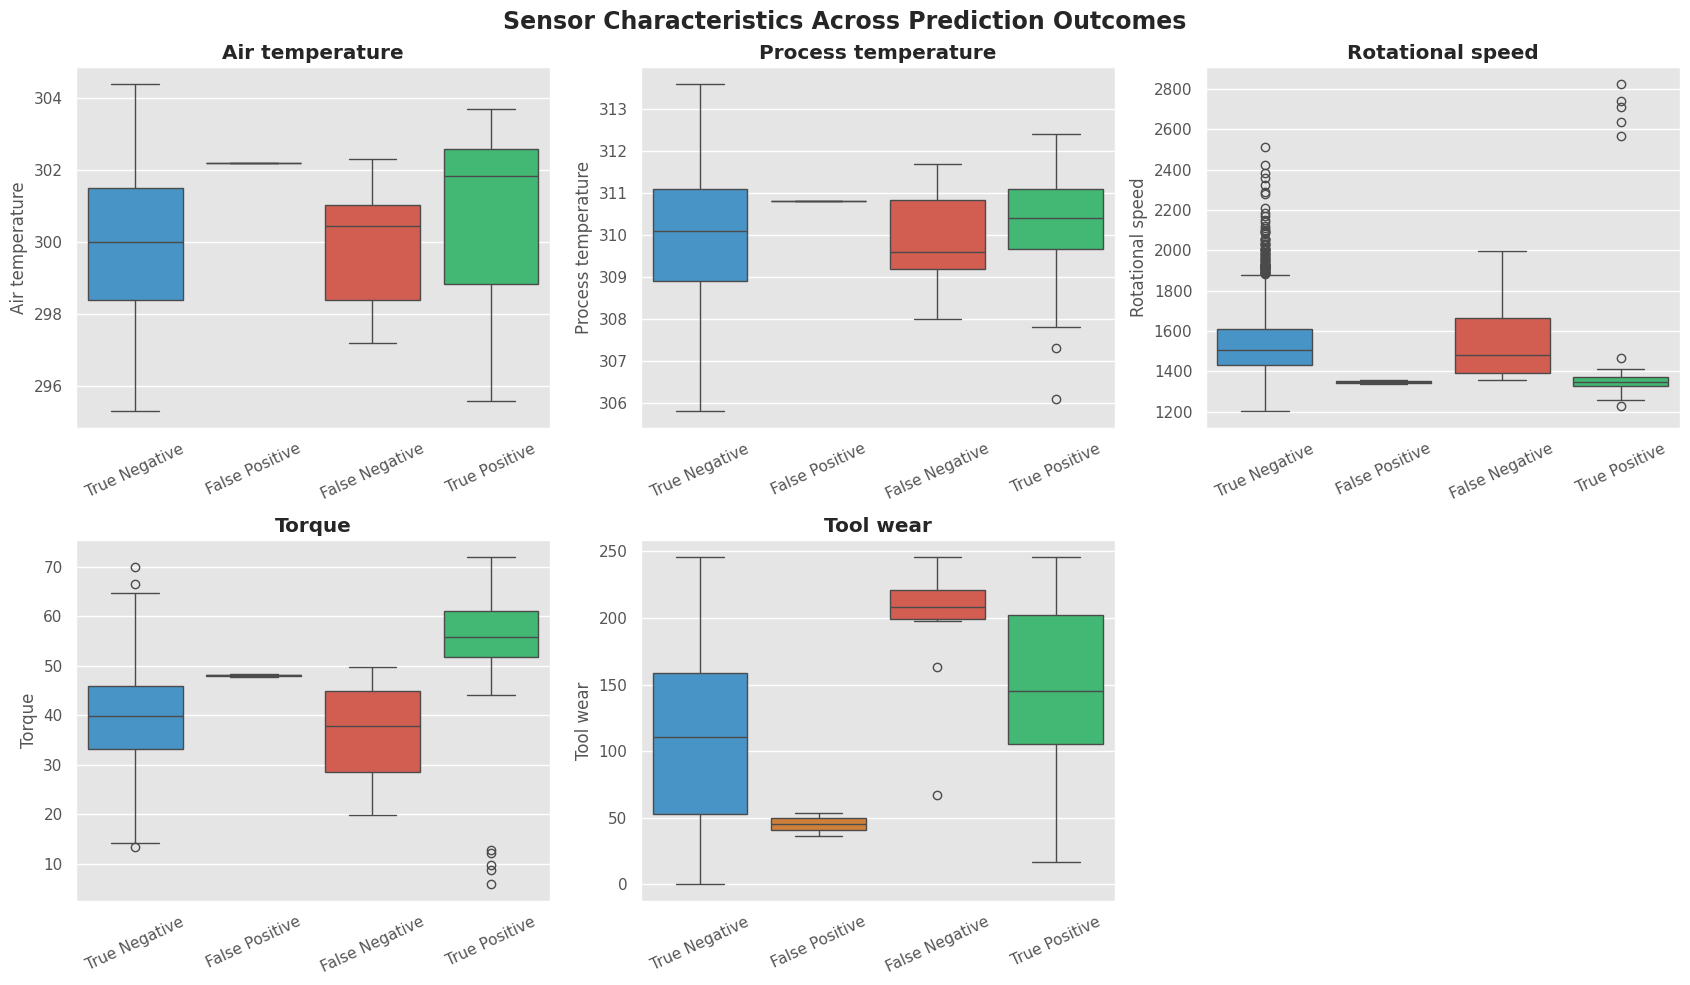

In [104]:
# Visualize sensor behavior across prediction outcomes
fig, axes = plt.subplots(
    2, 3,
    figsize=(17, 10)
)

axes = axes.flatten()

outcome_palette = {

    "True Negative": "#3498db",

    "False Positive": "#e67e22",

    "False Negative": "#e74c3c",

    "True Positive": "#2ecc71"
}

for ax, feature in zip(
    axes,
    sensor_columns
):

    sns.boxplot(
        data=error_analysis_df,
        x="Prediction Outcome",
        y=feature,
        hue="Prediction Outcome",
        order=outcomes,
        hue_order=outcomes,
        palette=outcome_palette,
        legend=False,
        ax=ax
    )

    ax.set_title(feature, fontweight="bold")
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=25)

# Remove unused subplot
for ax in axes[len(sensor_columns):]:

    ax.remove()

plt.suptitle(
    "Sensor Characteristics Across Prediction Outcomes",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

In [105]:
# Analyze failure detection by product type
product_error_analysis = pd.crosstab(

    error_analysis_df["Type"],

    error_analysis_df["Prediction Outcome"]

).reindex(
    index=["L", "M", "H"],
    columns=outcomes,
    fill_value=0
)

# Calculate product-specific recall
product_error_analysis["Recall"] = (

    product_error_analysis["True Positive"]

    /

    (
        product_error_analysis["True Positive"]
        +
        product_error_analysis["False Negative"]
    ).replace(0, np.nan)
)

# Calculate product-specific false positive rate
product_error_analysis["False Positive Rate"] = (

    product_error_analysis["False Positive"]

    /

    (
        product_error_analysis["False Positive"]
        +
        product_error_analysis["True Negative"]
    ).replace(0, np.nan)
)

display(product_error_analysis.round(4))

Prediction Outcome,True Negative,False Positive,False Negative,True Positive,Recall,False Positive Rate
Type,,,,,,
L,1131,1,6,32,0.8421,0.0009
M,590,1,5,20,0.8000,0.0017
H,209,0,1,4,0.8000,0.0000


In [106]:
# Analyze detection performance by failure mechanism
failure_detection_results = []

for failure_type in failure_types:

    # Restrict analysis to confirmed target failures
    failure_subset = error_analysis_df[

        (error_analysis_df[failure_type] == 1) &

        (error_analysis_df["Machine failure"] == 1)
    ]

    total_failures = len(failure_subset)

    detected_failures = (
        failure_subset["Predicted Failure"] == 1
    ).sum()

    missed_failures = (
        total_failures - detected_failures
    )

    detection_rate = (

        detected_failures / total_failures

        if total_failures > 0

        else np.nan
    )

    failure_detection_results.append({

        "Failure Type": failure_names[failure_type],

        "Total Failures": total_failures,

        "Detected Failures": detected_failures,

        "Missed Failures": missed_failures,

        "Detection Rate": detection_rate
    })

failure_detection_df = pd.DataFrame(
    failure_detection_results
)

display(failure_detection_df.round(4))

,Failure Type,Total Failures,Detected Failures,Missed Failures,Detection Rate
0,Tool Wear Failure,10,1,9,0.1000
1,Heat Dissipation Failure,29,28,1,0.9655
2,Power Failure,13,13,0,1.0000
3,Overstrain Failure,16,16,0,1.0000
4,Random Failure,0,0,0,NaN


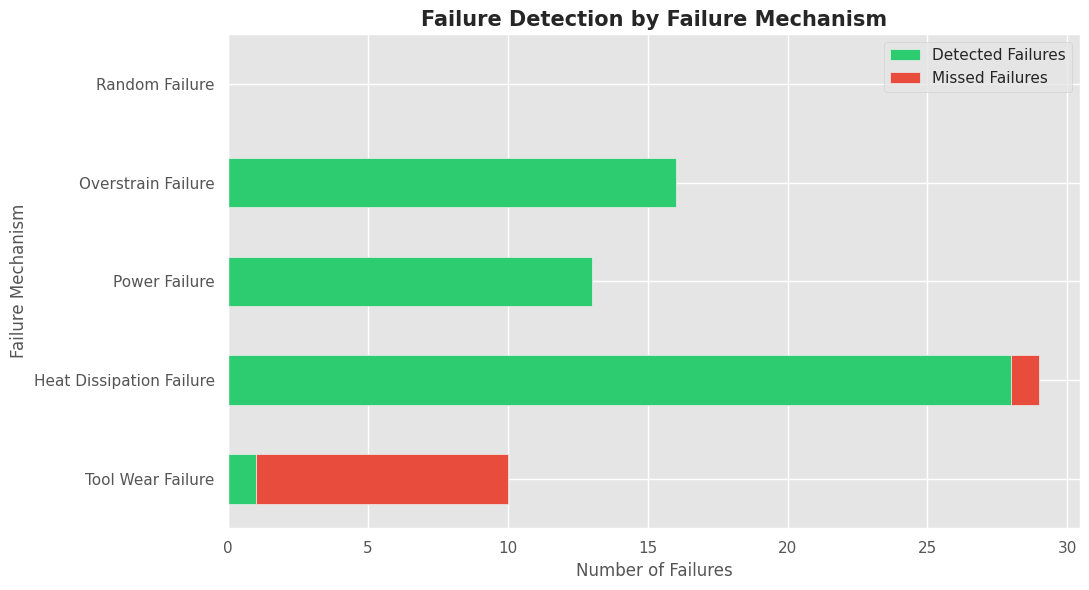

In [107]:
# Visualize failure detection by mechanism
failure_detection_plot = failure_detection_df.set_index(
    "Failure Type"
)[[
    "Detected Failures",
    "Missed Failures"
]]

ax = failure_detection_plot.plot(
    kind="barh",
    stacked=True,
    figsize=(11, 6),
    color=["#2ecc71", "#e74c3c"]
)

plt.title(
    "Failure Detection by Failure Mechanism",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Number of Failures")
plt.ylabel("Failure Mechanism")

plt.legend()
plt.tight_layout()
plt.show()

In [108]:
# Generate final evaluation summary
print("=" * 65)
print("CELLSENSE - FINAL MODEL EVALUATION")
print("=" * 65)

print(f"Selected Model: {best_model_name}")
print(f"Feature Set: {best_feature_set}")
print(f"Configuration: {final_configuration_type}")

print(
    f"Decision Threshold: "
    f"{optimal_threshold:.4f}"
)

print(f"Test Observations: {len(y_test)}")

print("-" * 65)

for metric in [

    "Accuracy",
    "Balanced Accuracy",
    "Precision",
    "Recall",
    "Specificity",
    "F1-score",
    "F2-score",
    "ROC-AUC",
    "Average Precision",
    "Matthews Correlation Coefficient"

]:

    print(
        f"{metric}: "
        f"{optimized_test_metrics[metric]:.4f}"
    )

print("-" * 65)

print(f"Detected Failures: {cm_optimized[1, 1]}")
print(f"Missed Failures: {cm_optimized[1, 0]}")
print(f"False Alarms: {cm_optimized[0, 1]}")
print(f"Correct Normal Predictions: {cm_optimized[0, 0]}")

print("-" * 65)

print(
    f"Final Training Time: "
    f"{final_training_time:.4f} seconds"
)

print("=" * 65)

CELLSENSE - FINAL MODEL EVALUATION
Selected Model: XGBoost
Feature Set: Physics-Informed
Configuration: Optimized
Decision Threshold: 0.8366
Test Observations: 2000
-----------------------------------------------------------------
Accuracy: 0.9930
Balanced Accuracy: 0.9112
Precision: 0.9655
Recall: 0.8235
Specificity: 0.9990
F1-score: 0.8889
F2-score: 0.8485
ROC-AUC: 0.9809
Average Precision: 0.9089
Matthews Correlation Coefficient: 0.8883
-----------------------------------------------------------------
Detected Failures: 56
Missed Failures: 12
False Alarms: 2
Correct Normal Predictions: 1930
-----------------------------------------------------------------
Final Training Time: 0.8191 seconds


### 8.9 Model Evaluation Conclusions

The final machine learning configuration was evaluated
using an independent held-out test dataset.

The evaluation framework included:

- Comprehensive classification metrics.
- Default and optimized threshold comparison.
- Confusion matrix analysis.
- ROC and Precision-Recall analysis.
- Bootstrap confidence interval estimation.
- Operational error analysis.
- Failure mechanism detection analysis.

The results provide a quantitative assessment of
predictive performance and failure detection behavior.

The synthetic nature of the dataset limits direct
generalization to real industrial environments.

Further validation using real-world operational data
would be required before industrial deployment.

The next stage investigates model interpretability
through Explainable Artificial Intelligence techniques.

## 9. Explainable Artificial Intelligence

### 9.1 Explainability Framework

SHapley Additive exPlanations (SHAP) are used to
interpret the predictions of the final classification
model.

SHAP provides an additive feature attribution
framework inspired by cooperative game theory.

The explainability framework includes:

- Global feature importance.
- Feature-level contribution analysis.
- Feature dependence visualization.
- Individual prediction explanations.
- Misclassification interpretation.
- Engineered feature contribution analysis.

SHAP explanations describe model behavior and should
not be interpreted as evidence of causal relationships.

In [109]:
# Import explainability libraries
import shap

print(f"SHAP Version: {shap.__version__}")

print(f"Selected Model: {best_model_name}")
print(f"Feature Set: {best_feature_set}")

print("Explainability framework initialized.")

SHAP Version: 0.54.1
Selected Model: XGBoost
Feature Set: Physics-Informed
Explainability framework initialized.


### 9.2 SHAP Data Preparation

The fitted preprocessing pipeline is used to
transform the training and test feature matrices.

Transformed feature names are preserved to ensure
consistent interpretation of numerical and
categorical variables.

A representative training-data sample serves as
the SHAP background dataset.

A reproducible test-data sample is used for
computationally efficient global explanations.

In [110]:
# Extract fitted pipeline components
fitted_preprocessor = final_pipeline.named_steps[
    "preprocessor"
]

fitted_classifier = final_pipeline.named_steps[
    "classifier"
]

# Transform feature matrices
X_train_transformed = fitted_preprocessor.transform(
    X_train_selected
)

X_test_transformed = fitted_preprocessor.transform(
    X_test_selected
)

# Extract transformed feature names
transformed_feature_names = [
    name.split("__", 1)[-1]

    for name in
    fitted_preprocessor.get_feature_names_out()
]

# Convert transformed matrices into DataFrames
X_train_shap = pd.DataFrame(
    X_train_transformed,
    columns=transformed_feature_names,
    index=X_train_selected.index
)

X_test_shap = pd.DataFrame(
    X_test_transformed,
    columns=transformed_feature_names,
    index=X_test_selected.index
)

print("Transformed Training Shape:",
      X_train_shap.shape)

print("Transformed Test Shape:",
      X_test_shap.shape)

print("\nTransformed Features:")

for feature in transformed_feature_names:

    print(f"- {feature}")

display(X_test_shap.head())

Transformed Training Shape: (8000, 13)
Transformed Test Shape: (2000, 13)

Transformed Features:
- Air temperature
- Process temperature
- Rotational speed
- Torque
- Tool wear
- Mechanical Power
- Temperature Difference
- Temperature Ratio
- Tool Wear Load
- Torque Speed Ratio
- Type_H
- Type_L
- Type_M


,Air temperature,Process temperature,Rotational speed,Torque,Tool wear,Mechanical Power,Temperature Difference,Temperature Ratio,Tool Wear Load,Torque Speed Ratio,Type_H,Type_L,Type_M
2997,300.5,309.8,1345.0,62.7,153.0,8831.174029,9.3,1.030948,9593.1,0.046617,0.0,1.0,0.0
4871,303.7,312.4,1513.0,40.1,135.0,6353.483679,8.7,1.028647,5413.5,0.026504,0.0,1.0,0.0
3858,302.5,311.4,1559.0,37.6,209.0,6138.504494,8.9,1.029421,7858.4,0.024118,0.0,1.0,0.0
951,295.6,306.3,1509.0,35.8,60.0,5657.191555,10.7,1.036198,2148.0,0.023724,1.0,0.0,0.0
6463,300.5,310.0,1358.0,60.4,102.0,8589.449418,9.5,1.031614,6160.8,0.044477,1.0,0.0,0.0


In [111]:
# Configure explainability sample sizes
SHAP_BACKGROUND_SIZE = 100
SHAP_EXPLANATION_SIZE = 300

# Sample background observations from training data
shap_background = X_train_shap.sample(

    n=min(
        SHAP_BACKGROUND_SIZE,
        len(X_train_shap)
    ),

    random_state=RANDOM_STATE
)

# Sample test observations for global explanations
shap_sample = X_test_shap.sample(

    n=min(
        SHAP_EXPLANATION_SIZE,
        len(X_test_shap)
    ),

    random_state=RANDOM_STATE
)

print(
    f"Background Observations: "
    f"{len(shap_background)}"
)

print(
    f"Explanation Observations: "
    f"{len(shap_sample)}"
)

Background Observations: 100
Explanation Observations: 300


### 9.3 SHAP Value Computation

A model-agnostic SHAP Permutation Explainer is used
to estimate feature contributions to machine
failure prediction scores.

The explainer operates on the positive-class output
of the fitted classifier.

Feature contributions are calculated relative to
the training-derived background distribution.

Permutation-based SHAP values are approximate
estimates of Shapley feature contributions.

In [112]:
# Define positive-class prediction function
def predict_failure_score(data):

    if not isinstance(data, pd.DataFrame):

        data = pd.DataFrame(
            data,
            columns=transformed_feature_names
        )

    if hasattr(fitted_classifier, "feature_names_in_"):

        data = data.copy()

        data.columns = fitted_classifier.feature_names_in_

    else:

        data = data.to_numpy()

    return fitted_classifier.predict_proba(
        data
    )[:, 1]


# Verify consistency with the complete pipeline
np.testing.assert_allclose(
    predict_failure_score(X_test_shap),
    test_probabilities,
    rtol=1e-6,
    atol=1e-8
)

# Initialize SHAP explainer
shap_explainer = shap.Explainer(

    predict_failure_score,

    shap_background,

    algorithm="permutation",

    feature_names=transformed_feature_names,

    seed=RANDOM_STATE
)

print("SHAP Explainer initialized successfully.")

SHAP Explainer initialized successfully.


In [113]:
# Record SHAP computation time
shap_start = time.perf_counter()

SHAP_MAX_EVALS = (
    10 * (2 * len(transformed_feature_names) + 1)
)

# Calculate SHAP explanations
shap_values = shap_explainer(

    shap_sample,

    max_evals=SHAP_MAX_EVALS
)

shap_computation_time = (
    time.perf_counter() - shap_start
)

print("=" * 55)
print("SHAP COMPUTATION COMPLETED")
print("=" * 55)

print(f"SHAP Values Shape: {shap_values.values.shape}")

print(
    f"Computation Time: "
    f"{shap_computation_time:.2f} seconds"
)

PermutationExplainer explainer: 301it [01:35,  2.85it/s]

SHAP COMPUTATION COMPLETED
SHAP Values Shape: (300, 13)
Computation Time: 95.02 seconds


In [114]:
# Validate SHAP additivity
shap_reconstructed_scores = (

    np.asarray(shap_values.base_values).reshape(-1)

    +

    shap_values.values.sum(axis=1)
)

actual_model_scores = predict_failure_score(
    shap_sample
)

reconstruction_errors = np.abs(

    actual_model_scores
    -
    shap_reconstructed_scores
)

print(
    f"Mean Additivity Error: "
    f"{reconstruction_errors.mean():.10f}"
)

print(
    f"Maximum Additivity Error: "
    f"{reconstruction_errors.max():.10f}"
)

np.testing.assert_allclose(
    shap_reconstructed_scores,
    actual_model_scores,
    atol=1e-5
)

Mean Additivity Error: 0.0000000006
Maximum Additivity Error: 0.0000001748


### 9.4 Global Feature Importance

Global feature importance is estimated using the
mean absolute SHAP value of each transformed
input feature.

Larger mean absolute SHAP values indicate a greater
average contribution to model predictions across
the explained observations.

This analysis identifies influential operational
and engineered variables within the final model.

In [115]:
# Calculate global SHAP feature importance
shap_importance_df = pd.DataFrame({

    "Feature": transformed_feature_names,

    "Mean Absolute SHAP": np.abs(
        shap_values.values
    ).mean(axis=0)

})

shap_importance_df["Importance (%)"] = (

    shap_importance_df["Mean Absolute SHAP"]

    /

    shap_importance_df["Mean Absolute SHAP"].sum()

) * 100

shap_importance_df = (
    shap_importance_df
    .sort_values(
        "Mean Absolute SHAP",
        ascending=False
    )
    .reset_index(drop=True)
)

shap_importance_df.insert(
    0,
    "Rank",
    range(1, len(shap_importance_df) + 1)
)

display(shap_importance_df.round(5))

,Rank,Feature,Mean Absolute SHAP,Importance (%)
0,1,Tool wear,0.02678,22.69627
1,2,Tool Wear Load,0.02348,19.89470
2,3,Rotational speed,0.01894,16.04798
3,4,Mechanical Power,0.00971,8.22636
4,5,Torque Speed Ratio,0.00809,6.85659
5,6,Temperature Difference,0.00742,6.28488
6,7,Temperature Ratio,0.00736,6.23499
7,8,Torque,0.00506,4.28501
8,9,Air temperature,0.00413,3.49737
9,10,Process temperature,0.00353,2.99334


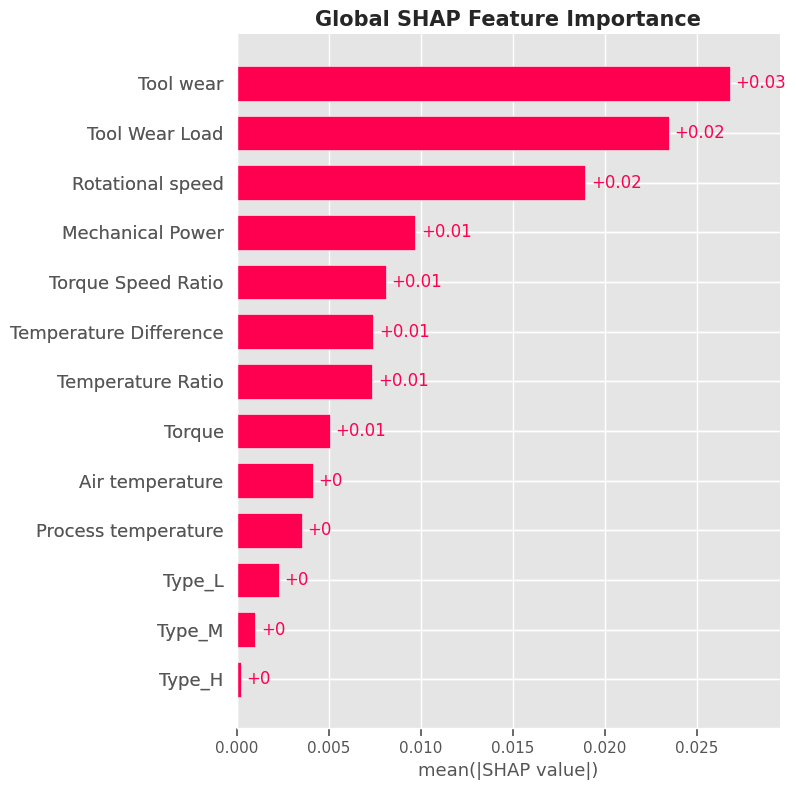

In [116]:
# Visualize global feature importance
shap.plots.bar(
    shap_values,
    max_display=20,
    show=False
)

plt.title(
    "Global SHAP Feature Importance",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

### 9.5 SHAP Summary Analysis

The SHAP beeswarm plot provides a comprehensive
visualization of feature attribution distributions.

Each point represents an explained observation.

The horizontal position indicates the direction
and magnitude of the feature contribution, while
color represents the transformed feature value.

The visualization supports interpretation of
complex model behavior across operating conditions.

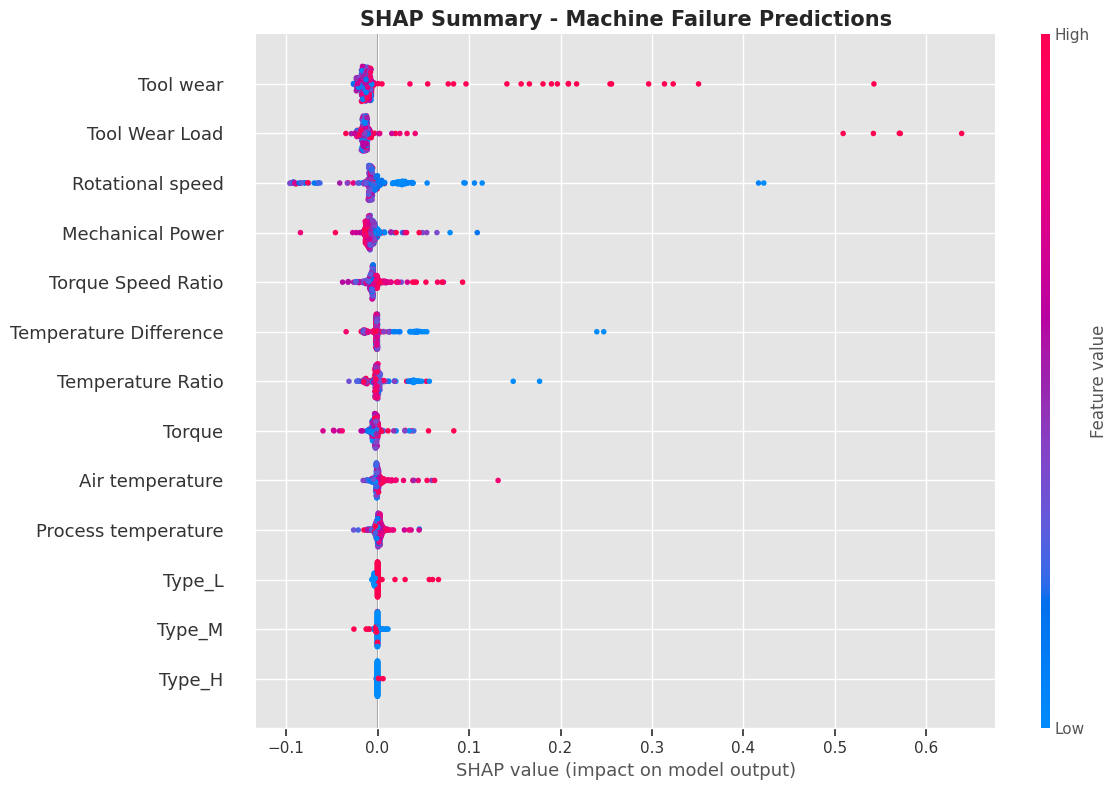

In [117]:
# Generate SHAP beeswarm summary plot
shap.plots.beeswarm(

    shap_values,

    max_display=20,

    show=False,

    plot_size=(12, 8)
)

plt.title(
    "SHAP Summary - Machine Failure Predictions",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

### 9.6 SHAP Dependence Analysis

SHAP dependence plots investigate the relationship
between individual feature values and their
estimated contributions to model predictions.

The three highest-ranked numerical features are
selected for detailed visualization.

The analysis supports identification of nonlinear
model behavior and potential feature interactions.

Observed relationships describe learned model
patterns rather than causal effects.

In [118]:
# Select the most influential numerical features
top_shap_features = shap_importance_df.loc[

    ~shap_importance_df["Feature"].str.startswith(
        "Type_"
    ),

    "Feature"

].head(3).tolist()

print("Top Numerical Features:")

for feature in top_shap_features:

    print(f"- {feature}")

Top Numerical Features:
- Tool wear
- Tool Wear Load
- Rotational speed


In [ ]:
# Generate feature dependence plots
for feature in top_shap_features:

    shap.plots.scatter(

        shap_values[:, feature],

        color=shap_values,

        show=False
    )

    plt.title(
        f"SHAP Dependence - {feature}",
        fontsize=14,
        fontweight="bold"
    )

    plt.tight_layout()
    plt.show()


### 9.7 Local Prediction Explainability

Local SHAP explanations are generated for individual
test observations representing different
classification outcomes.

The analysis considers:

- True positive predictions.
- True negative predictions.
- False positive predictions.
- False negative predictions.

Waterfall plots illustrate how individual feature
contributions move the model output from its
background value to the final failure score.

Representative examples are selected for descriptive
interpretation rather than model modification.

In [119]:
# Select examples from each prediction outcome
local_cases = []

local_rng = np.random.default_rng(
    RANDOM_STATE
)

for outcome in outcomes:

    subset = error_analysis_df[

        error_analysis_df["Prediction Outcome"]
        == outcome
    ]

    if subset.empty:

        continue

    selected_position = local_rng.integers(
        0,
        len(subset)
    )

    selected_case = subset.iloc[
        selected_position
    ]

    local_cases.append({

        "Observation Index": selected_case.name,

        "Prediction Outcome": outcome,

        "Actual Failure":
            int(selected_case["Machine failure"]),

        "Predicted Failure":
            int(selected_case["Predicted Failure"]),

        "Failure Score":
            selected_case["Failure Score"]
    })

local_cases_df = pd.DataFrame(
    local_cases
)

display(local_cases_df.round(4))

,Observation Index,Prediction Outcome,Actual Failure,Predicted Failure,Failure Score
0,8962,True Negative,0,0,0.0033
1,3794,False Positive,0,1,0.9771
2,9015,False Negative,1,0,0.1268
3,4600,True Positive,1,1,0.9874


In [120]:
# Prepare selected observations
local_shap_sample = X_test_shap.loc[

    local_cases_df["Observation Index"]

].copy()

# Calculate individual SHAP explanations
local_shap_values = shap_explainer(

    local_shap_sample,

    max_evals=SHAP_MAX_EVALS
)

print(
    f"Local Explanations Generated: "
    f"{len(local_shap_sample)}"
)

Local Explanations Generated: 4


Prediction Outcome: True Negative
Actual Failure: 0
Predicted Failure: 0
Failure Score: 0.0033
Decision Threshold: 0.8366


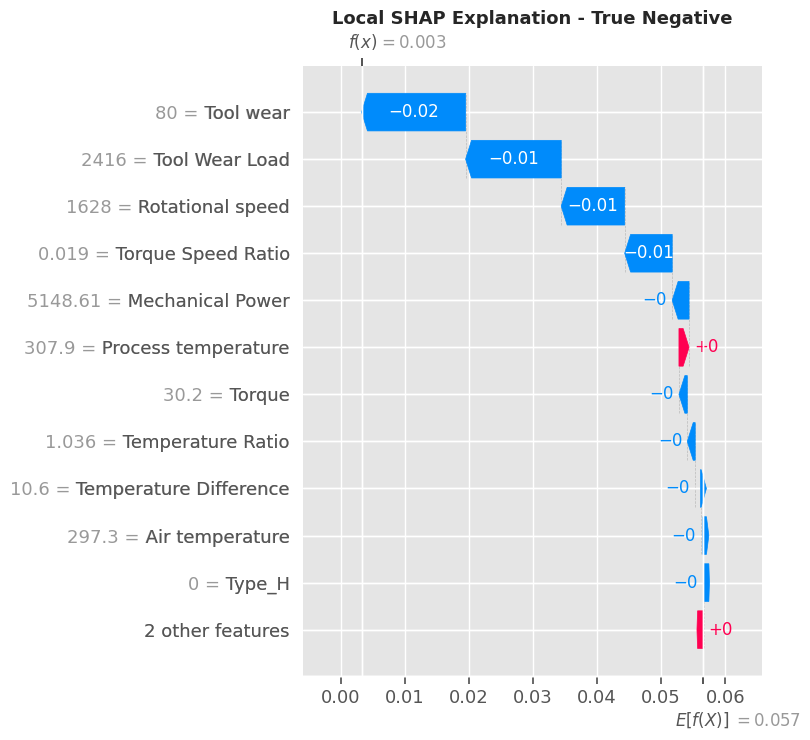

Prediction Outcome: False Positive
Actual Failure: 0
Predicted Failure: 1
Failure Score: 0.9771
Decision Threshold: 0.8366


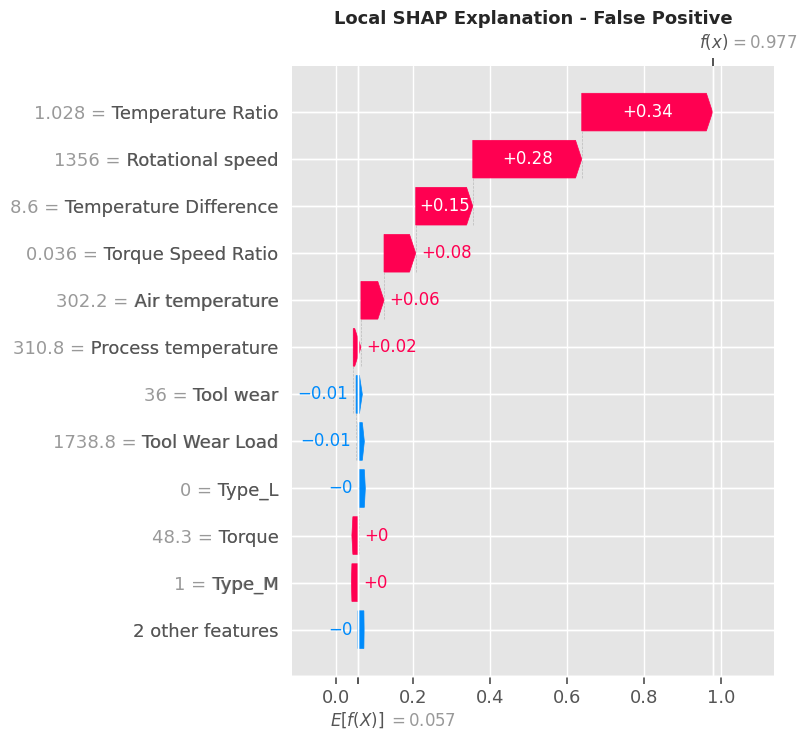

Prediction Outcome: False Negative
Actual Failure: 1
Predicted Failure: 0
Failure Score: 0.1268
Decision Threshold: 0.8366


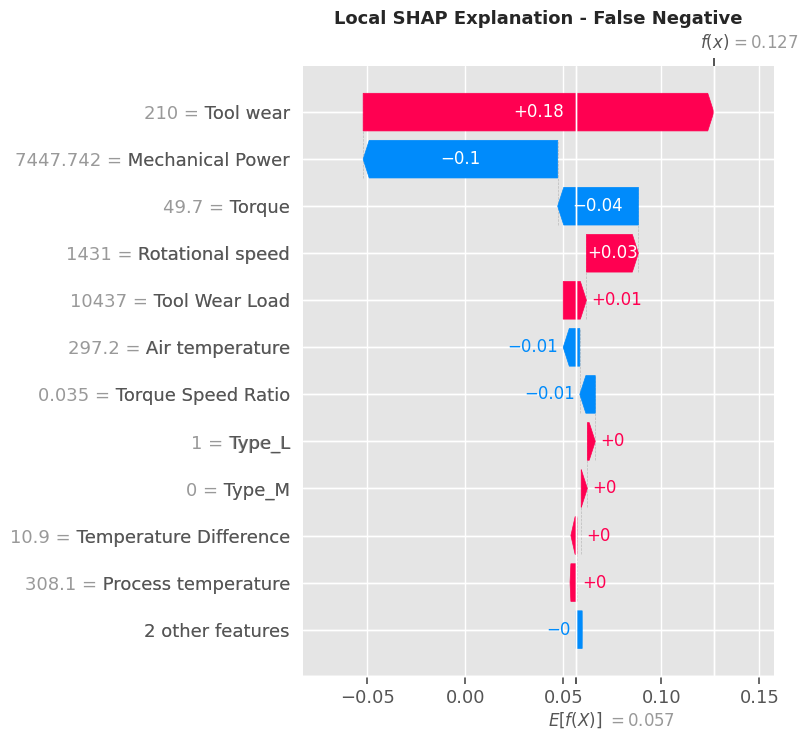

Prediction Outcome: True Positive
Actual Failure: 1
Predicted Failure: 1
Failure Score: 0.9874
Decision Threshold: 0.8366


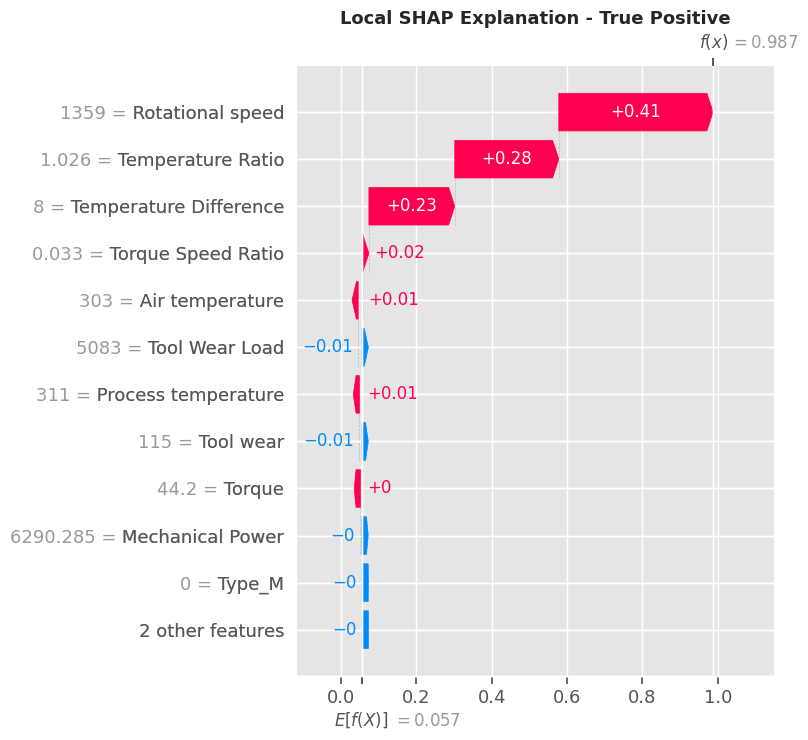

In [121]:
# Generate local waterfall explanations
for position, (_, case) in enumerate(
    local_cases_df.iterrows()
):

    print("=" * 60)

    print(
        f"Prediction Outcome: "
        f"{case['Prediction Outcome']}"
    )

    print(
        f"Actual Failure: "
        f"{case['Actual Failure']}"
    )

    print(
        f"Predicted Failure: "
        f"{case['Predicted Failure']}"
    )

    print(
        f"Failure Score: "
        f"{case['Failure Score']:.4f}"
    )

    print(
        f"Decision Threshold: "
        f"{optimal_threshold:.4f}"
    )

    shap.plots.waterfall(

        local_shap_values[position],

        max_display=12,

        show=False
    )

    plt.title(
        f"Local SHAP Explanation - "
        f"{case['Prediction Outcome']}",
        fontsize=13,
        fontweight="bold"
    )

    plt.tight_layout()
    plt.show()

### 9.8 Engineered Feature Contribution

SHAP feature attributions are grouped according
to their origin:

- Original sensor features.
- Categorical product features.
- Physics-informed engineered features.

The analysis estimates the relative attribution
share of each feature group.

Attribution shares complement the earlier ablation
study but do not independently establish incremental
predictive performance.

Correlated features may share or redistribute
SHAP contributions.

In [122]:
# Classify features according to their origin
def identify_feature_group(feature):

    if feature in engineered_features:

        return "Physics-Informed Features"

    elif feature.startswith("Type_"):

        return "Categorical Features"

    else:

        return "Original Sensor Features"


shap_importance_df["Feature Group"] = (

    shap_importance_df["Feature"]

    .apply(identify_feature_group)
)

# Aggregate feature group importance
feature_group_importance = (

    shap_importance_df

    .groupby("Feature Group")[
        "Mean Absolute SHAP"
    ]

    .sum()

    .reset_index()
)

feature_group_importance["Contribution (%)"] = (

    feature_group_importance["Mean Absolute SHAP"]

    /

    feature_group_importance[
        "Mean Absolute SHAP"
    ].sum()

) * 100

feature_group_importance = (
    feature_group_importance
    .sort_values(
        "Contribution (%)",
        ascending=False
    )
)

display(feature_group_importance.round(4))

,Feature Group,Mean Absolute SHAP,Contribution (%)
1,Original Sensor Features,0.0584,49.5200
2,Physics-Informed Features,0.0560,47.4975
0,Categorical Features,0.0035,2.9825


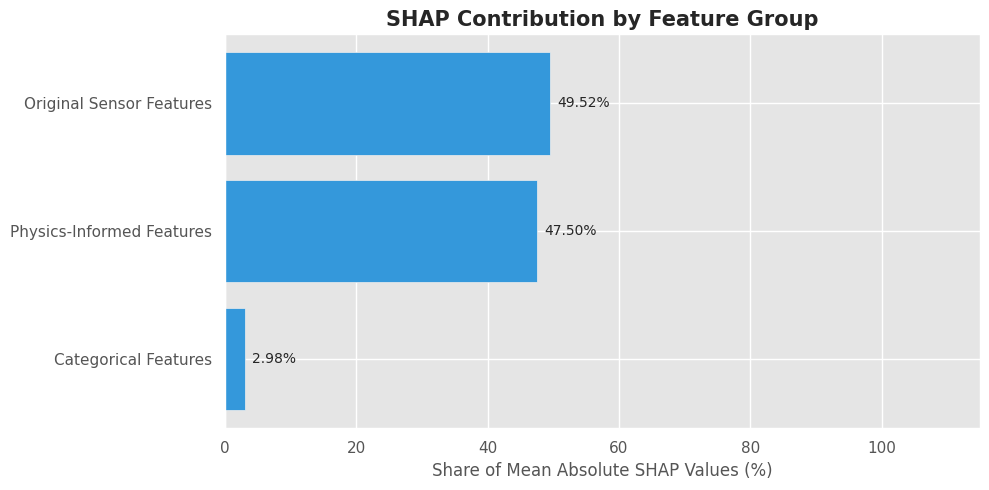

In [123]:
# Visualize feature group contribution
fig, ax = plt.subplots(
    figsize=(10, 5)
)

bars = ax.barh(

    feature_group_importance["Feature Group"],

    feature_group_importance["Contribution (%)"],

    color="#3498db"
)

ax.bar_label(
    bars,
    fmt="%.2f%%",
    padding=5
)

ax.set_title(
    "SHAP Contribution by Feature Group",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel(
    "Share of Mean Absolute SHAP Values (%)"
)

ax.set_xlim(0, 115)

ax.invert_yaxis()

plt.tight_layout()
plt.show()

In [124]:
# Generate explainability findings
print("=" * 60)
print("CELLSENSE - EXPLAINABILITY FINDINGS")
print("=" * 60)

print(f"Selected Model: {best_model_name}")
print(f"Feature Set: {best_feature_set}")

print(
    f"Explained Observations: "
    f"{len(shap_sample)}"
)

print("\nTop 5 Influential Features:")

for _, result in shap_importance_df.head(5).iterrows():

    print(
        f"{result['Rank']}. "
        f"{result['Feature']}: "
        f"{result['Importance (%)']:.2f}%"
    )

print("\nFeature Group Contributions:")

for _, result in feature_group_importance.iterrows():

    print(
        f"{result['Feature Group']}: "
        f"{result['Contribution (%)']:.2f}%"
    )

print(
    f"\nMaximum SHAP Additivity Error: "
    f"{reconstruction_errors.max():.10f}"
)

print("=" * 60)

CELLSENSE - EXPLAINABILITY FINDINGS
Selected Model: XGBoost
Feature Set: Physics-Informed
Explained Observations: 300

Top 5 Influential Features:
1. Tool wear: 22.70%
2. Tool Wear Load: 19.89%
3. Rotational speed: 16.05%
4. Mechanical Power: 8.23%
5. Torque Speed Ratio: 6.86%

Feature Group Contributions:
Original Sensor Features: 49.52%
Physics-Informed Features: 47.50%
Categorical Features: 2.98%

Maximum SHAP Additivity Error: 0.0000001748


### 9.9 Explainability Conclusions

The explainability framework provides global and
local interpretations of the final classification
model using SHAP feature attributions.

The analysis includes:

- Global feature importance.
- SHAP beeswarm visualization.
- Feature dependence analysis.
- Individual prediction explanations.
- Misclassification interpretation.
- Feature group attribution analysis.
- Mathematical additivity validation.

The results support interpretation of learned
relationships between operational measurements
and machine failure prediction scores.

SHAP values describe the behavior of the trained
model rather than physical failure causality.

Feature correlations, background sample selection,
and the synthetic nature of the dataset represent
important interpretation limitations.

The next stage investigates anomaly detection
as a complementary industrial monitoring approach.

## 10. Anomaly Detection

### 10.1 Anomaly Detection Framework

Isolation Forest is implemented as a complementary
approach to industrial condition monitoring.

The algorithm identifies unusual observations by
recursively partitioning the feature space.

A novelty detection framework is established by
training the model exclusively on observations
associated with normal machine operation.

The anomaly detection framework includes:

- Normal-operation training.
- Anomaly score computation.
- Independent test evaluation.
- Principal Component Analysis visualization.
- Failure mechanism analysis.
- Comparison with supervised classification.

Anomalous observations do not necessarily represent
machine failures, and machine failures are not
necessarily detectable as statistical anomalies.

In [125]:
# Import anomaly detection libraries
from sklearn.ensemble import IsolationForest
from sklearn.decomposition import PCA

# Configure anomaly detection experiment
ANOMALY_CONTAMINATION = 0.03
ANOMALY_N_ESTIMATORS = 300

print("=" * 60)
print("ANOMALY DETECTION FRAMEWORK")
print("=" * 60)

print("Algorithm: Isolation Forest")
print("Approach: Novelty Detection")

print(
    f"Number of Trees: "
    f"{ANOMALY_N_ESTIMATORS}"
)

print(
    f"Contamination Parameter: "
    f"{ANOMALY_CONTAMINATION}"
)

print("Training Data: Normal Observations Only")

ANOMALY DETECTION FRAMEWORK
Algorithm: Isolation Forest
Approach: Novelty Detection
Number of Trees: 300
Contamination Parameter: 0.03
Training Data: Normal Observations Only


### 10.2 Anomaly Detection Data Preparation

An independent preprocessing pipeline is established
for the anomaly detection experiment.

Original and selected physics-informed features
are included in the feature representation.

Only normal training observations are used to fit
the preprocessing pipeline and anomaly detector.

The test dataset remains excluded from training
and anomaly threshold selection.

In [126]:
# Define anomaly detection feature configuration
anomaly_features = final_features.copy()

# Select normal training observations
normal_training_mask = y_train == 0

X_anomaly_train = X_train.loc[
    normal_training_mask,
    anomaly_features
].copy()

# Prepare independent test observations
X_anomaly_test = X_test[
    anomaly_features
].copy()

# Build independent preprocessing pipeline
anomaly_preprocessor = build_preprocessor(
    anomaly_features,
    scale=True
)

# Fit exclusively on normal training data
X_anomaly_train_transformed = (
    anomaly_preprocessor.fit_transform(
        X_anomaly_train
    )
)

# Transform test observations
X_anomaly_test_transformed = (
    anomaly_preprocessor.transform(
        X_anomaly_test
    )
)

print("Normal Training Observations:",
      len(X_anomaly_train))

print("Test Observations:",
      len(X_anomaly_test))

print("Transformed Training Shape:",
      X_anomaly_train_transformed.shape)

print("Transformed Test Shape:",
      X_anomaly_test_transformed.shape)

Normal Training Observations: 7729
Test Observations: 2000
Transformed Training Shape: (7729, 13)
Transformed Test Shape: (2000, 13)


In [127]:
# Validate anomaly detection dataset
assert (y_train.loc[
    X_anomaly_train.index
] == 0).all()

assert X_anomaly_test.index.equals(
    y_test.index
)

assert np.isfinite(
    X_anomaly_train_transformed
).all()

assert np.isfinite(
    X_anomaly_test_transformed
).all()

assert not set(anomaly_features).intersection(
    ["Machine failure"] + failure_types
)

print("Anomaly detection data validation passed.")

Anomaly detection data validation passed.


### 10.3 Isolation Forest Training

The Isolation Forest model is trained using normal
operating observations.

The model constructs an ensemble of randomized
isolation trees to identify observations that
deviate from the learned normal operating patterns.

A fixed contamination parameter of 0.03 establishes
the experimental anomaly decision boundary.

The contamination parameter is not optimized using
the independent test dataset.

In [128]:
# Initialize Isolation Forest
isolation_forest = IsolationForest(

    n_estimators=ANOMALY_N_ESTIMATORS,

    contamination=ANOMALY_CONTAMINATION,

    max_samples="auto",

    max_features=1.0,

    random_state=RANDOM_STATE,

    n_jobs=-1
)

# Record training time
anomaly_training_start = time.perf_counter()

# Train on normal observations
isolation_forest.fit(
    X_anomaly_train_transformed
)

anomaly_training_time = (
    time.perf_counter()
    - anomaly_training_start
)

print("=" * 55)
print("ISOLATION FOREST TRAINING COMPLETED")
print("=" * 55)

print(
    f"Training Time: "
    f"{anomaly_training_time:.4f} seconds"
)

print(
    f"Number of Trees: "
    f"{len(isolation_forest.estimators_)}"
)

print(
    f"Samples Per Tree: "
    f"{isolation_forest.max_samples_}"
)

print(
    f"Decision Offset: "
    f"{isolation_forest.offset_:.6f}"
)

ISOLATION FOREST TRAINING COMPLETED
Training Time: 1.4099 seconds
Number of Trees: 300
Samples Per Tree: 256
Decision Offset: -0.582093


### 10.4 Anomaly Score Analysis

Anomaly scores are generated for the independent
test observations.

The original Isolation Forest decision function
is sign-inverted so that higher values represent
greater abnormality.

Positive anomaly scores correspond to observations
classified as anomalous under the fixed decision rule.

Anomaly scores are not calibrated failure
probabilities.

In [129]:
# Generate anomaly predictions
raw_anomaly_predictions = isolation_forest.predict(
    X_anomaly_test_transformed
)

# Convert Isolation Forest outputs into binary labels
anomaly_predictions = (
    raw_anomaly_predictions == -1
).astype(int)

# Higher values represent greater abnormality
anomaly_scores = -isolation_forest.decision_function(
    X_anomaly_test_transformed
)

# Create analysis dataset
anomaly_analysis_df = test_df.copy()

anomaly_analysis_df["Anomaly Score"] = (
    anomaly_scores
)

anomaly_analysis_df["Anomaly Prediction"] = (
    anomaly_predictions
)

anomaly_analysis_df["Failure Status"] = (

    anomaly_analysis_df["Machine failure"]

    .map({
        0: "No Failure",
        1: "Failure"
    })
)

assert np.array_equal(
    anomaly_predictions,
    (anomaly_scores > 0).astype(int)
)

print(
    f"Detected Anomalies: "
    f"{anomaly_predictions.sum()}"
)

print(
    f"Anomaly Detection Rate: "
    f"{anomaly_predictions.mean() * 100:.2f}%"
)

display(anomaly_analysis_df[
    [
        "Machine failure",
        "Anomaly Score",
        "Anomaly Prediction"
    ]
].head(10))

Detected Anomalies: 74
Anomaly Detection Rate: 3.70%


,Machine failure,Anomaly Score,Anomaly Prediction
2997,0,-0.040109,0
4871,0,-0.114103,0
3858,0,-0.122998,0
951,0,-0.020614,0
6463,0,-0.006833,0
3264,0,-0.034957,0
4508,0,-0.077459,0
2100,0,-0.123789,0
7885,0,-0.111896,0
2421,0,0.023851,1


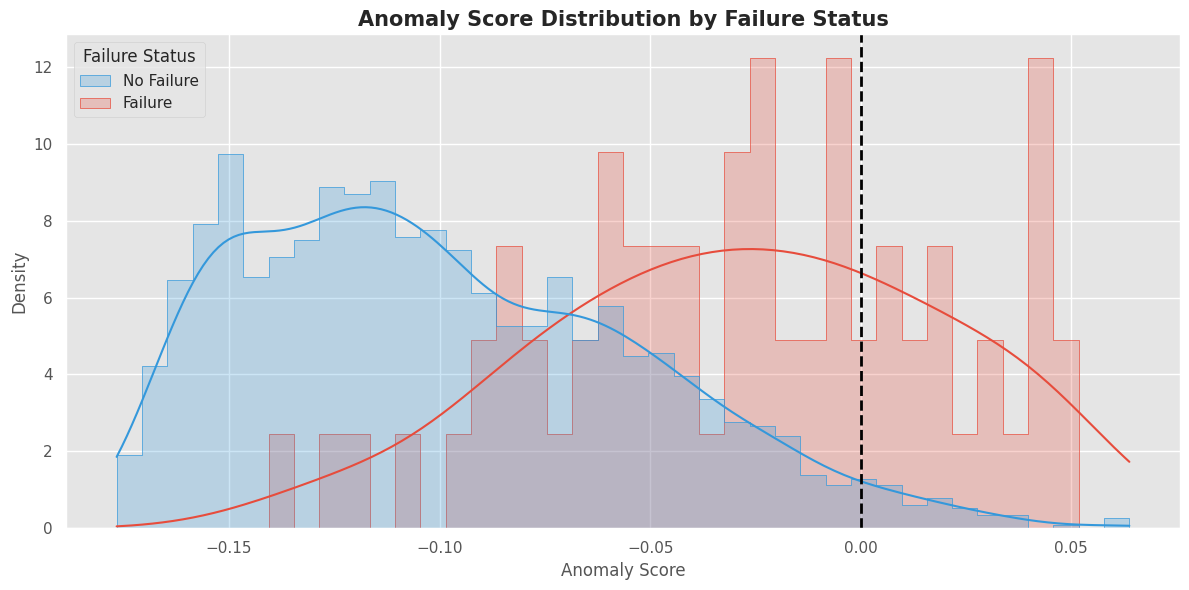

In [130]:
# Analyze anomaly score distributions
plt.figure(figsize=(12, 6))

sns.histplot(

    data=anomaly_analysis_df,

    x="Anomaly Score",

    hue="Failure Status",

    bins=40,

    stat="density",

    common_norm=False,

    element="step",

    kde=True,

    palette={
        "No Failure": "#3498db",
        "Failure": "#e74c3c"
    }
)

plt.axvline(
    0,
    color="black",
    linestyle="--",
    linewidth=2,
    label="Anomaly Decision Boundary"
)

plt.title(
    "Anomaly Score Distribution by Failure Status",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Anomaly Score")
plt.ylabel("Density")

plt.tight_layout()
plt.show()

,count,mean,median,std,min,max
Failure Status,,,,,,
Failure,68,-0.0276,-0.0261,0.0464,-0.1349,0.0483
No Failure,1932,-0.0993,-0.1067,0.0464,-0.1767,0.0638


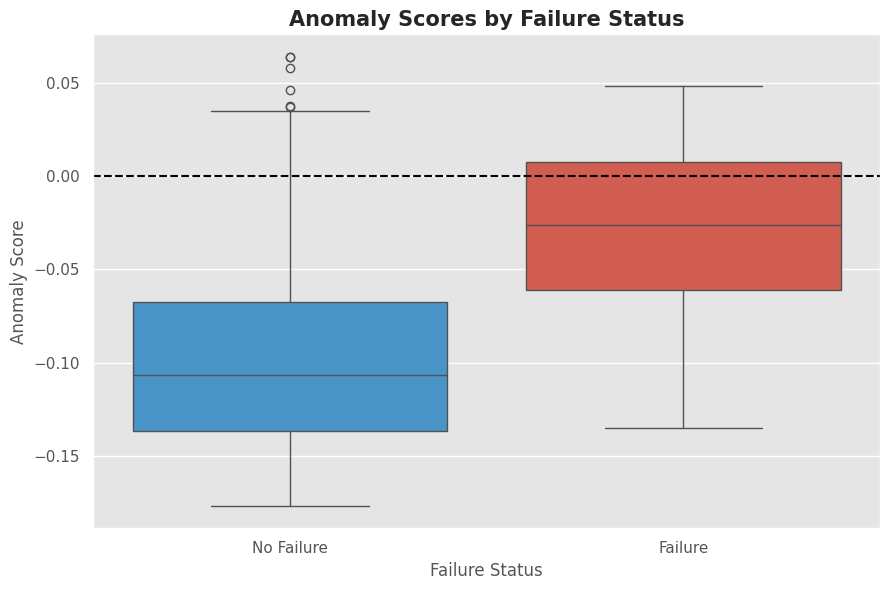

In [131]:
# Compare anomaly scores by actual failure status
anomaly_score_statistics = (

    anomaly_analysis_df

    .groupby("Failure Status")["Anomaly Score"]

    .agg([
        "count",
        "mean",
        "median",
        "std",
        "min",
        "max"
    ])
)

display(anomaly_score_statistics.round(4))

plt.figure(figsize=(9, 6))

sns.boxplot(

    data=anomaly_analysis_df,

    x="Failure Status",

    y="Anomaly Score",

    hue="Failure Status",

    palette={
        "No Failure": "#3498db",
        "Failure": "#e74c3c"
    },

    legend=False
)

plt.axhline(
    0,
    color="black",
    linestyle="--"
)

plt.title(
    "Anomaly Scores by Failure Status",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

### 10.5 Anomaly Detection Evaluation

The anomaly detector is evaluated against the
available machine failure labels.

Classification metrics are used to investigate
the correspondence between statistical anomalies
and actual machine failures.

ROC-AUC and Average Precision assess the ranking
ability of anomaly scores.

The evaluation does not assume that statistical
anomalies and physical failures are equivalent.

In [132]:
# Calculate anomaly detection metrics
anomaly_metrics = calculate_test_metrics(

    y_test,

    anomaly_predictions,

    anomaly_scores,

    threshold=0.0
)

anomaly_metrics_df = pd.DataFrame(

    anomaly_metrics,

    index=["Isolation Forest"]
).T

display(anomaly_metrics_df.round(4))

,Isolation Forest
Threshold,0.0000
Accuracy,0.9490
Balanced Accuracy,0.6331
Precision,0.2703
Recall,0.2941
Specificity,0.9720
F1-score,0.2817
F2-score,0.2890
ROC-AUC,0.8561
Average Precision,0.2286


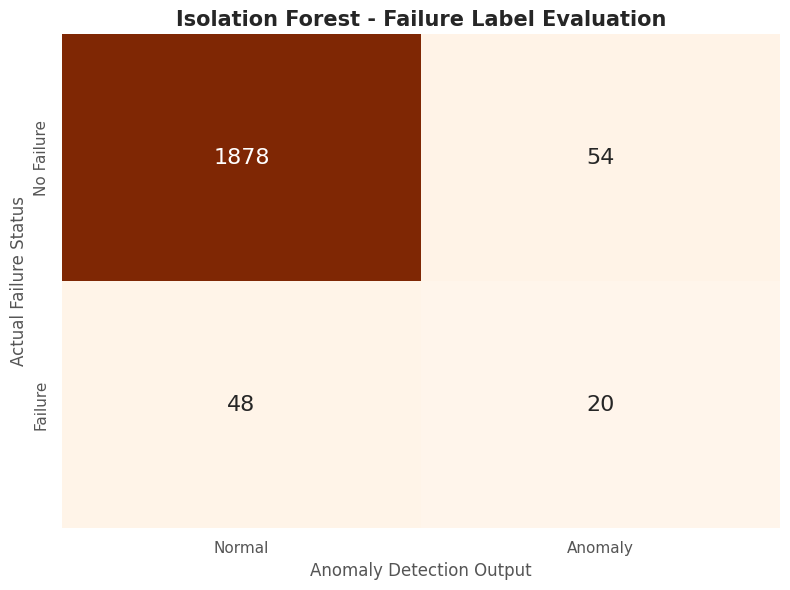

In [133]:
# Calculate anomaly detection confusion matrix
cm_anomaly = confusion_matrix(

    y_test,

    anomaly_predictions,

    labels=[0, 1]
)

plt.figure(figsize=(8, 6))

sns.heatmap(

    cm_anomaly,

    annot=True,

    fmt="d",

    cmap="Oranges",

    cbar=False,

    xticklabels=[
        "Normal",
        "Anomaly"
    ],

    yticklabels=[
        "No Failure",
        "Failure"
    ],

    annot_kws={"size": 16}
)

plt.title(
    "Isolation Forest - Failure Label Evaluation",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Anomaly Detection Output")
plt.ylabel("Actual Failure Status")

plt.tight_layout()
plt.show()

### 10.6 Principal Component Analysis Visualization

Principal Component Analysis is used to obtain
a two-dimensional representation of the
high-dimensional feature space.

PCA is fitted exclusively on preprocessed normal
training observations.

The resulting projection supports visualization of:

- Normal operating observations.
- Actual machine failures.
- Detected statistical anomalies.
- Potential overlap between operating conditions.

PCA is used for visualization only and is not
part of the anomaly detector's feature space.

In [134]:
# Initialize PCA
anomaly_pca = PCA(
    n_components=2,
    random_state=RANDOM_STATE
)

# Fit PCA on normal training observations
anomaly_pca.fit(
    X_anomaly_train_transformed
)

# Transform test observations
X_anomaly_pca = anomaly_pca.transform(
    X_anomaly_test_transformed
)

# Create visualization dataset
pca_visualization_df = pd.DataFrame({

    "PC1": X_anomaly_pca[:, 0],

    "PC2": X_anomaly_pca[:, 1],

    "Failure Status":
        anomaly_analysis_df["Failure Status"].to_numpy(),

    "Anomaly Status":

        np.where(
            anomaly_predictions == 1,
            "Anomaly",
            "Normal"
        ),

    "Anomaly Score": anomaly_scores

}, index=y_test.index)

# Calculate explained variance
pca_variance_df = pd.DataFrame({

    "Component": ["PC1", "PC2"],

    "Explained Variance (%)":

        anomaly_pca.explained_variance_ratio_ * 100
})

display(pca_variance_df.round(4))

print(

    f"Total Explained Variance: "

    f"{anomaly_pca.explained_variance_ratio_.sum() * 100:.2f}%"
)

,Component,Explained Variance (%)
0,PC1,37.3729
1,PC2,28.0286


Total Explained Variance: 65.40%


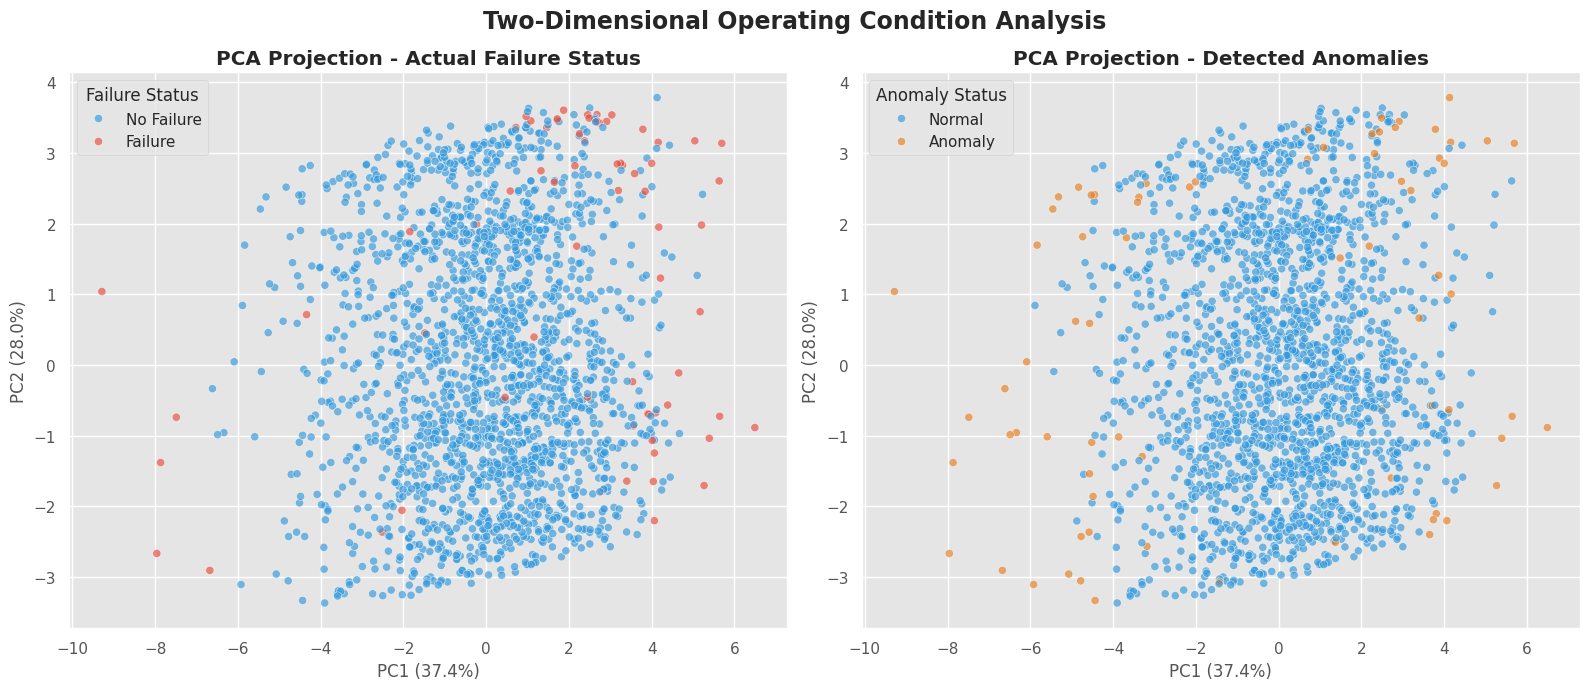

In [135]:
# Visualize PCA projections
fig, axes = plt.subplots(
    1, 2,
    figsize=(16, 7)
)

sns.scatterplot(

    data=pca_visualization_df,

    x="PC1",

    y="PC2",

    hue="Failure Status",

    palette={
        "No Failure": "#3498db",
        "Failure": "#e74c3c"
    },

    alpha=0.65,

    s=35,

    ax=axes[0]
)

axes[0].set_title(
    "PCA Projection - Actual Failure Status",
    fontweight="bold"
)

sns.scatterplot(

    data=pca_visualization_df,

    x="PC1",

    y="PC2",

    hue="Anomaly Status",

    palette={
        "Normal": "#3498db",
        "Anomaly": "#e67e22"
    },

    alpha=0.65,

    s=35,

    ax=axes[1]
)

axes[1].set_title(
    "PCA Projection - Detected Anomalies",
    fontweight="bold"
)

for ax in axes:

    ax.set_xlabel(
        f"PC1 ({anomaly_pca.explained_variance_ratio_[0] * 100:.1f}%)"
    )

    ax.set_ylabel(
        f"PC2 ({anomaly_pca.explained_variance_ratio_[1] * 100:.1f}%)"
    )

plt.suptitle(
    "Two-Dimensional Operating Condition Analysis",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

### 10.7 Anomaly Detection by Failure Mechanism

Anomaly detection performance is investigated
across the available machine failure mechanisms.

The analysis evaluates whether different failure
types are associated with deviations from normal
operating conditions.

Failure mechanism indicators are used exclusively
for post-training evaluation.

Failure categories may overlap because multiple
failure mechanisms can occur within an observation.

In [136]:
# Evaluate anomalies by failure mechanism
anomaly_failure_results = []

for failure_type in failure_types:

    failure_subset = anomaly_analysis_df[

        (anomaly_analysis_df[failure_type] == 1)

        &

        (anomaly_analysis_df["Machine failure"] == 1)
    ]

    total_failures = len(failure_subset)

    detected_anomalies = int(

        failure_subset["Anomaly Prediction"].sum()
    )

    undetected_failures = (

        total_failures - detected_anomalies
    )

    anomaly_detection_rate = (

        detected_anomalies / total_failures

        if total_failures > 0

        else np.nan
    )

    anomaly_failure_results.append({

        "Failure Type": failure_names[failure_type],

        "Total Failures": total_failures,

        "Detected as Anomalies": detected_anomalies,

        "Not Detected as Anomalies": undetected_failures,

        "Anomaly Detection Rate": anomaly_detection_rate
    })

anomaly_failure_df = pd.DataFrame(
    anomaly_failure_results
)

display(anomaly_failure_df.round(4))

,Failure Type,Total Failures,Detected as Anomalies,Not Detected as Anomalies,Anomaly Detection Rate
0,Tool Wear Failure,10,2,8,0.2000
1,Heat Dissipation Failure,29,7,22,0.2414
2,Power Failure,13,9,4,0.6923
3,Overstrain Failure,16,4,12,0.2500
4,Random Failure,0,0,0,NaN


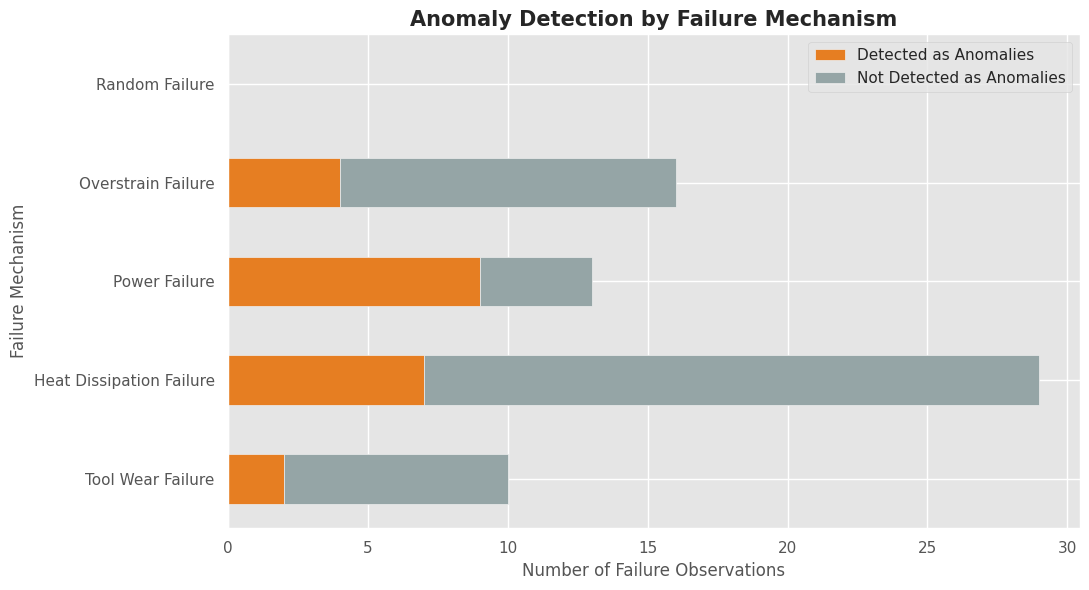

In [137]:
# Visualize anomaly detection by failure mechanism
anomaly_failure_df.set_index(
    "Failure Type"
)[[
    "Detected as Anomalies",
    "Not Detected as Anomalies"
]].plot(

    kind="barh",

    stacked=True,

    figsize=(11, 6),

    color=["#e67e22", "#95a5a6"]
)

plt.title(
    "Anomaly Detection by Failure Mechanism",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Number of Failure Observations")
plt.ylabel("Failure Mechanism")

plt.legend()
plt.tight_layout()
plt.show()

### 10.8 Supervised Classification and Anomaly Detection

The supervised classification model and Isolation
Forest detector are compared using the same
independent test observations.

The comparison investigates their complementary
behavior rather than assuming identical objectives.

Classification agreement analysis identifies
observations flagged by:

- Both approaches.
- Supervised classification only.
- Anomaly detection only.
- Neither approach.

The comparison is descriptive and does not introduce
a new combined decision rule or post-test tuning.

In [139]:
# Compare supervised and anomaly detection metrics
comparison_metric_names = [

    "Accuracy",

    "Balanced Accuracy",

    "Precision",

    "Recall",

    "Specificity",

    "F1-score",

    "F2-score",

    "ROC-AUC",

    "Average Precision",

    "False Positive Rate",

    "False Negative Rate"
]

supervised_anomaly_comparison = pd.DataFrame({

    "Metric": comparison_metric_names,

    "Supervised Model": [

        optimized_test_metrics[metric]

        for metric in comparison_metric_names
    ],

    "Isolation Forest": [

        anomaly_metrics[metric]

        for metric in comparison_metric_names
    ]
})

display(
    supervised_anomaly_comparison.round(4)
)

,Metric,Supervised Model,Isolation Forest
0,Accuracy,0.9930,0.9490
1,Balanced Accuracy,0.9112,0.6331
2,Precision,0.9655,0.2703
3,Recall,0.8235,0.2941
4,Specificity,0.9990,0.9720
5,F1-score,0.8889,0.2817
6,F2-score,0.8485,0.2890
7,ROC-AUC,0.9809,0.8561
8,Average Precision,0.9089,0.2286
9,False Positive Rate,0.0010,0.0280


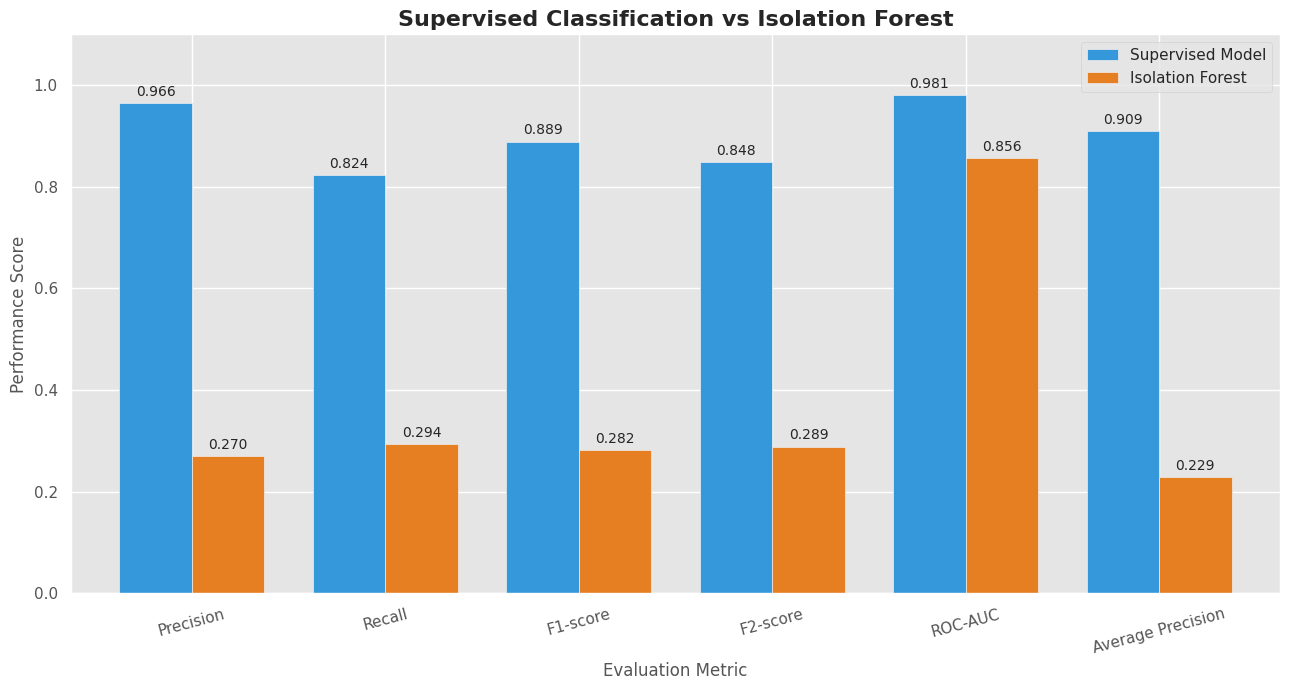

In [140]:
# Visualize performance comparison
selected_comparison_metrics = [

    "Precision",

    "Recall",

    "F1-score",

    "F2-score",

    "ROC-AUC",

    "Average Precision"
]

comparison_visualization = (

    supervised_anomaly_comparison[

        supervised_anomaly_comparison["Metric"]

        .isin(selected_comparison_metrics)
    ]

    .set_index("Metric")
)

ax = comparison_visualization.plot(

    kind="bar",

    figsize=(13, 7),

    color=["#3498db", "#e67e22"],

    width=0.75
)

for container in ax.containers:

    ax.bar_label(
        container,
        fmt="%.3f",
        padding=3
    )

plt.title(
    "Supervised Classification vs Isolation Forest",
    fontsize=16,
    fontweight="bold"
)

plt.ylabel("Performance Score")
plt.xlabel("Evaluation Metric")

plt.xticks(rotation=15)
plt.ylim(0, 1.1)

plt.tight_layout()
plt.show()

In [141]:
# Analyze prediction agreement
monitoring_comparison_df = pd.DataFrame({

    "Actual Failure": y_test.to_numpy(),

    "Supervised Prediction": y_pred_optimized,

    "Anomaly Prediction": anomaly_predictions,

    "Failure Score": test_probabilities,

    "Anomaly Score": anomaly_scores

}, index=y_test.index)

# Define agreement categories
agreement_conditions = [

    (y_pred_optimized == 1) &
    (anomaly_predictions == 1),

    (y_pred_optimized == 1) &
    (anomaly_predictions == 0),

    (y_pred_optimized == 0) &
    (anomaly_predictions == 1),

    (y_pred_optimized == 0) &
    (anomaly_predictions == 0)
]

agreement_labels = [

    "Both Detectors",

    "Supervised Only",

    "Anomaly Only",

    "Neither Detector"
]

monitoring_comparison_df["Detection Agreement"] = (

    np.select(

        agreement_conditions,

        agreement_labels,

        default="Unknown"
    )
)

agreement_summary = pd.crosstab(

    monitoring_comparison_df["Detection Agreement"],

    monitoring_comparison_df["Actual Failure"]

).reindex(

    index=agreement_labels,

    columns=[0, 1],

    fill_value=0
)

agreement_summary.columns = [

    "No Failure",

    "Failure"
]

agreement_summary["Total"] = (
    agreement_summary.sum(axis=1)
)

display(agreement_summary)

,No Failure,Failure,Total
Detection Agreement,,,
Both Detectors,0,19,19
Supervised Only,2,37,39
Anomaly Only,54,1,55
Neither Detector,1876,11,1887


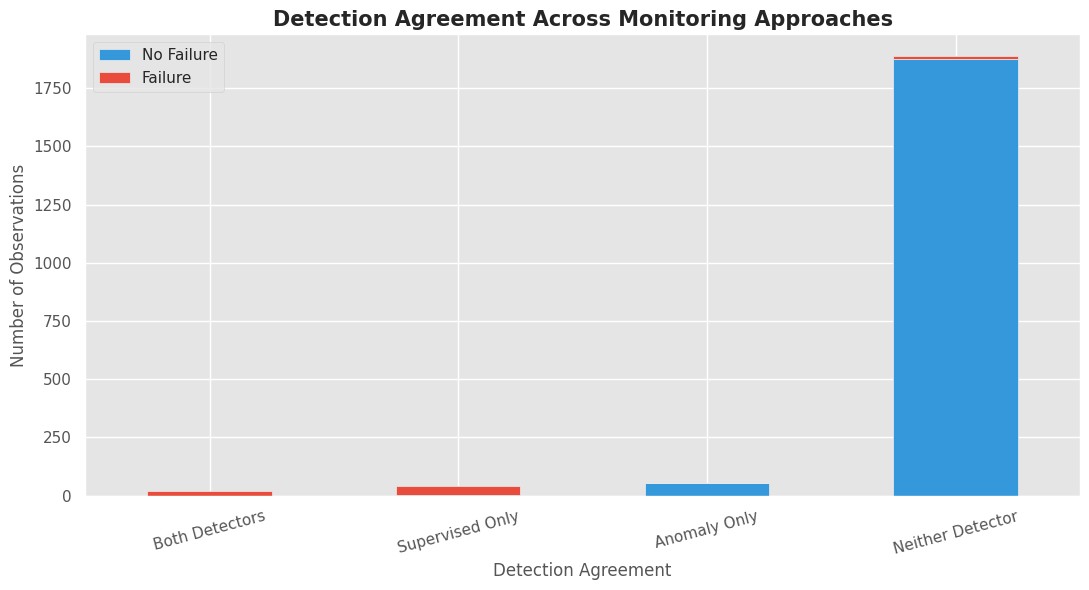

In [142]:
# Visualize detection agreement
agreement_summary[[
    "No Failure",
    "Failure"
]].plot(

    kind="bar",

    stacked=True,

    figsize=(11, 6),

    color=["#3498db", "#e74c3c"]
)

plt.title(
    "Detection Agreement Across Monitoring Approaches",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Detection Agreement")
plt.ylabel("Number of Observations")

plt.xticks(rotation=15)

plt.legend()
plt.tight_layout()
plt.show()

In [143]:
# Investigate complementary detection behavior
additional_detected_failures = (

    (y_test.to_numpy() == 1)

    &

    (y_pred_optimized == 0)

    &

    (anomaly_predictions == 1)

).sum()

additional_false_alarms = (

    (y_test.to_numpy() == 0)

    &

    (y_pred_optimized == 0)

    &

    (anomaly_predictions == 1)

).sum()

print("=" * 60)
print("COMPLEMENTARY DETECTION ANALYSIS")
print("=" * 60)

print(

    "Failures flagged exclusively by Isolation Forest:",

    additional_detected_failures
)

print(

    "Non-failure observations flagged exclusively "
    "by Isolation Forest:",

    additional_false_alarms
)

print("=" * 60)

COMPLEMENTARY DETECTION ANALYSIS
Failures flagged exclusively by Isolation Forest: 1
Non-failure observations flagged exclusively by Isolation Forest: 54


In [144]:
# Generate final anomaly detection summary
print("=" * 65)
print("CELLSENSE - ANOMALY DETECTION FINDINGS")
print("=" * 65)

print("Algorithm: Isolation Forest")

print(
    f"Normal Training Observations: "
    f"{len(X_anomaly_train)}"
)

print(
    f"Test Observations: "
    f"{len(X_anomaly_test)}"
)

print(
    f"Detected Anomalies: "
    f"{anomaly_predictions.sum()}"
)

print(
    f"Anomaly Detection Rate: "
    f"{anomaly_predictions.mean() * 100:.2f}%"
)

print("-" * 65)

for metric in [

    "Precision",

    "Recall",

    "F1-score",

    "F2-score",

    "ROC-AUC",

    "Average Precision"

]:

    print(
        f"{metric}: "
        f"{anomaly_metrics[metric]:.4f}"
    )

print("-" * 65)

print(

    "Failures Identified Only by Isolation Forest:",

    additional_detected_failures
)

print(

    "Additional Non-Failure Alerts:",

    additional_false_alarms
)

print(

    f"PCA Explained Variance: "

    f"{anomaly_pca.explained_variance_ratio_.sum() * 100:.2f}%"
)

print("=" * 65)

CELLSENSE - ANOMALY DETECTION FINDINGS
Algorithm: Isolation Forest
Normal Training Observations: 7729
Test Observations: 2000
Detected Anomalies: 74
Anomaly Detection Rate: 3.70%
-----------------------------------------------------------------
Precision: 0.2703
Recall: 0.2941
F1-score: 0.2817
F2-score: 0.2890
ROC-AUC: 0.8561
Average Precision: 0.2286
-----------------------------------------------------------------
Failures Identified Only by Isolation Forest: 1
Additional Non-Failure Alerts: 54
PCA Explained Variance: 65.40%


### 10.9 Anomaly Detection Conclusions

Isolation Forest was implemented as a complementary
novelty detection approach for industrial monitoring.

The anomaly detection framework included:

- Normal-operation model training.
- Independent preprocessing.
- Anomaly score distribution analysis.
- Classification-based evaluation.
- Principal Component Analysis visualization.
- Failure mechanism analysis.
- Supervised and anomaly detection comparison.
- Complementary detection assessment.

The experiment investigates the ability of statistical
anomaly detection to identify deviations from learned
normal operating conditions.

Statistical abnormalities do not necessarily indicate
physical machine failures.

The experimental contamination parameter, feature
representation, and synthetic dataset characteristics
represent important limitations.

Further validation using real-world industrial data
would be necessary before operational deployment.

## 11. Final Conclusions

### 11.1 Project Results Summary

CellSense Advanced integrates statistical analysis,
physics-informed feature engineering, supervised
machine learning, explainable artificial intelligence,
and anomaly detection into a unified industrial
condition monitoring framework.

The project investigates machine failure classification
using operational measurements from the AI4I 2020
Predictive Maintenance dataset.

The final results summarize the experimental
methodology, predictive performance, interpretability,
and complementary anomaly detection capabilities.

In [145]:
# Generate comprehensive project summary
project_summary = pd.DataFrame({

    "Component": [

        "Dataset Observations",
        "Training Observations",
        "Test Observations",
        "Total Machine Failures",
        "Failure Prevalence (%)",
        "Original Features",
        "Engineered Features Created",
        "Retained Engineered Features",
        "Classification Algorithms",
        "Feature Configurations",
        "Cross-Validation Folds",
        "Optuna Trials",
        "Bootstrap Samples",
        "SHAP Explained Observations",
        "Anomaly Detection Algorithm",
        "PCA Components"
    ],

    "Result": [

        len(df),
        len(y_train),
        len(y_test),
        int(df["Machine failure"].sum()),
        round(df["Machine failure"].mean() * 100, 2),
        len(original_features),
        len(engineered_features),
        len(selected_engineered_features),
        len(models),
        len(feature_configurations),
        N_SPLITS,
        len(study.trials),
        N_BOOTSTRAPS,
        len(shap_sample),
        "Isolation Forest",
        anomaly_pca.n_components_
    ]
})

display(project_summary)

,Component,Result
0,Dataset Observations,10000
1,Training Observations,8000
2,Test Observations,2000
3,Total Machine Failures,339
4,Failure Prevalence (%),3.39
5,Original Features,6
6,Engineered Features Created,6
7,Retained Engineered Features,5
8,Classification Algorithms,5
9,Feature Configurations,2


### 11.2 Key Statistical Findings

Statistical analysis was conducted to investigate
associations between operational measurements,
product types, and machine failure outcomes.

The analytical framework incorporated:

- Shapiro-Wilk normality assessment.
- Mann-Whitney U hypothesis testing.
- Rank-biserial correlation effect sizes.
- Chi-square independence testing.
- Cramer's V association measurement.
- Benjamini-Hochberg multiple-testing correction.

Statistical significance and practical effect sizes
were considered separately.

The findings describe exploratory associations
rather than verified causal relationships.

In [146]:
# Summarize statistically significant sensor features
significant_sensor_results = mann_whitney_df.loc[

    mann_whitney_df["Significant After Correction"]

].copy()

print("=" * 65)
print("FINAL STATISTICAL FINDINGS")
print("=" * 65)

print(
    f"Significance Level: {ALPHA}"
)

print(
    f"Sensor Features Tested: "
    f"{len(sensor_columns)}"
)

print(
    f"Significant Sensor Features After Correction: "
    f"{len(significant_sensor_results)}"
)

if significant_sensor_results.empty:

    print(
        "\nNo sensor features remained statistically "
        "significant after correction."
    )

else:

    display(

        significant_sensor_results[[
            "Feature",
            "P-value",
            "Adjusted P-value",
            "Significant After Correction"
        ]].round(6)
    )

print("\nCategorical Association Results:")

display(categorical_results.round(4))

print("=" * 65)

FINAL STATISTICAL FINDINGS
Significance Level: 0.05
Sensor Features Tested: 5
Significant Sensor Features After Correction: 5


,Feature,P-value,Adjusted P-value,Significant After Correction
0,Torque,0.000000,0.00000,True
1,Rotational speed,0.000000,0.00000,True
2,Tool wear,0.000000,0.00000,True
3,Air temperature,0.000000,0.00000,True
4,Process temperature,0.000066,0.00008,True



Categorical Association Results:


,Feature,Statistical Test,Chi-Square Statistic,Degrees of Freedom,P-value,Cramer's V,Significant,Adjusted P-value,Significant After Correction
0,Product Type,Chi-Square,18.0942,2,0.0001,0.0476,True,0.0001,True


In [147]:
# Summarize feature ablation findings
final_ablation_summary = ablation_results[

    ablation_results["Model"] != "Dummy Classifier"

][[
    "Model",
    "Average Precision_mean_original",
    "Average Precision_mean_engineered",
    "Average Precision_Improvement",
    "Relative AP Improvement (%)"
]].copy()

final_ablation_summary.columns = [

    "Model",
    "Original Features AP",
    "Engineered Features AP",
    "Absolute AP Change",
    "Relative AP Change (%)"
]

display(final_ablation_summary.round(4))

print(

    "Models Improved by Feature Engineering:",

    (
        final_ablation_summary["Absolute AP Change"]
        > 0
    ).sum(),

    "/",

    len(final_ablation_summary)
)

,Model,Original Features AP,Engineered Features AP,Absolute AP Change,Relative AP Change (%)
0,Random Forest,0.7511,0.8853,0.1342,17.8620
1,XGBoost,0.7748,0.8883,0.1135,14.6521
2,LightGBM,0.7802,0.8846,0.1045,13.3907
3,Logistic Regression,0.4409,0.4449,0.0040,0.9033


Models Improved by Feature Engineering: 4 / 4


### 11.3 Machine Learning Findings

The final supervised model configuration was
selected using stratified cross-validation and
Average Precision as the primary selection metric.

Automated hyperparameter optimization and decision
threshold analysis were conducted exclusively
within the training dataset.

Final performance was assessed using an independent
held-out test dataset.

The evaluation included classification metrics,
operational error analysis, and bootstrap-based
uncertainty estimation.

In [148]:
# Create final model performance summary
final_performance_summary = pd.DataFrame({

    "Metric": [

        "Selected Model",
        "Feature Configuration",
        "Hyperparameter Configuration",
        "Decision Threshold",
        "Cross-Validation Average Precision",
        "Test Average Precision",
        "Test ROC-AUC",
        "Test Accuracy",
        "Test Balanced Accuracy",
        "Test Precision",
        "Test Recall",
        "Test Specificity",
        "Test F1-score",
        "Test F2-score",
        "Detected Failures",
        "Missed Failures",
        "False Alarms",
        "Correct Normal Predictions"
    ],

    "Value": [

        best_model_name,
        best_feature_set,
        final_configuration_type,
        round(optimal_threshold, 4),
        round(final_cv_ap, 4),
        round(optimized_test_metrics["Average Precision"], 4),
        round(optimized_test_metrics["ROC-AUC"], 4),
        round(optimized_test_metrics["Accuracy"], 4),
        round(optimized_test_metrics["Balanced Accuracy"], 4),
        round(optimized_test_metrics["Precision"], 4),
        round(optimized_test_metrics["Recall"], 4),
        round(optimized_test_metrics["Specificity"], 4),
        round(optimized_test_metrics["F1-score"], 4),
        round(optimized_test_metrics["F2-score"], 4),
        int(cm_optimized[1, 1]),
        int(cm_optimized[1, 0]),
        int(cm_optimized[0, 1]),
        int(cm_optimized[0, 0])
    ]
})

display(final_performance_summary)

,Metric,Value
0,Selected Model,XGBoost
1,Feature Configuration,Physics-Informed
2,Hyperparameter Configuration,Optimized
3,Decision Threshold,0.8366
4,Cross-Validation Average Precision,0.8978
5,Test Average Precision,0.9089
6,Test ROC-AUC,0.9809
7,Test Accuracy,0.993
8,Test Balanced Accuracy,0.9112
9,Test Precision,0.9655


,Evaluation Stage,Average Precision
0,Initial Cross-Validation,0.8883
1,Selected Cross-Validation,0.8978
2,Independent Test,0.9089


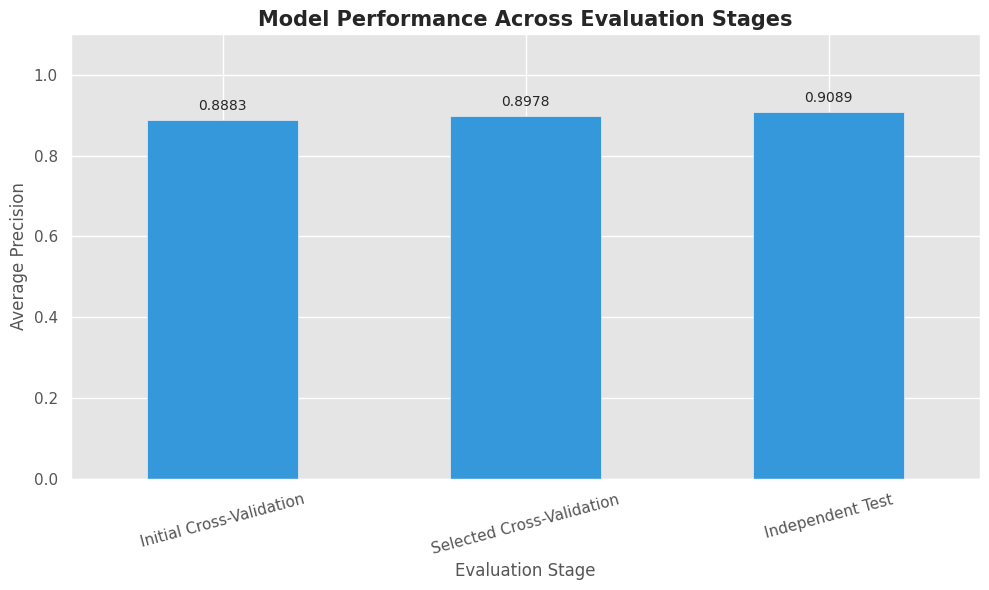

In [149]:
# Compare development and test performance
generalization_summary = pd.DataFrame({

    "Evaluation Stage": [

        "Initial Cross-Validation",
        "Selected Cross-Validation",
        "Independent Test"
    ],

    "Average Precision": [

        initial_ap,

        final_cv_ap,

        optimized_test_metrics["Average Precision"]
    ]
})

display(generalization_summary.round(4))

ax = generalization_summary.set_index(
    "Evaluation Stage"
).plot(

    kind="bar",

    figsize=(10, 6),

    color="#3498db",

    legend=False
)

for container in ax.containers:

    ax.bar_label(
        container,
        fmt="%.4f",
        padding=5
    )

plt.title(
    "Model Performance Across Evaluation Stages",
    fontsize=15,
    fontweight="bold"
)

plt.ylabel("Average Precision")
plt.xlabel("Evaluation Stage")

plt.ylim(0, 1.1)

plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

In [150]:
# Display key uncertainty estimates
print("FINAL TEST PERFORMANCE - 95% CONFIDENCE INTERVALS")

display(

    confidence_intervals_df[[

        "Metric",
        "Test Estimate",
        "95% CI Lower",
        "95% CI Upper"

    ]].round(4)
)

FINAL TEST PERFORMANCE - 95% CONFIDENCE INTERVALS


,Metric,Test Estimate,95% CI Lower,95% CI Upper
0,ROC-AUC,0.9809,0.9614,0.9963
1,Average Precision,0.9089,0.8511,0.9600
2,Recall,0.8235,0.7206,0.9118
3,Precision,0.9655,0.9138,1.0000
4,F1-score,0.8889,0.8226,0.9394
5,F2-score,0.8485,0.7609,0.9199


### 11.4 Industrial Implications

The developed framework demonstrates how operational
measurements can be transformed into machine learning
inputs for industrial condition monitoring.

Potential industrial applications include:

- Machine condition assessment.
- Automated failure risk scoring.
- Maintenance decision support.
- Operational anomaly identification.
- Sensor-based failure investigation.
- Explainable maintenance alerts.
- Manufacturing reliability analysis.

The supervised classification model provides
failure-related predictive scores, while Isolation
Forest provides a complementary perspective on
unusual operating conditions.

SHAP explanations support interpretation of model
outputs by maintenance engineers and technical teams.

The proposed architecture represents a research
prototype rather than a production-ready industrial
monitoring system.

In [151]:
# Summarize operational implications
industrial_summary = pd.DataFrame({

    "Operational Indicator": [

        "Total Test Observations",
        "Actual Machine Failures",
        "Correctly Detected Failures",
        "Missed Failures",
        "False Maintenance Alerts",
        "Failure Detection Rate (%)",
        "False Alarm Rate (%)",
        "Detected Statistical Anomalies",
        "Failures Flagged Only by Isolation Forest",
        "Non-Failures Flagged Only by Isolation Forest"
    ],

    "Result": [

        len(y_test),
        int(y_test.sum()),
        int(cm_optimized[1, 1]),
        int(cm_optimized[1, 0]),
        int(cm_optimized[0, 1]),

        round(
            optimized_test_metrics["Recall"] * 100,
            2
        ),

        round(
            optimized_test_metrics["False Positive Rate"] * 100,
            2
        ),

        int(anomaly_predictions.sum()),
        int(additional_detected_failures),
        int(additional_false_alarms)
    ]
})

display(industrial_summary)

,Operational Indicator,Result
0,Total Test Observations,2000.00
1,Actual Machine Failures,68.00
2,Correctly Detected Failures,56.00
3,Missed Failures,12.00
4,False Maintenance Alerts,2.00
5,Failure Detection Rate (%),82.35
6,False Alarm Rate (%),0.10
7,Detected Statistical Anomalies,74.00
8,Failures Flagged Only by Isolation Forest,1.00
9,Non-Failures Flagged Only by Isolation Forest,54.00


### 11.5 Project Limitations

Despite the comprehensive experimental framework,
several limitations must be considered.

#### Synthetic Dataset

The AI4I 2020 Predictive Maintenance dataset is
synthetically generated and may not fully represent
real-world industrial operating conditions.

#### Class Imbalance

Machine failure observations represent a small
proportion of the available dataset, limiting
minority-class evaluation reliability.

#### Temporal Information

The dataset does not provide sufficient longitudinal
machine histories for reliable time-to-failure
prediction or Remaining Useful Life estimation.

Consequently, the project focuses on observation-level
failure classification rather than forecasting the
timing of future failures.

#### Feature Availability

The available operational variables represent a
limited subset of measurements typically available
in industrial monitoring environments.

#### Model Selection

Repeated model selection and hyperparameter
optimization may produce optimistic development-stage
performance estimates.

#### Model Interpretability

SHAP explanations describe model behavior and do
not establish physical or causal relationships.

Engineered feature dependencies may affect
feature attribution estimates.

#### Probability Calibration

Model scores have not been explicitly calibrated
as reliable real-world failure probabilities.

#### Anomaly Detection

Statistical anomalies do not necessarily indicate
machine failures, and some failures may occur
without detectable operating abnormalities.

#### External Validation

No external industrial dataset was used to validate
the developed monitoring framework.

#### Deployment

Real-time sensor ingestion, production infrastructure,
and industrial equipment integration were not
implemented within the current project scope.

### 11.6 Future Improvements

Future development could extend the CellSense
framework through the following directions.

#### Real Industrial Data

Validate the framework using operational data
collected from real manufacturing equipment.

#### Time-Series Modeling

Incorporate historical sensor sequences and
temporal feature extraction techniques.

#### Remaining Useful Life Estimation

Develop degradation and survival models using
appropriate longitudinal failure data.

#### Advanced Anomaly Detection

Investigate additional novelty detection approaches,
including Autoencoders, One-Class SVM, and
Local Outlier Factor.

#### Probability Calibration

Evaluate calibration techniques such as Platt
scaling and isotonic regression.

#### Cost-Sensitive Maintenance

Optimize maintenance decisions using validated
costs associated with missed failures, false alarms,
downtime, and equipment replacement.

#### Real-Time Data Processing

Explore industrial communication protocols,
including MQTT and OPC UA, for sensor data ingestion.

#### Model Deployment

Develop a REST API for model inference and an
interactive dashboard for condition monitoring.

#### MLOps Integration

Introduce experiment tracking, model versioning,
automated testing, monitoring, and retraining.

#### Industrial Automation Integration

Investigate integration with PLC, SCADA, and
robotic manufacturing environments.

### 11.7 Model and Results Export

The trained supervised classification pipeline,
anomaly detection model, preprocessing components,
and experimental results are exported to support
reproducibility and future integration.

Exported artifacts include:

- Trained classification pipeline.
- Isolation Forest model.
- Anomaly preprocessing pipeline.
- PCA transformation model.
- Model configuration metadata.
- Evaluation reports.
- Statistical analysis results.
- SHAP feature importance results.
- Software dependency information.

These artifacts support reproducible analysis
and future model deployment experiments.

In [152]:
# Import artifact management libraries
from pathlib import Path

import joblib
import json
import platform
import sklearn
import xgboost
import lightgbm
import scipy
import statsmodels

# Define project export directories
EXPORT_DIR = Path("cellsense_artifacts")

MODEL_DIR = EXPORT_DIR / "models"

RESULTS_DIR = EXPORT_DIR / "results"

CONFIG_DIR = EXPORT_DIR / "config"

# Create export directories
for directory in [

    MODEL_DIR,

    RESULTS_DIR,

    CONFIG_DIR

]:

    directory.mkdir(
        parents=True,
        exist_ok=True
    )

print("Export directories created.")

print(EXPORT_DIR.resolve())

Export directories created.
/content/cellsense_artifacts


In [153]:
# Export trained supervised model pipeline
joblib.dump(

    final_pipeline,

    MODEL_DIR / "supervised_model.joblib",

    compress=3
)

# Export trained Isolation Forest
joblib.dump(

    isolation_forest,

    MODEL_DIR / "isolation_forest.joblib",

    compress=3
)

# Export anomaly preprocessing pipeline
joblib.dump(

    anomaly_preprocessor,

    MODEL_DIR / "anomaly_preprocessor.joblib",

    compress=3
)

# Export PCA transformation
joblib.dump(

    anomaly_pca,

    MODEL_DIR / "anomaly_pca.joblib",

    compress=3
)

print("All trained models exported successfully.")

All trained models exported successfully.


In [154]:
# Create model configuration metadata
model_metadata = {

    "project_name": "CellSense Advanced",

    "dataset": "AI4I 2020 Predictive Maintenance",

    "random_state": RANDOM_STATE,

    "selected_model": best_model_name,

    "feature_configuration": best_feature_set,

    "hyperparameter_configuration":
        final_configuration_type,

    "original_features": original_features,

    "selected_features": selected_features,

    "anomaly_features": anomaly_features,

    "decision_threshold":
        float(optimal_threshold),

    "hyperparameters":
        final_model.get_params(),

    "cross_validation_folds":
        N_SPLITS,

    "optimization_trials":
        len(study.trials),

    "training_observations":
        len(y_train),

    "test_observations":
        len(y_test),

    "primary_metric":
        "Average Precision",

    "anomaly_contamination":
        ANOMALY_CONTAMINATION,

    "test_metrics":
        optimized_test_metrics,

    "anomaly_detection_metrics":
        anomaly_metrics,

    "feature_engineering_version": "1.0"
}

# Convert NumPy values for JSON serialization
def json_converter(value):

    if isinstance(value, np.generic):

        return value.item()

    if isinstance(value, np.ndarray):

        return value.tolist()

    raise TypeError(
        f"Unsupported type: {type(value)}"
    )

# Save model metadata
with open(

    CONFIG_DIR / "model_metadata.json",

    "w",

    encoding="utf-8"

) as file:

    json.dump(

        model_metadata,

        file,

        indent=4,

        default=json_converter
    )

print("Model metadata exported successfully.")

Model metadata exported successfully.


In [155]:
# Define experimental results to export
result_artifacts = {

    "project_summary":
        project_summary,

    "statistical_test_results":
        mann_whitney_df,

    "categorical_test_results":
        categorical_results,

    "cross_validation_results":
        cv_fold_results,

    "cross_validation_summary":
        cv_summary_results,

    "feature_ablation_results":
        ablation_results,

    "optimization_trials":
        trials_df,

    "threshold_optimization":
        threshold_results_df,

    "test_metrics":
        test_metrics_df,

    "classification_report":
        classification_report_df,

    "confidence_intervals":
        confidence_intervals_df,

    "failure_detection_results":
        failure_detection_df,

    "shap_feature_importance":
        shap_importance_df,

    "shap_group_importance":
        feature_group_importance,

    "anomaly_metrics":
        anomaly_metrics_df,

    "anomaly_failure_results":
        anomaly_failure_df,

    "detector_comparison":
        supervised_anomaly_comparison,

    "detection_agreement":
        agreement_summary,

    "final_model_summary":
        final_performance_summary,

    "industrial_summary":
        industrial_summary
}

# Export all result tables
for artifact_name, artifact in result_artifacts.items():

    artifact.to_csv(

        RESULTS_DIR / f"{artifact_name}.csv",

        index=True
    )

print(
    f"{len(result_artifacts)} result tables "
    "exported successfully."
)

20 result tables exported successfully.


In [156]:
# Record software environment information
import matplotlib
import seaborn

from importlib.metadata import version

environment_info = {

    "Python": platform.python_version(),

    "numpy": np.__version__,

    "pandas": pd.__version__,

    "scikit-learn": sklearn.__version__,

    "scipy": scipy.__version__,

    "statsmodels": statsmodels.__version__,

    "xgboost": xgboost.__version__,

    "lightgbm": lightgbm.__version__,

    "optuna": optuna.__version__,

    "shap": shap.__version__,

    "matplotlib": matplotlib.__version__,

    "seaborn": seaborn.__version__,

    "joblib": joblib.__version__,

    "ucimlrepo": version("ucimlrepo")
}

environment_df = pd.DataFrame(

    environment_info.items(),

    columns=["Software", "Version"]
)

display(environment_df)

environment_df.to_csv(

    CONFIG_DIR / "environment.csv",

    index=False
)

# Generate requirements file
with open(

    EXPORT_DIR / "requirements.txt",

    "w",

    encoding="utf-8"

) as file:

    for package, package_version in environment_info.items():

        if package != "Python":

            file.write(

                f"{package}=={package_version}\n"
            )

print("Environment configuration exported.")

,Software,Version
0,Python,3.13.18
1,numpy,2.4.6
2,pandas,2.2.3
3,scikit-learn,1.6.1
4,scipy,1.16.3
5,statsmodels,0.15.0
6,xgboost,3.4.1
7,lightgbm,4.6.0
8,optuna,5.1.0
9,shap,0.54.1


Environment configuration exported.


In [157]:
import inspect

# Export feature engineering implementation
feature_engineering_source = (

    "import numpy as np\n"
    "import pandas as pd\n\n"

    +

    inspect.getsource(create_engineered_features)

    +

    "\n"
)

feature_engineering_path = (

    EXPORT_DIR / "feature_engineering.py"
)

feature_engineering_path.write_text(

    feature_engineering_source,

    encoding="utf-8"
)

print("Feature engineering module exported.")

Feature engineering module exported.


In [158]:
# Reload exported supervised model
loaded_supervised_model = joblib.load(

    MODEL_DIR / "supervised_model.joblib"
)

# Reload exported anomaly detector
loaded_anomaly_model = joblib.load(

    MODEL_DIR / "isolation_forest.joblib"
)

# Reload anomaly preprocessing
loaded_anomaly_preprocessor = joblib.load(

    MODEL_DIR / "anomaly_preprocessor.joblib"
)

# Verify supervised model predictions
reloaded_test_probabilities = (

    loaded_supervised_model.predict_proba(

        X_test_selected

    )[:, 1]
)

np.testing.assert_allclose(

    reloaded_test_probabilities,

    test_probabilities,

    atol=1e-8
)

# Verify anomaly detector predictions
reloaded_anomaly_data = (

    loaded_anomaly_preprocessor.transform(

        X_anomaly_test
    )
)

reloaded_anomaly_scores = (

    -loaded_anomaly_model.decision_function(

        reloaded_anomaly_data
    )
)

np.testing.assert_allclose(

    reloaded_anomaly_scores,

    anomaly_scores,

    atol=1e-8
)

print("Model serialization validation passed.")

print("Supervised model predictions verified.")

print("Anomaly detection predictions verified.")

Model serialization validation passed.
Supervised model predictions verified.
Anomaly detection predictions verified.


In [159]:
# Import exported feature engineering module
import importlib.util

module_spec = importlib.util.spec_from_file_location(

    "cellsense_feature_engineering",

    feature_engineering_path
)

feature_module = importlib.util.module_from_spec(

    module_spec
)

module_spec.loader.exec_module(feature_module)

# Simulate inference using raw input features
raw_test_input = test_df[original_features].copy()

# Apply exported feature engineering
inference_features = (

    feature_module.create_engineered_features(

        raw_test_input
    )
)

# Select features required by the trained model
inference_input = inference_features[
    selected_features
]

# Generate predictions
inference_scores = (

    loaded_supervised_model.predict_proba(

        inference_input

    )[:, 1]
)

np.testing.assert_allclose(

    inference_scores,

    test_probabilities,

    atol=1e-8
)

# Apply the fixed decision threshold
inference_predictions = (

    inference_scores >= optimal_threshold

).astype(int)

np.testing.assert_array_equal(

    inference_predictions,

    y_pred_optimized
)

print("End-to-end inference validation passed.")

End-to-end inference validation passed.


In [160]:
# Display exported artifact inventory
artifact_inventory = []

for file_path in sorted(EXPORT_DIR.rglob("*")):

    if file_path.is_file():

        artifact_inventory.append({

            "File": str(

                file_path.relative_to(EXPORT_DIR)
            ),

            "Size (KB)": round(

                file_path.stat().st_size / 1024,

                2
            )
        })

artifact_inventory_df = pd.DataFrame(

    artifact_inventory
)

display(artifact_inventory_df)

print(

    f"Total Exported Files: "

    f"{len(artifact_inventory_df)}"
)

print(

    f"Total Artifact Size: "

    f"{artifact_inventory_df['Size (KB)'].sum() / 1024:.2f} MB"
)

,File,Size (KB)
0,__pycache__/feature_engineering.cpython-313.pyc,1.16
1,config/environment.csv,0.22
2,config/model_metadata.json,4.07
3,feature_engineering.py,1.06
4,models/anomaly_pca.joblib,0.97
5,models/anomaly_preprocessor.joblib,1.86
6,models/isolation_forest.joblib,1196.86
7,models/supervised_model.joblib,153.02
8,requirements.txt,0.20
9,results/anomaly_failure_results.csv,0.28


Total Exported Files: 29
Total Artifact Size: 1.40 MB


In [161]:
# Create compressed artifact archive
import shutil

archive_path = shutil.make_archive(

    "CellSense_Advanced_Artifacts",

    "zip",

    root_dir=EXPORT_DIR.parent,

    base_dir=EXPORT_DIR.name
)

print("Artifact archive created.")

print(archive_path)

Artifact archive created.
/content/CellSense_Advanced_Artifacts.zip


In [162]:
# Download artifacts from Google Colab
from google.colab import files

files.download(

    "CellSense_Advanced_Artifacts.zip"
)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [163]:
# Generate final project report
print("=" * 70)

print("CELLSENSE ADVANCED")

print("INTELLIGENT MONITORING & PREDICTIVE MAINTENANCE")

print("=" * 70)

print("\nDATASET")

print(f"Total Observations: {len(df):,}")

print(f"Training Observations: {len(y_train):,}")

print(f"Test Observations: {len(y_test):,}")

print("\nFINAL SUPERVISED MODEL")

print(f"Algorithm: {best_model_name}")

print(f"Feature Configuration: {best_feature_set}")

print(f"Hyperparameters: {final_configuration_type}")

print(f"Decision Threshold: {optimal_threshold:.4f}")

print("\nINDEPENDENT TEST PERFORMANCE")

for metric in [

    "Accuracy",
    "Balanced Accuracy",
    "Precision",
    "Recall",
    "F1-score",
    "F2-score",
    "ROC-AUC",
    "Average Precision"

]:

    print(

        f"{metric}: "

        f"{optimized_test_metrics[metric]:.4f}"
    )

print("\nOPERATIONAL RESULTS")

print(f"Detected Failures: {cm_optimized[1, 1]}")

print(f"Missed Failures: {cm_optimized[1, 0]}")

print(f"False Alarms: {cm_optimized[0, 1]}")

print("\nEXPLAINABLE AI")

print(

    "Most Influential Feature:",

    shap_importance_df.iloc[0]["Feature"]
)

print(

    f"Explained Observations: {len(shap_sample)}"
)

print("\nANOMALY DETECTION")

print("Algorithm: Isolation Forest")

print(

    f"Detected Anomalies: "

    f"{anomaly_predictions.sum()}"
)

print(

    f"Average Precision: "

    f"{anomaly_metrics['Average Precision']:.4f}"
)

print(

    f"Recall: "

    f"{anomaly_metrics['Recall']:.4f}"
)

print("\nMODEL EXPORT")

print("Model serialization validated.")

print("End-to-end inference validated.")

print("Experimental artifacts exported.")

print("=" * 70)

print("PROJECT IMPLEMENTATION COMPLETED")

print("=" * 70)

CELLSENSE ADVANCED
INTELLIGENT MONITORING & PREDICTIVE MAINTENANCE

DATASET
Total Observations: 10,000
Training Observations: 8,000
Test Observations: 2,000

FINAL SUPERVISED MODEL
Algorithm: XGBoost
Feature Configuration: Physics-Informed
Hyperparameters: Optimized
Decision Threshold: 0.8366

INDEPENDENT TEST PERFORMANCE
Accuracy: 0.9930
Balanced Accuracy: 0.9112
Precision: 0.9655
Recall: 0.8235
F1-score: 0.8889
F2-score: 0.8485
ROC-AUC: 0.9809
Average Precision: 0.9089

OPERATIONAL RESULTS
Detected Failures: 56
Missed Failures: 12
False Alarms: 2

EXPLAINABLE AI
Most Influential Feature: Tool wear
Explained Observations: 300

ANOMALY DETECTION
Algorithm: Isolation Forest
Detected Anomalies: 74
Average Precision: 0.2286
Recall: 0.2941

MODEL EXPORT
Model serialization validated.
End-to-end inference validated.
Experimental artifacts exported.
PROJECT IMPLEMENTATION COMPLETED


### 11.8 Final Project Conclusion

CellSense Advanced presents an integrated Data Science
framework for machine failure classification and
industrial condition monitoring.

The project combines statistical reasoning,
physics-informed feature engineering, machine
learning experimentation, automated hyperparameter
optimization, explainable artificial intelligence,
and statistical anomaly detection.

A structured evaluation methodology was established
to address class imbalance, reduce data leakage,
assess model generalization, and quantify uncertainty.

The supervised classification framework investigates
failure-related patterns, while Isolation Forest
provides a complementary novelty detection approach.

SHAP-based explanations support interpretation of
global model behavior and individual predictions.

The final trained models, feature engineering
implementation, configuration metadata, and
experimental results were exported and validated
for reproducible inference.

Although the synthetic dataset and lack of temporal
machine histories limit direct industrial application,
the project provides a foundation for future
research in intelligent manufacturing, industrial
automation, and predictive maintenance.

Future extensions may incorporate real industrial
sensor data, temporal modeling, calibrated risk
estimation, real-time monitoring, and production
deployment.

---

**Project:** CellSense Advanced

**Domain:** Data Science, Machine Learning,
Industrial Automation and Predictive Maintenance

**Dataset:** AI4I 2020 Predictive Maintenance

**Project Status:** Research Prototype